## 0a. Rebuild the working folder after a full session reset

**Purpose.** A full Kaggle session reset deletes everything in `/kaggle/working`, including the downloaded
benchmark data and all saved results. This cell (1) re-downloads and verifies the data if it is missing and
(2) restores the `outputs` folder from a backup zip if one can be found, then reports what is present.

**Reading the result.** The final lines list how many models, score files and prediction files exist per source.
If these are zero, the saved results were lost and the backup zip has to be supplied (see the message printed).

In [5]:
import hashlib, subprocess, zipfile, shutil
from pathlib import Path

WORK_DIR = Path("/kaggle/working"); DATA_DIR = WORK_DIR / "csa_data"; OUT_DIR = WORK_DIR / "outputs"
ZIP_PATH = WORK_DIR / "csa_data.zip"
DATA_URL = "https://zenodo.org/records/15258451/files/csa_data.zip?download=1"
EXPECTED_MD5 = "984eabec912914e62d56d8e0073475f8"
names = ["CTRPv2", "GDSCv1", "GDSCv2", "CCLE", "gCSI"]

def md5sum(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        while block := f.read(chunk):
            h.update(block)
    return h.hexdigest()

# ---- 1. Benchmark data ----
if not (DATA_DIR / "raw_data").exists():
    if not ZIP_PATH.exists():
        subprocess.run(["wget", "-q", "-O", str(ZIP_PATH), DATA_URL], check=True)
    got = md5sum(ZIP_PATH)
    assert got == EXPECTED_MD5, f"Checksum mismatch ({got}): download incomplete. Check Internet is ON and re-run."
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(WORK_DIR)
    print("Benchmark data downloaded, verified and extracted.")
else:
    print("Benchmark data already present.")

# ---- 2. Saved results ----
def n_files(folder, pattern):
    return len(list(folder.glob(pattern))) if folder.exists() else 0

if n_files(OUT_DIR / "scores_xgb_gpu", "*_split*.csv") == 0:
    backups = [p for root in (WORK_DIR, Path("/kaggle/input")) if root.exists()
               for p in root.rglob("*.zip") if "results" in p.name.lower() and "backup" in p.name.lower()
               or p.name == "results_bundle.zip"]
    if backups:
        OUT_DIR.mkdir(exist_ok=True)
        with zipfile.ZipFile(backups[0]) as z:
            z.extractall(OUT_DIR)
        print("Restored outputs from", backups[0])
        bak = OUT_DIR / "scores_xgb_gpu" / "CTRPv2_split0.csv.bak"
        if bak.exists() and not (OUT_DIR / "scores_xgb_gpu" / "CTRPv2_split0.csv").exists():
            shutil.copy(bak, bak.with_suffix(""))
    else:
        print("No backup zip found. The saved results were lost with the session.\n"
              "Upload your downloaded results zip (Add Input / Upload dataset) and re-run this cell.")

print("\nModels per source     :", {n: n_files(OUT_DIR / "models_xgb_gpu", f"{n}_split*.json") for n in names})
print("Score files per source:", {n: n_files(OUT_DIR / "scores_xgb_gpu", f"{n}_split*.csv") for n in names})
print("Prediction files      :", {n: n_files(OUT_DIR / "predictions_xgb_gpu", f"{n}_split*.parquet") for n in names})

Benchmark data downloaded, verified and extracted.
No backup zip found. The saved results were lost with the session.
Upload your downloaded results zip (Add Input / Upload dataset) and re-run this cell.

Models per source     : {'CTRPv2': 0, 'GDSCv1': 0, 'GDSCv2': 0, 'CCLE': 0, 'gCSI': 0}
Score files per source: {'CTRPv2': 0, 'GDSCv1': 0, 'GDSCv2': 0, 'CCLE': 0, 'gCSI': 0}
Prediction files      : {'CTRPv2': 0, 'GDSCv1': 0, 'GDSCv2': 0, 'CCLE': 0, 'gCSI': 0}


In [6]:
import os, sys, json, random, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

# ----------------------------- Configuration -----------------------------
SEED = 42
WORK_DIR = Path("/kaggle/working")
DATA_DIR = WORK_DIR / "csa_data"
OUT_DIR  = WORK_DIR / "outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Public benchmark data released with Partin et al. (Briefings in Bioinformatics, 2026)
ZENODO_RECORD = "https://zenodo.org/records/15258451"
DATA_URL      = f"{ZENODO_RECORD}/files/csa_data.zip?download=1"
EXPECTED_MD5  = "984eabec912914e62d56d8e0073475f8"

# Dataset labels used throughout this work (D1 = largest)
DATASETS = {
    "D1": "CTRPv2",
    "D2": "GDSCv1",
    "D3": "GDSCv2",
    "D4": "CCLE",
    "D5": "gCSI",
}
N_SPLITS = 10          # paper uses 10 random splits per source dataset
PILOT_SPLITS = [0]     # set to list(range(N_SPLITS)) for the full run

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

set_seed()

# ----------------------------- Environment log -----------------------------
print("Python  :", platform.python_version())
print("NumPy   :", np.__version__)
print("Pandas  :", pd.__version__)
try:
    import lightgbm; print("LightGBM:", lightgbm.__version__)
except ImportError:
    print("LightGBM: not installed")
try:
    import torch; print("GPU     :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")
except ImportError:
    print("GPU     : torch not installed")

Python  : 3.13.16
NumPy   : 2.1.3
Pandas  : 2.3.3
LightGBM: 4.6.0
GPU     : Tesla T4


**Project setup: imports, configuration**

1. D****ownload and verify the benchmark data****

In [6]:
import hashlib, subprocess, zipfile, time

ZIP_PATH = WORK_DIR / "csa_data.zip"

def md5sum(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        while block := f.read(chunk):
            h.update(block)
    return h.hexdigest()

def download(max_attempts=4):
    for attempt in range(1, max_attempts + 1):
        ZIP_PATH.unlink(missing_ok=True)
        r = subprocess.run(
            ["wget", "--tries=5", "--timeout=60", "--read-timeout=60",
             "-O", str(ZIP_PATH), DATA_URL],
            capture_output=True, text=True,
        )
        size_mb = ZIP_PATH.stat().st_size / 1e6 if ZIP_PATH.exists() else 0
        ok = r.returncode == 0 and md5sum(ZIP_PATH) == EXPECTED_MD5
        print(f"attempt {attempt}: wget exit {r.returncode}, {size_mb:.1f} MB, md5 ok = {ok}")
        if ok:
            return
        time.sleep(5)
    ZIP_PATH.unlink(missing_ok=True)
    raise RuntimeError("Download kept failing. Use the manual route below.\n" + r.stderr[-500:])

if not DATA_DIR.exists():
    # Reuse an existing zip only if it is intact; otherwise re-download
    if not (ZIP_PATH.exists() and md5sum(ZIP_PATH) == EXPECTED_MD5):
        download()
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(WORK_DIR)
    print("Extracted to", WORK_DIR)
else:
    print("Data already present:", DATA_DIR)

Data already present: /kaggle/working/csa_data


2. I****nspect the data layout (what files exist, what each contains)****

In [7]:
def show_tree(root: Path, max_files_per_dir: int = 8, max_depth: int = 3):
    root = Path(root)
    for dirpath, dirnames, filenames in os.walk(root):
        depth = Path(dirpath).relative_to(root).parts
        if len(depth) > max_depth:
            continue
        indent = "  " * len(depth)
        print(f"{indent}{Path(dirpath).name}/  ({len(filenames)} files)")
        for fn in sorted(filenames)[:max_files_per_dir]:
            size_mb = (Path(dirpath) / fn).stat().st_size / 1e6
            print(f"{indent}  {fn}  [{size_mb:.1f} MB]")
        if len(filenames) > max_files_per_dir:
            print(f"{indent}  ... {len(filenames) - max_files_per_dir} more")

# The zip may extract to csa_data/ or csa_data/raw_data/ depending on release
show_tree(DATA_DIR)

csa_data/  (0 files)
  raw_data/  (5 files)
    param_log_file.txt  [0.0 MB]
    test_y_data.csv  [0.1 MB]
    train_y_data.csv  [0.7 MB]
    val_y_data.csv  [0.1 MB]
    x_data_gene_expression_scaler.gz  [0.0 MB]
    processed/  (3 files)
      test_data.pt  [15.5 MB]
      train_data.pt  [124.3 MB]
      val_data.pt  [15.5 MB]
    y_data/  (1 files)
      response.tsv  [56.1 MB]
    x_data/  (13 files)
      cancer_DNA_methylation.tsv  [130.3 MB]
      cancer_RPPA.tsv  [1.6 MB]
      cancer_copy_number.tsv  [484.4 MB]
      cancer_discretized_copy_number.tsv  [54.3 MB]
      cancer_gene_expression.tsv  [416.5 MB]
      cancer_miRNA_expression.tsv  [3.6 MB]
      cancer_mutation.parquet  [49.5 MB]
      cancer_mutation_count.tsv  [38.9 MB]
      ... 5 more
    splits/  (155 files)
      CCLE_all.txt  [0.1 MB]
      CCLE_split_0_test.txt  [0.0 MB]
      CCLE_split_0_train.txt  [0.0 MB]
      CCLE_split_0_val.txt  [0.0 MB]
      CCLE_split_1_test.txt  [0.0 MB]
      CCLE_split_1_train.t

In [8]:
# Peek at the first rows of every tabular file (headers + 3 rows), skipping splits
def peek(path: Path, n=3, max_cols=10):
    df = pd.read_csv(path, sep="\t", nrows=n)
    print(f"\n{path.relative_to(DATA_DIR)}   columns={df.shape[1]}")
    print(df.iloc[:, :max_cols].to_string(index=False))

for p in sorted(DATA_DIR.rglob("*.tsv")):
    peek(p)

# Show one split file so we know whether it stores row indices or IDs
split_files = sorted(DATA_DIR.rglob("*split_0_train.txt"))
print("\nSplit files found:", [p.name for p in split_files])
if split_files:
    print(split_files[0].name, "->", open(split_files[0]).read().split()[:5])


raw_data/x_data/cancer_DNA_methylation.tsv   columns=19607
 Unnamed: 0 LOC100288069_1_714068_715068 LINC01128_1_761970_762970 LINC01128_1_762177_763177 SAMD11_1_860120_861120 NOC2L_1_894679_895679 KLHL17_1_894966_895966 PLEKHN1_1_900876_901876 PERM1_1_917497_918497 HES4_1_935552_936552
        NaN                    100288069                    643837                    643837                 148398                 26155                 339451                   84069                 84808                57801
        NaN                          NaN           ENSG00000228794           ENSG00000228794        ENSG00000187634       ENSG00000188976        ENSG00000187961         ENSG00000187583       ENSG00000187642      ENSG00000188290
        NaN                 LOC100288069                 LINC01128                 LINC01128                 SAMD11                 NOC2L                 KLHL17                 PLEKHN1                 PERM1                 HES4

raw_data/x_data/cancer_RPPA

In [9]:
from pathlib import Path
import pandas as pd
from IPython.display import display

WORK_DIR = Path("/kaggle/working")
OUT_DIR = WORK_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)

# See what the zip actually extracted to, then set DATA_DIR accordingly
print(sorted(p.name for p in WORK_DIR.iterdir()))

['.virtual_documents', 'csa_data', 'csa_data.zip', 'csa_pipeline.py', 'outputs', 'results_bundle.zip']


Load response data and verify it against Table 1 of the paper

In [10]:
RAW = DATA_DIR / "raw_data"

resp = pd.read_csv(RAW / "y_data" / "response.tsv", sep="\t")
print("response.tsv shape:", resp.shape)
print("Sources found     :", sorted(resp["source"].unique()))

# Table 1 of Partin et al. (drugs, cell lines, responses)
TABLE1 = {
    "CCLE":   (24,  411,   9519),
    "CTRPv2": (494, 720, 286665),
    "gCSI":   (16,  312,   4941),
    "GDSCv1": (294, 546, 171940),
    "GDSCv2": (168, 470, 114644),
}
missing = set(TABLE1) - set(resp["source"].unique())
assert not missing, f"Source names differ from expected: {missing}"

rows = []
for src, (nd, nc, nr) in TABLE1.items():
    s = resp[resp["source"] == src]
    rows.append({
        "source": src,
        "drugs": s["improve_chem_id"].nunique(),           "paper_drugs": nd,
        "cell_lines": s["improve_sample_id"].nunique(),    "paper_cells": nc,
        "responses": len(s),                               "paper_responses": nr,
        "auc_missing": int(s["auc"].isna().sum()),
        "duplicate_pairs": int(s.duplicated(["improve_sample_id", "improve_chem_id"]).sum()),
    })
table1_check = pd.DataFrame(rows).set_index("source")
display(table1_check)
table1_check.to_csv(OUT_DIR / "table1_verification.csv")

response.tsv shape: (587709, 14)
Sources found     : ['CCLE', 'CTRPv2', 'GDSCv1', 'GDSCv2', 'gCSI']


,drugs,paper_drugs,cell_lines,paper_cells,responses,paper_responses,auc_missing,duplicate_pairs
source,,,,,,,,
CCLE,24,24,411,411,9519,9519,0,0
CTRPv2,494,494,720,720,286665,286665,0,5357
gCSI,16,16,312,312,4941,4941,0,0
GDSCv1,294,294,546,546,171940,171940,0,35741
GDSCv2,168,168,470,470,114644,114644,0,48291


***5. Load the predefined train/validation/test splits and verify them***

In [11]:
SPLIT_DIR = RAW / "splits"

def read_ids(path):
    with open(path) as f:
        return [int(x) for x in f.read().split()]

splits = {}   # (source_name, split_id, part) -> list of row ids into `resp`
for name in DATASETS.values():
    splits[(name, None, "all")] = read_ids(SPLIT_DIR / f"{name}_all.txt")
    for k in range(N_SPLITS):
        for part in ("train", "val", "test"):
            splits[(name, k, part)] = read_ids(SPLIT_DIR / f"{name}_split_{k}_{part}.txt")

# ---- Sanity checks ----
report = []
for name in DATASETS.values():
    all_ids = splits[(name, None, "all")]
    assert resp.index.isin(all_ids).any()
    assert set(resp.loc[all_ids, "source"]) == {name}, f"{name}_all.txt points to other sources"
    for k in range(N_SPLITS):
        tr, va, te = (set(splits[(name, k, p)]) for p in ("train", "val", "test"))
        assert not (tr & va) and not (tr & te) and not (va & te), f"{name} split {k} overlaps"
        assert (tr | va | te) <= set(all_ids)
    k = 0
    report.append({"source": name, "all": len(all_ids),
                   "train": len(splits[(name, k, 'train')]),
                   "val":   len(splits[(name, k, 'val')]),
                   "test":  len(splits[(name, k, 'test')])})
display(pd.DataFrame(report).set_index("source"))
print("All split checks passed.")

,all,train,val,test
source,,,,
CTRPv2,286665,229333,28666,28666
GDSCv1,171940,137552,17194,17194
GDSCv2,114644,91716,11464,11464
CCLE,9519,7616,952,951
gCSI,4941,3953,494,494


All split checks passed.


***5. Measure drug, cell-line and drug-cell pair overlap between datasets***

In [12]:
names = list(DATASETS.values())
key = resp["improve_sample_id"] + "|" + resp["improve_chem_id"]

drugs  = {n: set(resp.loc[resp.source == n, "improve_chem_id"])  for n in names}
cells  = {n: set(resp.loc[resp.source == n, "improve_sample_id"]) for n in names}
pairs  = {n: set(key[resp.source == n])                          for n in names}

def coverage_matrix(sets):
    """Row = source (trained on), column = target. Value = share of the
    target's items that also appear in the source."""
    m = pd.DataFrame(index=names, columns=names, dtype=float)
    for s in names:
        for t in names:
            m.loc[s, t] = len(sets[t] & sets[s]) / len(sets[t])
    m.index.name, m.columns.name = "source (train)", "target (test)"
    return m

drug_cov, cell_cov, pair_cov = map(coverage_matrix, (drugs, cells, pairs))
for title, m in [("Drug coverage", drug_cov), ("Cell-line coverage", cell_cov),
                 ("Drug-cell PAIR overlap (leakage risk)", pair_cov)]:
    print(f"\n{title}  (share of target also present in source)")
    display(m.round(3))

drug_cov.to_csv(OUT_DIR / "coverage_drug.csv")
cell_cov.to_csv(OUT_DIR / "coverage_cell.csv")
pair_cov.to_csv(OUT_DIR / "coverage_pair.csv")


Drug coverage  (share of target also present in source)


target (test),CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
source (train),,,,,
CTRPv2,1.000,0.384,0.429,0.708,0.750
GDSCv1,0.229,1.000,0.458,0.667,0.875
GDSCv2,0.146,0.262,1.000,0.500,0.812
CCLE,0.034,0.054,0.071,1.000,0.375
gCSI,0.024,0.048,0.077,0.250,1.000



Cell-line coverage  (share of target also present in source)


target (test),CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
source (train),,,,,
CTRPv2,1.000,0.905,0.902,0.925,0.936
GDSCv1,0.686,1.000,1.000,0.745,0.853
GDSCv2,0.589,0.861,1.000,0.679,0.766
CCLE,0.528,0.560,0.594,1.000,0.750
gCSI,0.406,0.487,0.509,0.569,1.000



Drug-cell PAIR overlap (leakage risk)  (share of target also present in source)


target (test),CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
source (train),,,,,
CTRPv2,1.000,0.300,0.314,0.624,0.632
GDSCv1,0.145,1.000,0.352,0.306,0.460
GDSCv2,0.074,0.171,1.000,0.317,0.595
CCLE,0.021,0.021,0.045,1.000,0.265
gCSI,0.011,0.017,0.044,0.138,1.000


> >6. Load features: cancer gene expression and drug Mordred descriptors 

In [13]:
import csv

OMICS_FILE = "cancer_gene_expression.tsv"
DRUG_FILE  = "drug_mordred.tsv"
N_GENES    = 1000   # most variable genes kept (deviation from full set; see note below)

def load_omics(path):
    """Read an omics table, skipping the metadata rows (Entrez ID, symbol) under the header."""
    with open(path) as f:
        reader = csv.reader(f, delimiter="\t")
        next(reader)
        k = 0
        for row in reader:
            if row[0] == "":
                k += 1
            else:
                break
    df = pd.read_csv(path, sep="\t", index_col=0, skiprows=range(1, 1 + k))
    return df.apply(pd.to_numeric, errors="coerce").astype(np.float32)

used_cells = set(resp["improve_sample_id"])
used_drugs = set(resp["improve_chem_id"])

omics = load_omics(RAW / "x_data" / OMICS_FILE)
omics = omics.loc[omics.index.isin(used_cells)]
# Label-free feature selection (uses no response values, so no leakage)
top = omics.var(axis=0).nlargest(N_GENES).index
omics = omics[top]
omics.columns = ["ge." + c for c in omics.columns]

drug = pd.read_csv(RAW / "x_data" / DRUG_FILE, sep="\t", index_col=0)
drug = drug.apply(pd.to_numeric, errors="coerce").astype(np.float32)
drug = drug.loc[drug.index.isin(used_drugs)]
drug = drug.loc[:, drug.nunique(dropna=True) > 1]     # drop constant descriptors

print("Omics :", omics.shape, "| Drug:", drug.shape)

# Coverage check: every response row must have both feature vectors
for n in names:
    s = resp[resp.source == n]
    miss_c = (~s["improve_sample_id"].isin(omics.index)).mean()
    miss_d = (~s["improve_chem_id"].isin(drug.index)).mean()
    print(f"{n:7s} rows without cell features: {miss_c:.2%} | without drug features: {miss_d:.2%}")

pd.Series(omics.columns).to_csv(OUT_DIR / "selected_gene_features.csv", index=False)

Omics : (785, 1000) | Drug: (749, 1397)
CTRPv2  rows without cell features: 0.00% | without drug features: 0.00%
GDSCv1  rows without cell features: 0.00% | without drug features: 0.00%
GDSCv2  rows without cell features: 0.00% | without drug features: 0.00%
CCLE    rows without cell features: 0.00% | without drug features: 0.00%
gCSI    rows without cell features: 0.00% | without drug features: 0.00%


7. > ******Q**uantify replicate-pair overlap within splits and across datasets (row level)> 

In [14]:
def split_ids(name, k, part):
    return splits[(name, k, part)]

# (a) Within-dataset: share of TEST rows whose drug-cell pair also occurs in TRAIN
within = []
for name in names:
    for k in range(N_SPLITS):
        tr_pairs = set(key.loc[split_ids(name, k, "train")])
        te_pairs = key.loc[split_ids(name, k, "test")]
        within.append({"dataset": name, "split": k, "test_pair_seen_in_train": te_pairs.isin(tr_pairs).mean()})
within = pd.DataFrame(within)
within_summary = within.groupby("dataset")["test_pair_seen_in_train"].agg(["mean", "std"]).round(4)
print("Within-dataset replicate overlap (train -> test), mean over 10 splits")
display(within_summary)

# (b) Cross-dataset (split 0): share of target rows whose pair occurs in the source TRAIN set
K0 = 0
cross = pd.DataFrame(index=names, columns=names, dtype=float)
for s in names:
    s_pairs = set(key.loc[split_ids(s, K0, "train")])
    for t in names:
        t_rows = split_ids(t, K0, "test") if t == s else splits[(t, None, "all")]
        cross.loc[s, t] = key.loc[t_rows].isin(s_pairs).mean()
cross.index.name, cross.columns.name = "source (train)", "target (rows evaluated)"
print("\nShare of evaluated target ROWS whose pair was in the source training set (split 0)")
display(cross.round(3))

within_summary.to_csv(OUT_DIR / "overlap_within_dataset.csv")
cross.to_csv(OUT_DIR / "overlap_cross_dataset_rows.csv")

Within-dataset replicate overlap (train -> test), mean over 10 splits


,mean,std
dataset,,
CCLE,0.0000,0.0000
CTRPv2,0.0295,0.0007
GDSCv1,0.3131,0.0034
GDSCv2,0.5434,0.0052
gCSI,0.0000,0.0000



Share of evaluated target ROWS whose pair was in the source training set (split 0)


target (rows evaluated),CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
source (train),,,,,
CTRPv2,0.029,0.259,0.277,0.500,0.515
GDSCv1,0.123,0.317,0.347,0.267,0.386
GDSCv2,0.064,0.162,0.550,0.280,0.530
CCLE,0.017,0.022,0.051,0.000,0.210
gCSI,0.009,0.014,0.053,0.111,0.000


***8. Build model input matrices and the evaluation metrics***

In [15]:
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import r2_score, mean_squared_error

CROSS_TARGET_ROWS = "all"     # "all" = whole target dataset; check against paper Methods

omics_np = omics.to_numpy(dtype=np.float32)
drug_np  = drug.to_numpy(dtype=np.float32)
omics_pos = {c: i for i, c in enumerate(omics.index)}
drug_pos  = {d: i for i, d in enumerate(drug.index)}
FEATURE_NAMES = list(omics.columns) + list(drug.columns)

def make_xy(row_ids):
    d = resp.loc[row_ids, ["improve_sample_id", "improve_chem_id", "auc"]]
    ci = d["improve_sample_id"].map(omics_pos).to_numpy()
    di = d["improve_chem_id"].map(drug_pos).to_numpy()
    X = np.hstack([omics_np[ci], drug_np[di]])
    y = d["auc"].to_numpy(dtype=np.float32)
    return X, y, d

def score(y_true, y_pred):
    return {
        "r2":   r2_score(y_true, y_pred),
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "pcc":  float(pearsonr(y_true, y_pred)[0]),
        "scc":  float(spearmanr(y_true, y_pred)[0]),
        "n":    int(len(y_true)),
    }

# Quick shape test
Xt, yt, dt = make_xy(split_ids("CCLE", 0, "train")[:5])
print(Xt.shape, yt[:3], len(FEATURE_NAMES))

(5, 2397) [0.7153 0.9579 0.413 ] 2397


9. Pilot: train LightGBM on one source (CCLE, split 0) and test on all five datasets

In [16]:
import time, lightgbm as lgb
SEED=42
LGB_PARAMS = dict(
    objective="regression", n_estimators=2000, learning_rate=0.05,
    num_leaves=63, subsample=0.8, subsample_freq=1, colsample_bytree=0.5,
    n_jobs=-1, random_state=SEED, verbose=-1,
)

def train_source(source, k):
    Xtr, ytr, _ = make_xy(split_ids(source, k, "train"))
    Xva, yva, _ = make_xy(split_ids(source, k, "val"))
    model = lgb.LGBMRegressor(**LGB_PARAMS)
    model.fit(Xtr, ytr, eval_set=[(Xva, yva)],
              callbacks=[lgb.early_stopping(50, verbose=False)])
    return model

def evaluate_source(model, source, k):
    results, preds = [], []
    for target in names:
        rows = split_ids(target, k, "test") if target == source else splits[(target, None, "all")]
        X, y, meta = make_xy(rows)
        p = model.predict(X)
        results.append({"source": source, "target": target, "split": k, **score(y, p)})
        out = meta.reset_index().rename(columns={"index": "row_id"})
        out["source"], out["target"], out["split"], out["y_pred"] = source, target, k, p
        preds.append(out)
    return results, pd.concat(preds, ignore_index=True)

t0 = time.time()
model = train_source("CCLE", 0)
print(f"trained in {time.time()-t0:.0f}s, best iteration = {model.best_iteration_}")
res, preds = evaluate_source(model, "CCLE", 0)
pilot = pd.DataFrame(res)
display(pilot.round(3))

pilot.to_csv(OUT_DIR / "pilot_CCLE_split0_scores.csv", index=False)
preds.to_parquet(OUT_DIR / "pilot_CCLE_split0_predictions.parquet", index=False)
print(f"total {time.time()-t0:.0f}s")

trained in 40s, best iteration = 532


,source,target,split,r2,rmse,pcc,scc,n
0,CCLE,CTRPv2,0,-0.837,0.196,0.165,0.087,286665
1,CCLE,GDSCv1,0,-0.306,0.187,0.149,0.064,171940
2,CCLE,GDSCv2,0,-0.365,0.179,0.252,0.128,114644
3,CCLE,CCLE,0,0.812,0.071,0.902,0.819,951
4,CCLE,gCSI,0,0.078,0.182,0.442,0.389,4941


total 61s


10. Full run: train one LightGBM per source and test on all five datasets (resumable)

In [17]:
import subprocess
import xgboost as xgb

print("XGBoost:", xgb.__version__)
print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,memory.used", "--format=csv"],
                     capture_output=True, text=True).stdout)

# Tiny test: train 5 trees on the GPU
_X = np.random.rand(1000, 20).astype(np.float32); _y = np.random.rand(1000).astype(np.float32)
_m = xgb.XGBRegressor(n_estimators=5, device="cuda", tree_method="hist").fit(_X, _y)
print("GPU training test passed.")

XGBoost: 3.4.1
name, memory.total [MiB], memory.used [MiB]
Tesla T4, 15360 MiB, 3 MiB
Tesla T4, 15360 MiB, 3 MiB

GPU training test passed.


In [18]:
import time, xgboost as xgb

MODEL_TAG    = "xgb_gpu"
RUN_SPLITS   = [0]                                              # extend to list(range(10)) later
SOURCE_ORDER = ["CCLE", "gCSI", "GDSCv2", "GDSCv1", "CTRPv2"]   # smallest -> largest
CHUNK        = 50_000

XGB_PARAMS = dict(
    n_estimators=2000, learning_rate=0.05, max_depth=6,
    subsample=0.8, colsample_bytree=0.5, min_child_weight=1,
    tree_method="hist", device="cuda",
    objective="reg:squarederror", eval_metric="rmse",
    early_stopping_rounds=50, random_state=SEED, verbosity=0,
)

RES_DIR   = OUT_DIR / f"scores_{MODEL_TAG}";      RES_DIR.mkdir(exist_ok=True)
PRED_DIR  = OUT_DIR / f"predictions_{MODEL_TAG}"; PRED_DIR.mkdir(exist_ok=True)
MODEL_DIR = OUT_DIR / f"models_{MODEL_TAG}";      MODEL_DIR.mkdir(exist_ok=True)

def train_source(source, k):
    Xtr, ytr, _ = make_xy(split_ids(source, k, "train"))
    Xva, yva, _ = make_xy(split_ids(source, k, "val"))
    model = xgb.XGBRegressor(**XGB_PARAMS)
    model.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    del Xtr, Xva
    return model

def predict_chunked(model, rows):
    booster = model.get_booster()
    rng = (0, model.best_iteration + 1)          # use only trees up to the best iteration
    ys, ps, metas = [], [], []
    for i in range(0, len(rows), CHUNK):
        X, y, meta = make_xy(rows[i:i + CHUNK])
        ps.append(booster.inplace_predict(X, iteration_range=rng))
        ys.append(y); metas.append(meta)
        del X
    return np.concatenate(ys), np.concatenate(ps), pd.concat(metas)

def evaluate_source(model, source, k):
    results, preds = [], []
    for target in names:
        rows = split_ids(target, k, "test") if target == source else splits[(target, None, "all")]
        y, p, meta = predict_chunked(model, rows)
        results.append({"source": source, "target": target, "split": k, **score(y, p)})
        out = meta.reset_index().rename(columns={"index": "row_id"})
        out["source"], out["target"], out["split"], out["y_pred"] = source, target, k, p
        preds.append(out)
    return pd.DataFrame(results), pd.concat(preds, ignore_index=True)

timing = []
for k in RUN_SPLITS:
    for source in SOURCE_ORDER:
        score_file = RES_DIR / f"{source}_split{k}.csv"
        if score_file.exists():
            print(f"[skip] {source} split {k} already done")
            continue
        t0 = time.time()
        model = train_source(source, k)
        t_train = time.time() - t0
        scores_df, preds_df = evaluate_source(model, source, k)
        model.save_model(str(MODEL_DIR / f"{source}_split{k}.json"))
        preds_df.to_parquet(PRED_DIR / f"{source}_split{k}.parquet", index=False)
        scores_df.to_csv(score_file, index=False)            # written last = marks "done"
        timing.append({"source": source, "split": k, "train_s": round(t_train),
                       "total_s": round(time.time() - t0), "best_iter": model.best_iteration})
        print(f"[done] {source} split {k}: train {t_train:.0f}s, total {time.time()-t0:.0f}s, "
              f"best_iter {model.best_iteration}")
        display(scores_df.round(3))
        del model, scores_df, preds_df

pd.DataFrame(timing).to_csv(OUT_DIR / f"timing_{MODEL_TAG}.csv", index=False)

[skip] CCLE split 0 already done
[skip] gCSI split 0 already done
[skip] GDSCv2 split 0 already done
[skip] GDSCv1 split 0 already done
[done] CTRPv2 split 0: train 236s, total 251s, best_iter 1999


,source,target,split,r2,rmse,pcc,scc,n
0,CTRPv2,CTRPv2,0,0.803,0.064,0.896,0.845,28666
1,CTRPv2,GDSCv1,0,0.255,0.141,0.523,0.415,171940
2,CTRPv2,GDSCv2,0,0.456,0.113,0.684,0.559,114644
3,CTRPv2,CCLE,0,0.560,0.107,0.766,0.625,9519
4,CTRPv2,gCSI,0,0.501,0.134,0.726,0.720,4941



R2 (split 0)


tested on,CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
trained on,,,,,
CTRPv2,0.803,0.255,0.456,0.560,0.501
GDSCv1,-0.012,0.697,0.356,0.588,0.516
GDSCv2,-0.156,0.153,0.780,0.197,0.525
CCLE,-1.316,-0.550,-0.560,0.811,0.097
gCSI,-1.067,-0.519,-0.417,-0.100,0.765



RMSE (split 0)


tested on,CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
trained on,,,,,
CTRPv2,0.064,0.141,0.113,0.107,0.134
GDSCv1,0.145,0.090,0.123,0.103,0.132
GDSCv2,0.155,0.151,0.073,0.144,0.130
CCLE,0.220,0.204,0.191,0.072,0.180
gCSI,0.208,0.202,0.182,0.169,0.089



PCC (split 0)


tested on,CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
trained on,,,,,
CTRPv2,0.896,0.523,0.684,0.766,0.726
GDSCv1,0.436,0.835,0.651,0.773,0.769
GDSCv2,0.343,0.436,0.883,0.497,0.740
CCLE,0.129,0.109,0.192,0.901,0.441
gCSI,0.083,0.128,0.295,0.319,0.875



SCC (split 0)


tested on,CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
trained on,,,,,
CTRPv2,0.845,0.415,0.559,0.625,0.720
GDSCv1,0.261,0.772,0.491,0.602,0.766
GDSCv2,0.244,0.311,0.805,0.384,0.712
CCLE,0.071,0.055,0.115,0.816,0.400
gCSI,-0.003,0.075,0.186,0.199,0.868


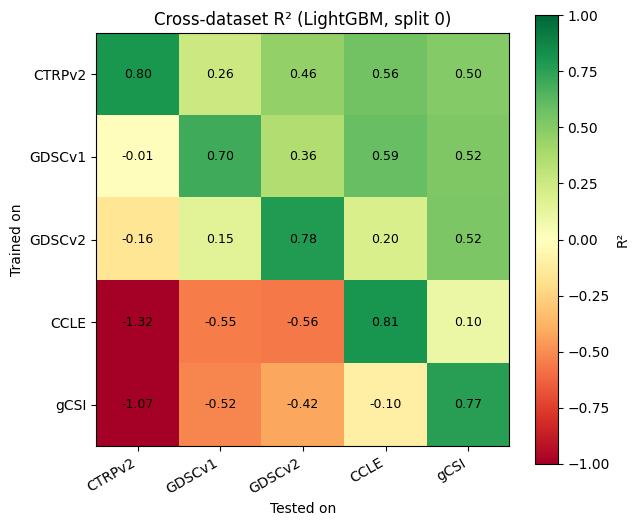

In [19]:
import matplotlib.pyplot as plt

all_scores = pd.concat([pd.read_csv(f) for f in sorted(RES_DIR.glob("*_split*.csv"))], ignore_index=True)
all_scores.to_csv(OUT_DIR / "all_scores_long.csv", index=False)

def matrix(metric, split=0):
    m = (all_scores[all_scores.split == split]
         .pivot(index="source", columns="target", values=metric)
         .reindex(index=names, columns=names))
    m.index.name, m.columns.name = "trained on", "tested on"
    return m

matrices = {m: matrix(m) for m in ["r2", "rmse", "pcc", "scc"]}
for m, df in matrices.items():
    print(f"\n{m.upper()} (split 0)")
    display(df.round(3))
    df.to_csv(OUT_DIR / f"matrix_{m}_split0.csv")

# Heatmap of R^2
M = matrices["r2"]
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(M.values.astype(float), cmap="RdYlGn", vmin=-1, vmax=1)
ax.set_xticks(range(5)); ax.set_xticklabels(M.columns, rotation=30, ha="right")
ax.set_yticks(range(5)); ax.set_yticklabels(M.index)
ax.set_xlabel("Tested on"); ax.set_ylabel("Trained on")
for i in range(5):
    for j in range(5):
        v = M.values[i, j]
        ax.text(j, i, "" if pd.isna(v) else f"{v:.2f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, label="R²")
ax.set_title("Cross-dataset R² (LightGBM, split 0)")
plt.tight_layout()
plt.savefig(OUT_DIR / "matrix_r2_split0.png", dpi=200)
plt.show()

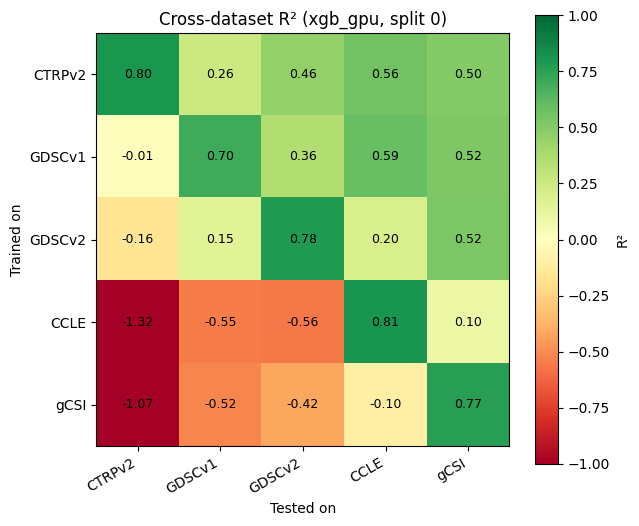

Saved: ['matrix_pcc_xgb_gpu_split0.csv', 'matrix_r2_xgb_gpu_split0.csv', 'matrix_r2_xgb_gpu_split0.pdf', 'matrix_r2_xgb_gpu_split0.png', 'matrix_r2_xgb_gpu_split0.svg', 'matrix_rmse_xgb_gpu_split0.csv', 'matrix_scc_xgb_gpu_split0.csv']
Zip   : /kaggle/working/results_bundle.zip


In [20]:
import shutil

FIG_DIR = OUT_DIR / "figures"; FIG_DIR.mkdir(exist_ok=True)

# Re-draw the R² heatmap and save it in three formats
M = matrices["r2"]
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(M.values.astype(float), cmap="RdYlGn", vmin=-1, vmax=1)
ax.set_xticks(range(5)); ax.set_xticklabels(M.columns, rotation=30, ha="right")
ax.set_yticks(range(5)); ax.set_yticklabels(M.index)
ax.set_xlabel("Tested on"); ax.set_ylabel("Trained on")
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{M.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, label="R²")
ax.set_title(f"Cross-dataset R² ({MODEL_TAG}, split 0)")
plt.tight_layout()
for ext in ("png", "pdf", "svg"):
    fig.savefig(FIG_DIR / f"matrix_r2_{MODEL_TAG}_split0.{ext}", dpi=300)
plt.show()

# Save the numbers behind every matrix
for m, df in matrices.items():
    df.to_csv(FIG_DIR / f"matrix_{m}_{MODEL_TAG}_split0.csv")

# Zip everything small enough to download (skip large prediction files if you prefer)
shutil.make_archive(str(WORK_DIR / "results_bundle"), "zip", OUT_DIR)
print("Saved:", sorted(p.name for p in FIG_DIR.iterdir()))
print("Zip   :", WORK_DIR / "results_bundle.zip")

## 13. Generalisation gap: how much performance is lost when a model changes dataset

**Purpose.** The 5 × 5 matrix reports raw cross-dataset performance. This cell turns it into a
*relative* measure: how much worse is a model on a target dataset than on its own held-out test data?

**Definitions.** For source *s* and target *t* (s ≠ t), averaged over the available splits:
- `r2_gap = R²(s→s) − R²(s→t)`: absolute loss in R².
- `r2_relative_drop = r2_gap / R²(s→s)`: loss as a share of home performance.
- `worse_than_mean = R²(s→t) < 0`: the model predicts worse than the target's own mean response.

**Inputs.** `all_scores` (created in Section 11).  **Outputs.** `generalisation_gap.csv`.

**Note.** Verify these definitions against the generalisation metrics in the baseline paper before reporting.

In [21]:
agg = (all_scores.groupby(["source", "target"])[["r2", "rmse", "pcc", "scc"]]
       .mean().reset_index())
home = agg[agg.source == agg.target].set_index("source")

rows = []
for _, r in agg[agg.source != agg.target].iterrows():
    h = home.loc[r.source]
    rows.append({
        "source": r.source, "target": r.target,
        "r2_within": h.r2, "r2_cross": r.r2,
        "r2_gap": h.r2 - r.r2,
        "r2_relative_drop": (h.r2 - r.r2) / h.r2,
        "pcc_within": h.pcc, "pcc_cross": r.pcc, "pcc_gap": h.pcc - r.pcc,
        "worse_than_mean": bool(r.r2 < 0),
    })
gap = pd.DataFrame(rows).sort_values("r2_gap", ascending=False).reset_index(drop=True)

print("All 20 cross-dataset pairs, largest loss first")
display(gap.round(3))
print("\nR² gap as a matrix (rows = trained on, columns = tested on)")
display(gap.pivot(index="source", columns="target", values="r2_gap")
        .reindex(index=names, columns=names).round(3))

gap.to_csv(OUT_DIR / "generalisation_gap.csv", index=False)

All 20 cross-dataset pairs, largest loss first


,source,target,r2_within,r2_cross,r2_gap,r2_relative_drop,pcc_within,pcc_cross,pcc_gap,worse_than_mean
0,CCLE,CTRPv2,0.811,-1.316,2.128,2.622,0.901,0.129,0.772,True
1,gCSI,CTRPv2,0.765,-1.067,1.833,2.394,0.875,0.083,0.792,True
2,CCLE,GDSCv2,0.811,-0.560,1.371,1.690,0.901,0.192,0.710,True
3,CCLE,GDSCv1,0.811,-0.550,1.362,1.678,0.901,0.109,0.792,True
4,gCSI,GDSCv1,0.765,-0.519,1.284,1.677,0.875,0.128,0.747,True
5,gCSI,GDSCv2,0.765,-0.417,1.182,1.545,0.875,0.295,0.580,True
6,GDSCv2,CTRPv2,0.780,-0.156,0.936,1.201,0.883,0.343,0.540,True
7,gCSI,CCLE,0.765,-0.100,0.865,1.130,0.875,0.319,0.556,True
8,CCLE,gCSI,0.811,0.097,0.715,0.881,0.901,0.441,0.460,False
9,GDSCv1,CTRPv2,0.697,-0.012,0.709,1.017,0.835,0.436,0.399,True



R² gap as a matrix (rows = trained on, columns = tested on)


target,CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
source,,,,,
CTRPv2,NaN,0.548,0.347,0.243,0.302
GDSCv1,0.709,NaN,0.342,0.109,0.182
GDSCv2,0.936,0.627,NaN,0.582,0.255
CCLE,2.128,1.362,1.371,NaN,0.715
gCSI,1.833,1.284,1.182,0.865,NaN


In [22]:
from pathlib import Path
for p in sorted(Path("/kaggle/working").rglob("*")):
    if p.is_file() and p.suffix in {".csv", ".parquet", ".pkl"} and "raw_data" not in str(p):
        print(p, round(p.stat().st_size / 1e6, 1), "MB")

/kaggle/working/outputs/all_scores_long.csv 0.0 MB
/kaggle/working/outputs/coverage_cell.csv 0.0 MB
/kaggle/working/outputs/coverage_drug.csv 0.0 MB
/kaggle/working/outputs/coverage_pair.csv 0.0 MB
/kaggle/working/outputs/domain_shift_auc.csv 0.0 MB
/kaggle/working/outputs/figures/matrix_pcc_xgb_gpu_split0.csv 0.0 MB
/kaggle/working/outputs/figures/matrix_r2_xgb_gpu_split0.csv 0.0 MB
/kaggle/working/outputs/figures/matrix_rmse_xgb_gpu_split0.csv 0.0 MB
/kaggle/working/outputs/figures/matrix_scc_xgb_gpu_split0.csv 0.0 MB
/kaggle/working/outputs/generalisation_gap.csv 0.0 MB
/kaggle/working/outputs/matrix_pcc_split0.csv 0.0 MB
/kaggle/working/outputs/matrix_r2_split0.csv 0.0 MB
/kaggle/working/outputs/matrix_rmse_split0.csv 0.0 MB
/kaggle/working/outputs/matrix_scc_split0.csv 0.0 MB
/kaggle/working/outputs/overlap_cross_dataset_rows.csv 0.0 MB
/kaggle/working/outputs/overlap_within_dataset.csv 0.0 MB
/kaggle/working/outputs/pilot_CCLE_split0_predictions.parquet 8.6 MB
/kaggle/working/out

In [23]:
from pathlib import Path
W = Path("/kaggle/working")
print("exists:", W.exists())
for p in sorted(W.iterdir()):
    print(p.name, "(dir)" if p.is_dir() else f"{p.stat().st_size/1e6:.1f} MB")

exists: True
.virtual_documents (dir)
csa_data (dir)
csa_data.zip 288.6 MB
csa_pipeline.py 0.0 MB
outputs (dir)
results_bundle.zip 33.4 MB


In [24]:
%%writefile /kaggle/working/csa_pipeline.py
import os, sys, time, hashlib, subprocess, zipfile
from pathlib import Path
import numpy as np, pandas as pd
from scipy.stats import pearsonr, spearmanr

SEED = 42
WORK_DIR = Path("/kaggle/working")
OUT_DIR = WORK_DIR / "outputs"; OUT_DIR.mkdir(exist_ok=True)
(OUT_DIR / "jobs").mkdir(exist_ok=True)
DATA_URL = "https://zenodo.org/records/15258451/files/csa_data.zip?download=1"
EXPECTED_MD5 = "984eabec912914e62d56d8e0073475f8"
ZIP_PATH = WORK_DIR / "csa_data.zip"
DRUG_KEY = "mordred"          # use "ecfp" for fingerprints; must match your earlier runs
N_SPLITS = 10

def md5sum(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        while b := f.read(chunk):
            h.update(b)
    return h.hexdigest()

def find_data_dir():
    hits = [p.parent for p in WORK_DIR.rglob("raw_data") if p.is_dir()]
    return hits[0] if hits else None

def ensure_data():
    d = find_data_dir()
    if d: return d
    for attempt in range(4):
        ZIP_PATH.unlink(missing_ok=True)
        subprocess.run(["wget", "--tries=5", "--timeout=60", "-O", str(ZIP_PATH), DATA_URL],
                       capture_output=True)
        if ZIP_PATH.exists() and md5sum(ZIP_PATH) == EXPECTED_MD5: break
    else:
        raise RuntimeError("Download failed 4 times; upload the zip as a Kaggle dataset instead.")
    with zipfile.ZipFile(ZIP_PATH) as z: z.extractall(WORK_DIR)
    return find_data_dir()

def pick(folder, *kw):
    f = [p for p in folder.iterdir() if all(k in p.name.lower() for k in kw)]
    if not f: raise FileNotFoundError(f"{kw} not in {folder}")
    return f[0]

def load_all():
    data_dir = ensure_data(); raw = data_dir / "raw_data"
    resp = pd.read_csv(raw / "y_data" / "response.tsv", sep="\t").reset_index(drop=True)
    names = sorted(resp["source"].unique())
    expr = pd.read_csv(pick(raw / "x_data", "gene_expression"), sep="\t", index_col=0).astype("float32")
    drug = pd.read_csv(pick(raw / "x_data", DRUG_KEY), sep="\t", index_col=0).astype("float32")
    ctx = dict(resp=resp, names=names,
               expr_pos=pd.Series(np.arange(len(expr)), index=expr.index),
               drug_pos=pd.Series(np.arange(len(drug)), index=drug.index),
               expr_arr=expr.to_numpy(), drug_arr=drug.to_numpy())
    sd = raw / "splits"
    def rd(p): return pd.read_csv(p, header=None).iloc[:, 0].astype(int).to_numpy()
    splits = {}
    for s in names:
        fa = sd / f"{s}_all.txt"
        splits[(s, None, "all")] = rd(fa) if fa.exists() else resp.index[resp["source"] == s].to_numpy()
        for k in range(N_SPLITS):
            for ph in ("train", "val", "test"):
                f = sd / f"{s}_split_{k}_{ph}.txt"
                if f.exists(): splits[(s, k, ph)] = rd(f)
    ctx["splits"] = splits
    return ctx

def make_xy(ctx, rows):
    d = ctx["resp"].loc[rows, ["improve_sample_id", "improve_chem_id", "auc"]]
    si = d["improve_sample_id"].map(ctx["expr_pos"]); di = d["improve_chem_id"].map(ctx["drug_pos"])
    ok = si.notna() & di.notna() & d["auc"].notna()
    d, si, di = d[ok], si[ok].astype(int).to_numpy(), di[ok].astype(int).to_numpy()
    X = np.hstack([ctx["expr_arr"][si], ctx["drug_arr"][di]])
    return X, d["auc"].to_numpy(dtype="float32"), d

def score(y, p):
    mse = float(np.mean((y - p) ** 2))
    return {"pcc": float(pearsonr(y, p)[0]), "scc": float(spearmanr(y, p)[0]),
            "rmse": mse ** 0.5, "r2": float(1 - mse / np.var(y))}

def job_paths(source, k):
    b = OUT_DIR / "jobs"
    return b / f"scores_{source}_split{k}.csv", b / f"preds_{source}_split{k}.parquet"

def atomic_csv(df, path):
    tmp = path.with_suffix(".tmp"); df.to_csv(tmp, index=False); os.replace(tmp, path)

def atomic_parquet(df, path):
    tmp = path.with_suffix(".tmp"); df.to_parquet(tmp, index=False); os.replace(tmp, path)

def run_job(ctx, source, k):
    import xgboost as xgb
    sp = ctx["splits"]
    Xtr, ytr, _ = make_xy(ctx, sp[(source, k, "train")])
    Xva, yva, _ = make_xy(ctx, sp[(source, k, "val")])
    model = xgb.XGBRegressor(
        device="cuda", tree_method="hist", n_estimators=2000, learning_rate=0.05,
        max_depth=8, subsample=0.8, colsample_bytree=0.5, random_state=SEED,
        early_stopping_rounds=50, eval_metric="rmse")
    model.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    res, preds = [], []
    for target in ctx["names"]:
        rows = sp[(target, k, "test")] if target == source else sp[(target, None, "all")]
        X, y, meta = make_xy(ctx, rows)
        p = model.predict(X)
        res.append({"source": source, "target": target, "split": k,
                    "best_iter": int(model.best_iteration), **score(y, p)})
        o = meta.reset_index().rename(columns={"index": "row_id"})
        o["source"], o["target"], o["split"], o["y_pred"] = source, target, k, p
        preds.append(o)
    sc, pr = job_paths(source, k)
    atomic_parquet(pd.concat(preds, ignore_index=True), pr)
    atomic_csv(pd.DataFrame(res), sc)     # written last: its existence marks the job as done

if __name__ == "__main__":
    gpu, n_workers = int(sys.argv[1]), int(sys.argv[2])
    os.environ["CUDA_VISIBLE_DEVICES"] = str(gpu)      # pin this worker to one GPU
    ctx = load_all()
    jobs = [(s, k) for k in range(N_SPLITS) for s in ctx["names"] if (s, k, "train") in ctx["splits"]]
    mine = [j for i, j in enumerate(jobs) if i % n_workers == gpu]
    print(f"[gpu{gpu}] {len(mine)} jobs assigned", flush=True)
    for s, k in mine:
        if job_paths(s, k)[0].exists():
            print(f"[gpu{gpu}] skip {s} split{k} (done)", flush=True); continue
        t0 = time.time()
        try:
            run_job(ctx, s, k)
            print(f"[gpu{gpu}] done {s} split{k} in {time.time()-t0:.0f}s", flush=True)
        except Exception as e:
            print(f"[gpu{gpu}] FAILED {s} split{k}: {e!r}", flush=True)
    print(f"[gpu{gpu}] finished", flush=True)

Overwriting /kaggle/working/csa_pipeline.py


In [25]:
import subprocess, sys
procs = []
for gpu in (0, 1):
    log = open(f"/kaggle/working/outputs/worker_gpu{gpu}.log", "a")
    procs.append(subprocess.Popen(
        [sys.executable, "/kaggle/working/csa_pipeline.py", str(gpu), "2"],
        stdout=log, stderr=subprocess.STDOUT, start_new_session=True))
print("launched, pids:", [p.pid for p in procs])

launched, pids: [336, 337]


In [26]:
from pathlib import Path
done = len(list(Path("/kaggle/working/outputs/jobs").glob("scores_*.csv")))
print(f"{done}/50 jobs done")
for g in (0, 1):
    print(f"--- gpu{g} ---")
    print("".join(open(f"/kaggle/working/outputs/worker_gpu{g}.log").readlines()[-4:]))

0/50 jobs done
--- gpu0 ---
  File "/usr/local/lib/python3.13/dist-packages/pandas/core/dtypes/astype.py", line 133, in _astype_nansafe
    return arr.astype(dtype, copy=True)
           ~~~~~~~~~~^^^^^^^^^^^^^^^^^^
ValueError: could not convert string to float: 'TSPAN6'

--- gpu1 ---
  File "/usr/local/lib/python3.13/dist-packages/pandas/core/dtypes/astype.py", line 133, in _astype_nansafe
    return arr.astype(dtype, copy=True)
           ~~~~~~~~~~^^^^^^^^^^^^^^^^^^
ValueError: could not convert string to float: 'TSPAN6'



## 14. Diagnostic check 1: performance on seen vs. unseen drugs, cell lines and pairs

**Question.** When a model fails on a target dataset, is it because the target contains drugs or cell
lines the model never saw during training?

**Method.** For every cross-dataset pair, each evaluated row is labelled using the *source's training
rows* (split-specific):
- `drug_seen / drug_unseen`: the drug occurs in the source training data or not.
- `cell_seen / cell_unseen`: the same for the cell line.
- `pair_seen / pair_unseen`: the exact drug-cell pair occurs in the source training data.

The saved predictions are then scored separately in each group. The same procedure applied to the
diagonal (source = target) shows the effect of repeated drug-cell measurements *within* a dataset.

**Why it matters.** If R² is clearly higher on `drug_seen` than on `drug_unseen`, drug coverage is a
measured, not assumed, contributor to the failure. This is also a counterfactual test: it asks what
performance would be if the target were restricted to what the model has seen.

**Inputs.** Saved predictions (`predictions_xgb_gpu/`), split files, response table.
**Outputs.** `stratified_performance.csv`.  Groups with fewer than `MIN_N` rows are not scored.

**Caution.** R² within a subset is computed against that subset's own mean, so R² values across
groups are comparable only together with Pearson correlation and group size.

In [27]:
MIN_N = 30

def stratified_scores(source, target, k):
    df = pd.read_parquet(PRED_DIR / f"{source}_split{k}.parquet")
    df = df[df.target == target].reset_index(drop=True)
    tr_ids = splits[(source, k, "train")]
    tr = resp.loc[tr_ids]
    seen_drug, seen_cell = set(tr.improve_chem_id), set(tr.improve_sample_id)
    seen_pair = set(key.loc[tr_ids])

    d_seen = df.improve_chem_id.isin(seen_drug).to_numpy()
    c_seen = df.improve_sample_id.isin(seen_cell).to_numpy()
    p_seen = (df.improve_sample_id + "|" + df.improve_chem_id).isin(seen_pair).to_numpy()
    masks = {
        "all": np.ones(len(df), dtype=bool),
        "drug_seen": d_seen, "drug_unseen": ~d_seen,
        "cell_seen": c_seen, "cell_unseen": ~c_seen,
        "pair_seen": p_seen, "pair_unseen": ~p_seen,
    }
    y, p = df.auc.to_numpy(), df.y_pred.to_numpy()
    out = []
    for name, m in masks.items():
        n = int(m.sum())
        rec = {"source": source, "target": target, "split": k, "stratum": name,
               "n": n, "share": n / len(df)}
        if n >= MIN_N and y[m].std() > 0 and p[m].std() > 0:
            rec.update({a: b for a, b in score(y[m], p[m]).items() if a != "n"})
        out.append(rec)
    return out

strat = pd.DataFrame([r for k in RUN_SPLITS for s in names for t in names
                      for r in stratified_scores(s, t, k)])
strat.to_csv(OUT_DIR / "stratified_performance.csv", index=False)

order = ["all", "drug_seen", "drug_unseen", "cell_seen", "cell_unseen", "pair_seen", "pair_unseen"]
print("R² by stratum (blank = fewer than MIN_N rows)")
display(strat.pivot_table(index=["source", "target"], columns="stratum", values="r2")
        .reindex(columns=order).round(2))
print("\nShare of target rows in each stratum")
display(strat.pivot_table(index=["source", "target"], columns="stratum", values="share")
        .reindex(columns=order).round(2))

R² by stratum (blank = fewer than MIN_N rows)


stratum         all  drug_seen  drug_unseen  cell_seen  cell_unseen  \
source target                                                         
CCLE   CCLE    0.81       0.81          NaN       0.81          NaN   
       CTRPv2 -1.32       0.61        -1.45      -1.44        -1.18   
       GDSCv1 -0.55       0.47        -0.61      -0.54        -0.57   
       GDSCv2 -0.56       0.12        -0.63      -0.60        -0.48   
       gCSI    0.10       0.43        -0.11       0.11         0.05   
CTRPv2 CCLE    0.56       0.67         0.02       0.56         0.55   
       CTRPv2  0.80       0.80          NaN       0.80          NaN   
       GDSCv1  0.26       0.47         0.05       0.26         0.24   
       GDSCv2  0.46       0.59         0.29       0.46         0.44   
       gCSI    0.50       0.55         0.34       0.50         0.52   
GDSCv1 CCLE    0.59       0.68         0.24       0.60         0.56   
       CTRPv2 -0.01       0.51        -0.30      -0.01        -0.01   
       GDSCv1  0.70       0.70          NaN       0.70          NaN   
       GDSCv2  0.36       0.52         0.12       0.36          NaN   
       gCSI    0.52       0.48         0.14       0.52         0.48   
GDSCv2 CCLE    0.20       0.53        -0.27       0.21         0.18   
       CTRPv2 -0.16       0.61        -0.44      -0.15        -0.16   
       GDSCv1  0.15       0.51        -0.04       0.16         0.12   
       GDSCv2  0.78       0.78          NaN       0.78          NaN   
       gCSI    0.52       0.50         0.65       0.52         0.53   
gCSI   CCLE   -0.10       0.60        -0.60      -0.13        -0.06   
       CTRPv2 -1.07       0.53        -1.23      -1.27        -0.94   
       GDSCv1 -0.52       0.42        -0.66      -0.56        -0.48   
       GDSCv2 -0.42       0.39        -0.71      -0.50        -0.30   
       gCSI    0.77       0.77          NaN       0.77          NaN   

stratum        pair_seen  pair_unseen  
source target                          
CCLE   CCLE          NaN         0.81  
       CTRPv2       0.63        -1.37  
       GDSCv1       0.54        -0.58  
       GDSCv2       0.19        -0.60  
       gCSI         0.54        -0.02  
CTRPv2 CCLE         0.68         0.40  
       CTRPv2       0.75         0.80  
       GDSCv1       0.47         0.17  
       GDSCv2       0.59         0.40  
       gCSI         0.56         0.45  
GDSCv1 CCLE         0.70         0.53  
       CTRPv2       0.53        -0.12  
       GDSCv1       0.68         0.70  
       GDSCv2       0.52         0.24  
       gCSI         0.49         0.50  
GDSCv2 CCLE         0.53         0.04  
       CTRPv2       0.67        -0.25  
       GDSCv1       0.55         0.04  
       GDSCv2       0.79         0.77  
       gCSI         0.49         0.56  
gCSI   CCLE         0.61        -0.26  
       CTRPv2       0.51        -1.12  
       GDSCv1       0.43        -0.57  
       GDSCv2       0.33        -0.53  
       gCSI          NaN         0.77


Share of target rows in each stratum


stratum        all  drug_seen  drug_unseen  cell_seen  cell_unseen  pair_seen  \
source target                                                                   
CCLE   CCLE    1.0       1.00         0.00       1.00         0.00       0.00   
       CTRPv2  1.0       0.04         0.96       0.54         0.46       0.02   
       GDSCv1  1.0       0.05         0.95       0.57         0.43       0.02   
       GDSCv2  1.0       0.10         0.90       0.67         0.33       0.05   
       gCSI    1.0       0.38         0.62       0.75         0.25       0.21   
CTRPv2 CCLE    1.0       0.72         0.28       0.92         0.08       0.50   
       CTRPv2  1.0       1.00         0.00       1.00         0.00       0.03   
       GDSCv1  1.0       0.40         0.60       0.91         0.09       0.26   
       GDSCv2  1.0       0.45         0.55       0.92         0.08       0.28   
       gCSI    1.0       0.75         0.25       0.94         0.06       0.52   
GDSCv1 CCLE    1.0       0.68         0.32       0.74         0.26       0.27   
       CTRPv2  1.0       0.25         0.75       0.69         0.31       0.12   
       GDSCv1  1.0       1.00         0.00       1.00         0.00       0.32   
       GDSCv2  1.0       0.46         0.54       1.00         0.00       0.35   
       gCSI    1.0       0.88         0.12       0.85         0.15       0.39   
GDSCv2 CCLE    1.0       0.49         0.51       0.68         0.32       0.28   
       CTRPv2  1.0       0.15         0.85       0.59         0.41       0.06   
       GDSCv1  1.0       0.28         0.72       0.88         0.12       0.16   
       GDSCv2  1.0       1.00         0.00       1.00         0.00       0.55   
       gCSI    1.0       0.81         0.19       0.76         0.24       0.53   
gCSI   CCLE    1.0       0.24         0.76       0.57         0.43       0.11   
       CTRPv2  1.0       0.03         0.97       0.42         0.58       0.01   
       GDSCv1  1.0       0.04         0.96       0.50         0.50       0.01   
       GDSCv2  1.0       0.11         0.89       0.60         0.40       0.05   
       gCSI    1.0       1.00         0.00       1.00         0.00       0.00   

stratum        pair_unseen  
source target               
CCLE   CCLE           1.00  
       CTRPv2         0.98  
       GDSCv1         0.98  
       GDSCv2         0.95  
       gCSI           0.79  
CTRPv2 CCLE           0.50  
       CTRPv2         0.97  
       GDSCv1         0.74  
       GDSCv2         0.72  
       gCSI           0.48  
GDSCv1 CCLE           0.73  
       CTRPv2         0.88  
       GDSCv1         0.68  
       GDSCv2         0.65  
       gCSI           0.61  
GDSCv2 CCLE           0.72  
       CTRPv2         0.94  
       GDSCv1         0.84  
       GDSCv2         0.45  
       gCSI           0.47  
gCSI   CCLE           0.89  
       CTRPv2         0.99  
       GDSCv1         0.99  
       GDSCv2         0.95  
       gCSI           1.00

## 15. Diagnostic check 2: feature shift between source training data and target data

**Question.** Do the source's training rows and the target's rows look different in their input features?

**Method (domain classifier).** A small XGBoost classifier (GPU) is trained to separate source
training rows (label 0) from target rows (label 1), using 10,000 randomly drawn rows from each.
The ROC-AUC on a held-out 30% measures separability:
- **0.5**: the two populations are indistinguishable (no detectable shift),
- **→ 1.0**: they differ strongly.

The classifier is run on three feature sets: gene expression only, drug descriptors only, and all features.
A **control** (source = target, training rows vs. that dataset's own test rows) should give AUC ≈ 0.5.

**Per-feature view.** For each pair, the standardised mean difference (SMD) of every feature
between source and target is computed, and the 10 largest |SMD| per feature block are saved.

**Interpretation limit.** All five datasets use the same omics and drug-feature tables, so a given
cell line or drug has identical feature values everywhere. Detected shift therefore reflects a different
*mix* of cell lines and drugs, not a different measurement of the same entity.
Differences in the measured response are examined separately.

**Uses no response values.** This check needs only inputs, so it could be run before any labels exist.
**Outputs.** `domain_shift_auc.csv`, `top_shifted_features.csv`.

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

N_DOM = 10_000
K0 = RUN_SPLITS[0]
rng = np.random.default_rng(SEED)
n_om = omics.shape[1]
BLOCKS = {"gene_expression": slice(0, n_om),
          "drug_descriptors": slice(n_om, None),
          "all_features": slice(None)}

def draw(rows, n):
    rows = np.asarray(rows)
    return rows[rng.choice(len(rows), size=min(n, len(rows)), replace=False)]

def domain_auc(Xs, Xt):
    X = np.vstack([Xs, Xt]); y = np.r_[np.zeros(len(Xs)), np.ones(len(Xt))]
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.3, stratify=y, random_state=SEED)
    clf = xgb.XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1,
                            tree_method="hist", device="cuda",
                            random_state=SEED, verbosity=0)
    clf.fit(Xa, ya)
    return float(roc_auc_score(yb, clf.predict_proba(Xb)[:, 1]))

auc_rows, smd_rows = [], []
for s in names:
    Xs, _, _ = make_xy(draw(splits[(s, K0, "train")], N_DOM))
    for t in names:
        t_rows = splits[(t, K0, "test")] if s == t else splits[(t, None, "all")]
        Xt, _, _ = make_xy(draw(t_rows, N_DOM))
        rec = {"source": s, "target": t, "is_control": s == t}
        for b, sl in BLOCKS.items():
            rec[f"auc_{b}"] = domain_auc(Xs[:, sl], Xt[:, sl])
        auc_rows.append(rec)

        if s != t:
            smd = (Xt.mean(0) - Xs.mean(0)) / np.sqrt((Xs.var(0) + Xt.var(0)) / 2 + 1e-8)
            for b in ("gene_expression", "drug_descriptors"):
                sl = BLOCKS[b]
                idx = np.argsort(-np.abs(smd[sl]))[:10] + (sl.start or 0)
                for rank, i in enumerate(idx, 1):
                    smd_rows.append({"source": s, "target": t, "block": b, "rank": rank,
                                     "feature": FEATURE_NAMES[i], "smd": float(smd[i])})
    print(f"finished source {s}")

dom = pd.DataFrame(auc_rows)
dom.to_csv(OUT_DIR / "domain_shift_auc.csv", index=False)
pd.DataFrame(smd_rows).to_csv(OUT_DIR / "top_shifted_features.csv", index=False)

for b in BLOCKS:
    print(f"\nDomain-classifier AUC, {b} (diagonal = control, should be about 0.5)")
    display(dom.pivot(index="source", columns="target", values=f"auc_{b}")
            .reindex(index=names, columns=names).round(3))

finished source CTRPv2
finished source GDSCv1
finished source GDSCv2
finished source CCLE
finished source gCSI

Domain-classifier AUC, gene_expression (diagonal = control, should be about 0.5)


target,CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
source,,,,,
CTRPv2,0.515,0.720,0.795,0.753,0.788
GDSCv1,0.716,0.514,0.682,0.804,0.790
GDSCv2,0.795,0.675,0.487,0.832,0.829
CCLE,0.747,0.792,0.828,0.511,0.742
gCSI,0.795,0.779,0.820,0.743,0.500



Domain-classifier AUC, drug_descriptors (diagonal = control, should be about 0.5)


target,CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
source,,,,,
CTRPv2,0.517,0.959,0.976,0.984,0.990
GDSCv1,0.957,0.495,0.966,0.988,0.988
GDSCv2,0.978,0.961,0.503,0.984,0.970
CCLE,0.986,0.988,0.980,0.488,0.952
gCSI,0.989,0.988,0.967,0.954,0.515



Domain-classifier AUC, all_features (diagonal = control, should be about 0.5)


target,CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
source,,,,,
CTRPv2,0.513,0.969,0.986,0.990,0.994
GDSCv1,0.968,0.505,0.972,0.992,0.994
GDSCv2,0.987,0.968,0.504,0.991,0.984
CCLE,0.991,0.993,0.991,0.510,0.970
gCSI,0.993,0.993,0.983,0.970,0.500


## 16. Full 10-split run using both GPUs (resumable)

**Purpose.** The baseline paper averages results over 10 random splits per source dataset. So far only
split 0 has been run. This cell trains the remaining splits.

**Parallelism.** XGBoost uses one GPU per model. To use both Kaggle GPUs, two independent training jobs
run at the same time, one per GPU (a worker pool; each job is a *source dataset × split* combination).
Jobs are ordered largest first so that the GPUs finish at about the same time.

**Changes from Section 10.**
- `n_estimators` raised from 2000 to 4000. The CTRPv2 split-0 model reached the old cap without
  early stopping. Other sources stopped early, so their results are unaffected.
- The CTRPv2 split-0 result is retrained (the old score file is kept as `.bak`).

**Resumability.** A job is skipped if its score file exists; the score file is written last.
**Requirement.** Kaggle accelerator set to *GPU T4 ×2*.

In [29]:
import queue, shutil, threading, time, subprocess
import concurrent.futures as cf

# ---- GPU check ----
smi = subprocess.run(["nvidia-smi", "-L"], capture_output=True, text=True).stdout
print(smi)
N_GPU = max(1, smi.count("GPU "))
print("GPUs available to use:", N_GPU)

# ---- Settings ----
RUN_SPLITS = list(range(N_SPLITS))                 # 0..9
XGB_PARAMS["n_estimators"] = 4000
SOURCES_LARGE_FIRST = ["CTRPv2", "GDSCv1", "GDSCv2", "gCSI", "CCLE"]
RETRAIN_CTRPV2_SPLIT0 = True

if RETRAIN_CTRPV2_SPLIT0:
    f = RES_DIR / "CTRPv2_split0.csv"
    if f.exists():
        shutil.move(str(f), str(f) + ".bak")
        print("Old CTRPv2 split 0 scores kept as .bak; it will be retrained with 4000 trees.")

def train_source_on(source, k, gpu):
    Xtr, ytr, _ = make_xy(split_ids(source, k, "train"))
    Xva, yva, _ = make_xy(split_ids(source, k, "val"))
    model = xgb.XGBRegressor(**{**XGB_PARAMS, "device": f"cuda:{gpu}"})
    model.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    del Xtr, Xva
    return model

def run_job(source, k, gpu):
    score_file = RES_DIR / f"{source}_split{k}.csv"
    if score_file.exists():
        return f"[skip] {source} split {k}"
    t0 = time.time()
    model = train_source_on(source, k, gpu)
    t_train = time.time() - t0
    scores_df, preds_df = evaluate_source(model, source, k)
    model.save_model(str(MODEL_DIR / f"{source}_split{k}.json"))
    preds_df.to_parquet(PRED_DIR / f"{source}_split{k}.parquet", index=False)
    scores_df.to_csv(score_file, index=False)          # written last = marks "done"
    msg = (f"[done] {source} split {k} on GPU {gpu}: train {t_train:.0f}s, "
           f"total {time.time()-t0:.0f}s, best_iter {model.best_iteration}")
    del model, scores_df, preds_df
    return msg

# ---- Worker pool: each worker takes a free GPU id, runs one job, returns the id ----
gpu_pool = queue.Queue()
for g in range(N_GPU):
    gpu_pool.put(g)

def worker(job):
    gpu = gpu_pool.get()
    try:
        return run_job(*job, gpu)
    except Exception as e:
        return f"[FAILED] {job}: {type(e).__name__}: {e}"
    finally:
        gpu_pool.put(gpu)

jobs = [(s, k) for k in RUN_SPLITS for s in SOURCES_LARGE_FIRST
        if not (RES_DIR / f"{s}_split{k}.csv").exists()]
print(f"{len(jobs)} jobs to run\n")

t_all = time.time()
with cf.ThreadPoolExecutor(max_workers=N_GPU) as ex:
    for msg in ex.map(worker, jobs):
        print(msg)
print(f"\nAll jobs finished in {(time.time()-t_all)/60:.1f} min")

GPU 0: Tesla T4 (UUID: GPU-e6d921bc-903b-817b-04ee-86442ffc4935)
GPU 1: Tesla T4 (UUID: GPU-17db0303-5f7d-c7f1-b4d9-1f79859f0f96)

GPUs available to use: 2
Old CTRPv2 split 0 scores kept as .bak; it will be retrained with 4000 trees.
46 jobs to run



KeyboardInterrupt: 

## 17. Cross-dataset matrices averaged over 10 splits (mean ± standard deviation)

**Purpose.** Reproduce the baseline's 5 × 5 matrix the way the paper does: average the score of each
source → target pair over all splits. The standard deviation shows how stable each cell is.

**Inputs.** Score files in `scores_xgb_gpu/`.  **Outputs.** Mean and SD matrices for R², RMSE, Pearson and
Spearman (CSV), and the R² heatmap (PNG, PDF, SVG) with mean (SD) printed in each cell.

**After this cell.** Re-run Sections 13 and 14 (gap table, seen/unseen stratification), which now
read all splits.

splits per source: {'CCLE': 1, 'GDSCv1': 1, 'GDSCv2': 1, 'gCSI': 1}

R2  mean over splits


tested on,CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
trained on,,,,,
CTRPv2,NaN,NaN,NaN,NaN,NaN
GDSCv1,-0.012,0.697,0.356,0.588,0.516
GDSCv2,-0.156,0.153,0.780,0.197,0.525
CCLE,-1.316,-0.550,-0.560,0.811,0.097
gCSI,-1.067,-0.519,-0.417,-0.100,0.765



RMSE  mean over splits


tested on,CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
trained on,,,,,
CTRPv2,NaN,NaN,NaN,NaN,NaN
GDSCv1,0.145,0.090,0.123,0.103,0.132
GDSCv2,0.155,0.151,0.073,0.144,0.130
CCLE,0.220,0.204,0.191,0.072,0.180
gCSI,0.208,0.202,0.182,0.169,0.089



PCC  mean over splits


tested on,CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
trained on,,,,,
CTRPv2,NaN,NaN,NaN,NaN,NaN
GDSCv1,0.436,0.835,0.651,0.773,0.769
GDSCv2,0.343,0.436,0.883,0.497,0.740
CCLE,0.129,0.109,0.192,0.901,0.441
gCSI,0.083,0.128,0.295,0.319,0.875



SCC  mean over splits


tested on,CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
trained on,,,,,
CTRPv2,NaN,NaN,NaN,NaN,NaN
GDSCv1,0.261,0.772,0.491,0.602,0.766
GDSCv2,0.244,0.311,0.805,0.384,0.712
CCLE,0.071,0.055,0.115,0.816,0.400
gCSI,-0.003,0.075,0.186,0.199,0.868


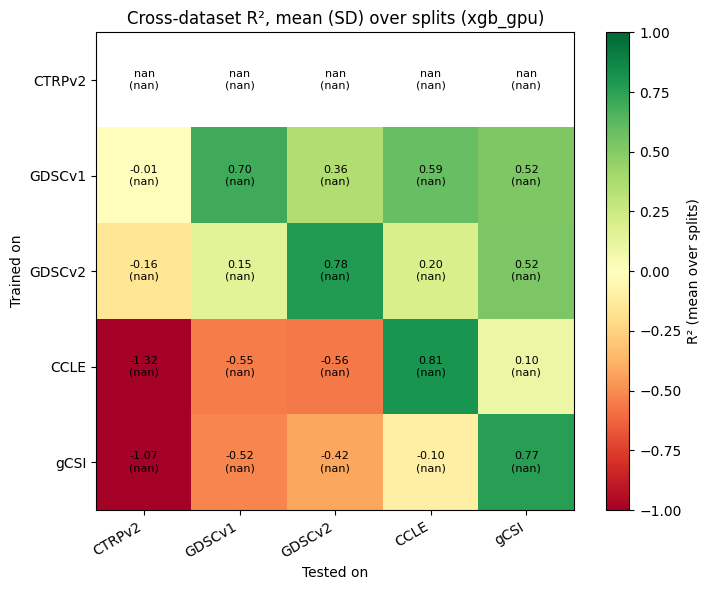

In [30]:
all_scores = pd.concat([pd.read_csv(f) for f in sorted(RES_DIR.glob("*_split*.csv"))],
                       ignore_index=True)
all_scores.to_csv(OUT_DIR / "all_scores_long.csv", index=False)
print("splits per source:", all_scores.groupby("source")["split"].nunique().to_dict())

def agg_matrix(metric, how):
    m = (all_scores.groupby(["source", "target"])[metric].agg(how).unstack("target")
         .reindex(index=names, columns=names))
    m.index.name, m.columns.name = "trained on", "tested on"
    return m

mean_m = {m: agg_matrix(m, "mean") for m in ["r2", "rmse", "pcc", "scc"]}
sd_m   = {m: agg_matrix(m, "std")  for m in ["r2", "rmse", "pcc", "scc"]}
for m in mean_m:
    print(f"\n{m.upper()}  mean over splits")
    display(mean_m[m].round(3))
    mean_m[m].to_csv(FIG_DIR / f"matrix_{m}_mean_{MODEL_TAG}.csv")
    sd_m[m].to_csv(FIG_DIR / f"matrix_{m}_sd_{MODEL_TAG}.csv")

M, S = mean_m["r2"], sd_m["r2"]
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(M.values.astype(float), cmap="RdYlGn", vmin=-1, vmax=1)
ax.set_xticks(range(5)); ax.set_xticklabels(M.columns, rotation=30, ha="right")
ax.set_yticks(range(5)); ax.set_yticklabels(M.index)
ax.set_xlabel("Tested on"); ax.set_ylabel("Trained on")
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{M.values[i, j]:.2f}\n({S.values[i, j]:.2f})",
                ha="center", va="center", fontsize=8)
plt.colorbar(im, label="R² (mean over splits)")
ax.set_title(f"Cross-dataset R², mean (SD) over splits ({MODEL_TAG})")
plt.tight_layout()
for ext in ("png", "pdf", "svg"):
    fig.savefig(FIG_DIR / f"matrix_r2_mean_{MODEL_TAG}.{ext}", dpi=300)
plt.show()

## 18. Do the diagnostic measurements explain the size of the failure? (pair-level association)

**Question.** Across the 20 cross-dataset pairs, do the diagnostics track the generalisation gap?

**Method.** For each pair, the following are collected: the share of target rows with unseen drugs,
unseen cell lines and unseen drug-cell pairs (Section 14), the domain-classifier AUC for gene and drug
features (Section 15), and the R² gap and Pearson gap (Section 13). The Spearman rank correlation
between each diagnostic and each gap is computed over the 20 pairs.

**Reading the result.** A high positive correlation means the diagnostic goes up when the failure gets worse.
It supports the diagnostic as an *indicator* of the failure. It does not prove causation:
the diagnostics are also correlated with each other and with source dataset size.

**Limitation.** Only 20 pairs, from 5 source datasets, so p-values are indicative only. The counterfactual
result (Section 14, performance restricted to seen drugs) is the stronger evidence.

In [2]:
from pathlib import Path
import pandas as pd
from scipy.stats import spearmanr

OUT_DIR = Path("/kaggle/working/outputs")

# ---- Reload what earlier cells saved (no need to rerun them) ----
needed = ["stratified_performance.csv", "domain_shift_auc.csv", "generalisation_gap.csv"]
missing = [f for f in needed if not (OUT_DIR / f).exists()]
assert not missing, f"Missing saved files: {missing}. Rerun the cell that creates them."

strat = pd.read_csv(OUT_DIR / "stratified_performance.csv")
dom   = pd.read_csv(OUT_DIR / "domain_shift_auc.csv")
gap   = pd.read_csv(OUT_DIR / "generalisation_gap.csv")

# ---- Pair-level table ----
sh = (strat[strat.stratum.isin(["drug_unseen", "cell_unseen", "pair_unseen"])]
      .pivot_table(index=["source", "target"], columns="stratum", values="share")
      .reset_index())
sh = sh[sh.source != sh.target]

d = dom[~dom.is_control][["source", "target", "auc_gene_expression", "auc_drug_descriptors"]]
tab = gap.merge(sh, on=["source", "target"]).merge(d, on=["source", "target"])
print("pairs in table:", len(tab))

diagnostics = ["drug_unseen", "cell_unseen", "pair_unseen",
               "auc_gene_expression", "auc_drug_descriptors"]
rows = []
for c in diagnostics:
    for g in ["r2_gap", "pcc_gap"]:
        rho, p = spearmanr(tab[c], tab[g])
        rows.append({"diagnostic": c, "versus": g, "spearman_rho": rho,
                     "p_value": p, "n_pairs": len(tab)})
assoc = pd.DataFrame(rows)
assoc.to_csv(OUT_DIR / "diagnostic_vs_gap_association.csv", index=False)
tab.round(3).to_csv(OUT_DIR / "pair_level_diagnostic_table.csv", index=False)
display(assoc.round(3))

pairs in table: 20


,diagnostic,versus,spearman_rho,p_value,n_pairs
0,drug_unseen,r2_gap,0.953,0.000,20
1,drug_unseen,pcc_gap,0.953,0.000,20
2,cell_unseen,r2_gap,0.794,0.000,20
3,cell_unseen,pcc_gap,0.797,0.000,20
4,pair_unseen,r2_gap,0.920,0.000,20
5,pair_unseen,pcc_gap,0.920,0.000,20
6,auc_gene_expression,r2_gap,0.015,0.950,20
7,auc_gene_expression,pcc_gap,-0.009,0.970,20
8,auc_drug_descriptors,r2_gap,-0.039,0.870,20
9,auc_drug_descriptors,pcc_gap,-0.032,0.895,20


## 19. Diagnostic check 3: do the datasets measure the same drug-cell response the same way?

**Question.** After accounting for which drugs and cell lines a model has seen, does a gap remain because
the datasets record different AUC values for the same experiment?

**Method (no model involved).**
1. **Marginal distributions.** Mean, SD and quantiles of AUC per dataset, and the Wasserstein distance
   (average shift needed to turn one distribution into the other) between every pair of datasets.
2. **Shared drug-cell pairs.** For every pair of datasets, take the drug-cell pairs measured in both.
   Repeated measurements within a dataset are first reduced to their median. For these shared pairs:
   Pearson and Spearman correlation between the two datasets' AUC values, and the mean difference
   (target minus source).
3. **Association with failure.** Spearman correlation across the 20 source → target pairs between these
   quantities and the generalisation gap (Section 13).

**Why it matters.** The same pair measured in two labs gives an empirical *agreement ceiling*: a model
cannot be expected to correlate with a target better than the target's own labels correlate with a
replicate measurement. A large systematic offset (mean difference) means a source model will be biased on
that target regardless of how well it learned biology. This is the direct test of the assay-difference
hypothesis.

**Uses target labels:** yes (response values only, no model predictions).
**Outputs.** `response_distribution_summary.csv`, `response_wasserstein.csv`, `shared_pair_concordance.csv`,
`response_vs_gap_association.csv`, and a distribution figure (PNG, PDF, SVG).

**Caveat.** Shared-pair counts vary widely between dataset pairs (see `n_shared`), and agreement is
computed only on drugs and cell lines present in both datasets.

,count,mean,std,min,5%,25%,50%,75%,95%,max
source,,,,,,,,,,
CTRPv2,286665.0,0.861,0.144,0.009,0.555,0.804,0.906,0.967,0.999,1.0
GDSCv1,171940.0,0.825,0.164,0.000,0.487,0.746,0.868,0.953,0.997,1.0
GDSCv2,114644.0,0.827,0.153,0.018,0.489,0.768,0.870,0.938,0.986,1.0
CCLE,9519.0,0.786,0.161,0.082,0.452,0.718,0.825,0.902,0.977,1.0
gCSI,4941.0,0.711,0.189,0.125,0.387,0.563,0.724,0.878,0.977,1.0



Wasserstein distance between AUC distributions (whole datasets)


,CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
CTRPv2,0.000,0.037,0.034,0.076,0.151
GDSCv1,0.037,0.000,0.013,0.040,0.114
GDSCv2,0.034,0.013,0.000,0.042,0.116
CCLE,0.076,0.040,0.042,0.000,0.075
gCSI,0.151,0.114,0.116,0.075,0.000



Agreement on drug-cell pairs measured in both datasets


,source,target,n_shared,pcc_shared,scc_shared,mean_diff_t_minus_s,abs_mean_diff,mae_shared
0,CTRPv2,GDSCv1,40855,0.694,0.627,-0.011,0.011,0.091
1,CTRPv2,GDSCv2,20852,0.794,0.717,0.007,0.007,0.078
2,CTRPv2,CCLE,5943,0.824,0.732,-0.029,0.029,0.079
3,CTRPv2,gCSI,3122,0.739,0.701,0.001,0.001,0.106
4,GDSCv1,CTRPv2,40855,0.694,0.627,0.011,0.011,0.091
5,GDSCv1,GDSCv2,23352,0.741,0.627,0.020,0.020,0.095
6,GDSCv1,CCLE,2917,0.780,0.675,-0.007,0.007,0.089
7,GDSCv1,gCSI,2273,0.687,0.694,0.026,0.026,0.124
8,GDSCv2,CTRPv2,20852,0.794,0.717,-0.007,0.007,0.078
9,GDSCv2,GDSCv1,23352,0.741,0.627,-0.020,0.020,0.095



Association with the generalisation gap (pairs with >= 30 shared rows)


,measure,versus,spearman_rho,p_value,n_pairs
0,pcc_shared,r2_gap,0.036,0.879,20
1,pcc_shared,pcc_gap,0.039,0.870,20
2,abs_mean_diff,r2_gap,0.039,0.870,20
3,abs_mean_diff,pcc_gap,-0.006,0.980,20
4,mae_shared,r2_gap,0.006,0.980,20
5,mae_shared,pcc_gap,0.036,0.879,20
6,wasserstein,r2_gap,0.100,0.676,20
7,wasserstein,pcc_gap,0.094,0.695,20


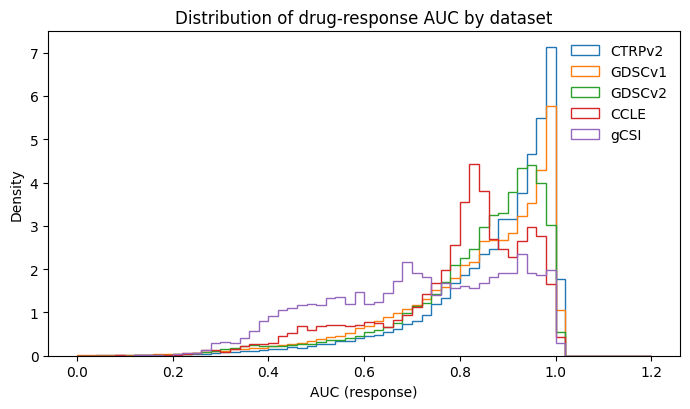

In [3]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr, wasserstein_distance

WORK_DIR = Path("/kaggle/working")
OUT_DIR  = WORK_DIR / "outputs"
FIG_DIR  = OUT_DIR / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
names = ["CTRPv2", "GDSCv1", "GDSCv2", "CCLE", "gCSI"]
MIN_SHARED = 30

resp = pd.read_csv(WORK_DIR / "csa_data/raw_data/y_data/response.tsv", sep="\t",
                   usecols=["source", "improve_sample_id", "improve_chem_id", "auc"])

# ---- 1. Marginal distributions ----
summ = (resp.groupby("source")["auc"]
        .describe(percentiles=[.05, .25, .5, .75, .95]).reindex(names).round(3))
display(summ)
summ.to_csv(OUT_DIR / "response_distribution_summary.csv")

w = pd.DataFrame(index=names, columns=names, dtype=float)
vals = {n: resp.loc[resp.source == n, "auc"].to_numpy() for n in names}
for s in names:
    for t in names:
        w.loc[s, t] = wasserstein_distance(vals[s], vals[t])
print("\nWasserstein distance between AUC distributions (whole datasets)")
display(w.round(3))
w.to_csv(OUT_DIR / "response_wasserstein.csv")

# ---- 2. Shared drug-cell pairs (replicates reduced to their median) ----
pair = (resp.groupby(["source", "improve_sample_id", "improve_chem_id"])["auc"]
        .median().reset_index())
wide = {n: pair[pair.source == n].set_index(["improve_sample_id", "improve_chem_id"])["auc"]
        for n in names}

rows = []
for s in names:
    for t in names:
        if s == t:
            continue
        j = pd.concat([wide[s].rename("s"), wide[t].rename("t")], axis=1, join="inner")
        rec = {"source": s, "target": t, "n_shared": len(j)}
        if len(j) >= MIN_SHARED:
            rec.update({
                "pcc_shared": pearsonr(j.s, j.t)[0],
                "scc_shared": spearmanr(j.s, j.t)[0],
                "mean_diff_t_minus_s": float((j.t - j.s).mean()),
                "abs_mean_diff": float(abs((j.t - j.s).mean())),
                "mae_shared": float((j.t - j.s).abs().mean()),
            })
        rows.append(rec)
conc = pd.DataFrame(rows)
conc.to_csv(OUT_DIR / "shared_pair_concordance.csv", index=False)
print("\nAgreement on drug-cell pairs measured in both datasets")
display(conc.round(3))

# ---- 3. Association with the generalisation gap ----
gap = pd.read_csv(OUT_DIR / "generalisation_gap.csv")
tab = gap.merge(conc, on=["source", "target"]).dropna(subset=["pcc_shared"])
tab["wasserstein"] = [w.loc[s, t] for s, t in zip(tab.source, tab.target)]
tests = ["pcc_shared", "abs_mean_diff", "mae_shared", "wasserstein"]
rows = []
for c in tests:
    for g in ["r2_gap", "pcc_gap"]:
        rho, p = spearmanr(tab[c], tab[g])
        rows.append({"measure": c, "versus": g, "spearman_rho": rho,
                     "p_value": p, "n_pairs": len(tab)})
assoc2 = pd.DataFrame(rows)
assoc2.to_csv(OUT_DIR / "response_vs_gap_association.csv", index=False)
print(f"\nAssociation with the generalisation gap (pairs with >= {MIN_SHARED} shared rows)")
display(assoc2.round(3))

# ---- Figure: AUC distribution per dataset ----
fig, ax = plt.subplots(figsize=(7, 4.2))
for n in names:
    ax.hist(vals[n], bins=60, range=(0, 1.2), density=True, histtype="step", lw=1.6, label=n)
ax.set_xlabel("AUC (response)"); ax.set_ylabel("Density")
ax.set_title("Distribution of drug-response AUC by dataset")
ax.legend(frameon=False)
plt.tight_layout()
for ext in ("png", "pdf", "svg"):
    fig.savefig(FIG_DIR / f"response_distribution.{ext}", dpi=300)
plt.show()

## 20. SHAP feature attributions for every source → dataset pair (split 0, GPU)

**Purpose.** Measure which input features each frozen model relies on, on its own held-out data (home)
and on every other dataset, so that the model's behaviour can be compared before and after transfer.

**Method.** For each of the 25 (source model, evaluated dataset) combinations, 5,000 rows are drawn at random
(fixed seed; the same rows for every source model evaluated on the same dataset; home rows come from the
source's test split). XGBoost's built-in exact tree SHAP on GPU 0 (`pred_contribs=True`) is used, restricted to
the trees up to the early-stopping point.

**Check.** For every row, base value + sum of SHAP values must equal the model prediction. The largest
violation is recorded.

**Saved quantities.**
- Mean |SHAP| per feature for three row subsets: all sampled rows, the 25% lowest-error rows and the
  25% highest-error rows (error = |true AUC − prediction|; the error subsets use response labels).
- Per row: true AUC, prediction, absolute error and the summed |SHAP| of gene-expression vs drug-descriptor features.

**Outputs.** `shap/shap_importance_split0.parquet`, `shap/shap_rows_split0.parquet`.

**Interpretation limit.** SHAP describes what the *model* used, not what is biologically causal.
Correlated features share credit, so single-feature rankings should be read together with the group-level results.

## 0b. Session restore: rebuild the working state after a kernel restart

**Purpose.** Kaggle clears all variables when the kernel restarts, but files in `/kaggle/working` persist.
This cell rebuilds, in one run, the objects that later sections depend on: configuration and random seed
(Section 0), the response table and the paper's splits (Sections 3 to 4), the feature tables and the input
builder `make_xy` (Sections 6 to 8), and the scoring function. Nothing is retrained and nothing is downloaded.

**Same choices as the original sections.** 1,000 most variable genes (selected without using response
values), constant Mordred descriptors removed, response = AUC. The dataset order
(CTRPv2, GDSCv1, GDSCv2, CCLE, gCSI) is the one used throughout.

**Check.** It prints the number of saved models and score files per source so that the state of the
training run can be seen before analysis continues.

In the public version of the notebook, this cell can replace Sections 0 and 3 to 8 as a single setup step.

In [7]:
import os, csv, random
from pathlib import Path
import numpy as np, pandas as pd
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import r2_score, mean_squared_error

# ---------------- Settings (as in Section 0) ----------------
SEED = 42
WORK_DIR = Path("/kaggle/working")
DATA_DIR = WORK_DIR / "csa_data"
RAW = DATA_DIR / "raw_data"
OUT_DIR = WORK_DIR / "outputs"; OUT_DIR.mkdir(exist_ok=True)
DATASETS = {"D1": "CTRPv2", "D2": "GDSCv1", "D3": "GDSCv2", "D4": "CCLE", "D5": "gCSI"}
names = list(DATASETS.values())
N_SPLITS = 10
N_GENES = 1000
random.seed(SEED); np.random.seed(SEED); os.environ["PYTHONHASHSEED"] = str(SEED)
assert RAW.exists(), "csa_data not found: re-run the download cell (Section 1)."

# ---------------- Response table and the paper's splits ----------------
resp = pd.read_csv(RAW / "y_data" / "response.tsv", sep="\t")
key = resp["improve_sample_id"] + "|" + resp["improve_chem_id"]

def read_ids(path):
    with open(path) as f:
        return [int(x) for x in f.read().split()]

splits = {}
for n in names:
    splits[(n, None, "all")] = read_ids(RAW / "splits" / f"{n}_all.txt")
    for k in range(N_SPLITS):
        for part in ("train", "val", "test"):
            splits[(n, k, part)] = read_ids(RAW / "splits" / f"{n}_split_{k}_{part}.txt")

def split_ids(name, k, part):
    return splits[(name, k, part)]

# ---------------- Features (same choices as Section 6) ----------------
def load_omics(path):
    with open(path) as f:
        reader = csv.reader(f, delimiter="\t")
        next(reader)
        k = 0
        for row in reader:
            if row[0] == "":
                k += 1
            else:
                break
    df = pd.read_csv(path, sep="\t", index_col=0, skiprows=range(1, 1 + k))
    return df.apply(pd.to_numeric, errors="coerce").astype(np.float32)

used_cells, used_drugs = set(resp["improve_sample_id"]), set(resp["improve_chem_id"])
omics = load_omics(RAW / "x_data" / "cancer_gene_expression.tsv")
omics = omics.loc[omics.index.isin(used_cells)]
omics = omics[omics.var(axis=0).nlargest(N_GENES).index]          # label-free selection
omics.columns = ["ge." + c for c in omics.columns]

drug = pd.read_csv(RAW / "x_data" / "drug_mordred.tsv", sep="\t", index_col=0)
drug = drug.apply(pd.to_numeric, errors="coerce").astype(np.float32)
drug = drug.loc[drug.index.isin(used_drugs)]
drug = drug.loc[:, drug.nunique(dropna=True) > 1]

omics_np = omics.to_numpy(dtype=np.float32)
drug_np = drug.to_numpy(dtype=np.float32)
omics_pos = {c: i for i, c in enumerate(omics.index)}
drug_pos = {d: i for i, d in enumerate(drug.index)}
FEATURE_NAMES = list(omics.columns) + list(drug.columns)
N_OM = omics_np.shape[1]
print("Features:", omics.shape[1], "gene +", drug.shape[1], "drug =", len(FEATURE_NAMES))
del omics, drug

# ---------------- Input builder and scoring ----------------
def make_xy(row_ids, chunk=20_000):
    d = resp.loc[row_ids, ["improve_sample_id", "improve_chem_id", "auc"]]
    ci = d["improve_sample_id"].map(omics_pos).to_numpy()
    di = d["improve_chem_id"].map(drug_pos).to_numpy()
    X = np.empty((len(d), omics_np.shape[1] + drug_np.shape[1]), dtype=np.float32)
    for i in range(0, len(d), chunk):
        sl = slice(i, i + chunk)
        X[sl, :N_OM] = omics_np[ci[sl]]
        X[sl, N_OM:] = drug_np[di[sl]]
    return X, d["auc"].to_numpy(dtype=np.float32), d

def score(y_true, y_pred):
    return {"r2": float(r2_score(y_true, y_pred)),
            "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "pcc": float(pearsonr(y_true, y_pred)[0]),
            "scc": float(spearmanr(y_true, y_pred)[0]),
            "n": int(len(y_true))}

# ---------------- State of the training run ----------------
MODEL_DIR = OUT_DIR / "models_xgb_gpu"
RES_DIR = OUT_DIR / "scores_xgb_gpu"
print("\nSaved models per source :", {n: len(list(MODEL_DIR.glob(f"{n}_split*.json"))) for n in names} if MODEL_DIR.exists() else "folder missing")
print("Score files per source  :", {n: len(list(RES_DIR.glob(f"{n}_split*.csv"))) for n in names} if RES_DIR.exists() else "folder missing")

Features: 1000 gene + 1397 drug = 2397

Saved models per source : folder missing
Score files per source  : folder missing


In [6]:
import gc, time
import numpy as np, pandas as pd, xgboost as xgb

need = ["make_xy", "split_ids", "splits", "names", "FEATURE_NAMES", "SEED", "OUT_DIR"]
missing = [v for v in need if v not in globals()]
assert not missing, f"Missing in memory: {missing}. Run Cells 1, 2 and 4-9 first."

GPU_ID, SHAP_K, N_SHAP = 0, 0, 5000
MODEL_DIR = OUT_DIR / "models_xgb_gpu"
SHAP_DIR = OUT_DIR / "shap"; SHAP_DIR.mkdir(exist_ok=True)
N_OM = sum(f.startswith("ge.") for f in FEATURE_NAMES)      # number of gene-expression features

def load_booster(source, k):
    bst = xgb.Booster()
    bst.load_model(str(MODEL_DIR / f"{source}_split{k}.json"))
    bst.set_param({"device": f"cuda:{GPU_ID}"})
    try:
        n_trees = bst.best_iteration + 1          # stop at the early-stopping point
    except Exception:
        n_trees = bst.num_boosted_rounds()
    return bst, n_trees

imp_vecs, imp_meta, row_tabs = [], [], []
t0 = time.time()
for s in names:
    if not (MODEL_DIR / f"{s}_split{SHAP_K}.json").exists():
        print(f"[skip] no saved model for {s} split {SHAP_K}")
        continue
    bst, n_trees = load_booster(s, SHAP_K)
    for t in names:
        rows = np.asarray(split_ids(t, SHAP_K, "test") if t == s else splits[(t, None, "all")])
        rng = np.random.default_rng(SEED + names.index(t))           # same rows for every source model
        sel = rows[rng.choice(len(rows), size=min(N_SHAP, len(rows)), replace=False)]
        X, y, meta = make_xy(sel)
        dm = xgb.DMatrix(X)
        contrib = bst.predict(dm, pred_contribs=True, iteration_range=(0, n_trees))
        pred = bst.predict(dm, iteration_range=(0, n_trees))
        add_err = float(np.abs(contrib.sum(1) - pred).max())
        assert add_err < 1e-2, f"SHAP additivity failed for {s}->{t}: {add_err}"
        phi = np.abs(contrib[:, :-1])                                 # last column = base value
        err = np.abs(y - pred)
        q25, q75 = np.quantile(err, [0.25, 0.75])
        subsets = {"all": np.ones(len(err), bool), "low_err": err <= q25, "high_err": err >= q75}
        for nm, m in subsets.items():
            imp_vecs.append(phi[m].mean(0).astype(np.float32))
            imp_meta.append({"source": s, "dataset": t, "subset": nm,
                             "n": int(m.sum()), "max_additivity_error": add_err})
        row_tabs.append(pd.DataFrame({
            "source": s, "dataset": t, "row_id": meta.index.to_numpy(),
            "y": y, "y_pred": pred, "abs_err": err,
            "gene_abs": phi[:, :N_OM].sum(1), "drug_abs": phi[:, N_OM:].sum(1)}))
        del X, dm, contrib, pred, phi; gc.collect()
    print(f"finished source {s}  ({time.time()-t0:.0f}s)")
    del bst; gc.collect()

imp = pd.concat([pd.DataFrame(imp_meta),
                 pd.DataFrame(np.vstack(imp_vecs), columns=FEATURE_NAMES)], axis=1)
imp.to_parquet(SHAP_DIR / "shap_importance_split0.parquet", index=False)
pd.concat(row_tabs, ignore_index=True).to_parquet(SHAP_DIR / "shap_rows_split0.parquet", index=False)
print("\nLargest additivity error over all pairs:", imp.max_additivity_error.max())
display(imp[imp.subset == "all"][["source", "dataset", "n"]]
        .pivot(index="source", columns="dataset", values="n").reindex(columns=names))

finished source CTRPv2  (17s)
finished source GDSCv1  (29s)
finished source GDSCv2  (39s)
finished source CCLE  (45s)
finished source gCSI  (52s)

Largest additivity error over all pairs: 2.2351741790771484e-06


dataset,CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
source,,,,,
CCLE,5000,5000,5000,951,4941
CTRPv2,5000,5000,5000,5000,4941
GDSCv1,5000,5000,5000,5000,4941
GDSCv2,5000,5000,5000,5000,4941
gCSI,5000,5000,5000,5000,494


## 21. Does the model reason differently after transfer? (SHAP comparison and link to failure)

**Questions.**
1. Does a source model rely on the same features on the target dataset as on its home data?
2. Does it lean more on cell-line (gene expression) or drug (descriptor) features, and does that change after transfer?
3. On the target, are high-error predictions driven by different features than low-error predictions?
4. Do these differences track the size of the generalisation gap?

**Measures (per source → target pair).**
- `importance_spearman`: rank correlation between the mean-|SHAP| vectors on home vs target data (1 = same reasoning).
- `top50_jaccard`: overlap of the 50 most important features on home vs target.
- `gene_share_*`: share of total |SHAP| carried by gene-expression features (the rest is drug descriptors);
  `gene_share_shift` = target − home.
- High- vs low-error comparison: correlation between the two importance vectors and the gene share in each.
- Spearman correlation of each measure with the R² gap across the 20 pairs (Section 13).

**Uses target labels:** only the high- vs low-error comparison.
**Outputs.** `shap/shap_pair_metrics.csv`, `shap/shap_error_groups.csv`, `shap/shap_vs_gap_association.csv`,
`figures/shap_comparison.(png|pdf|svg)`.

**Caution.** Only 20 pairs, which are not independent (each source and target appears several times);
treat correlations as descriptive.

Rank correlation of feature importance, home vs target (1 = same reasoning)


target,CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
source,,,,,
CTRPv2,1.000,0.992,0.985,0.964,0.947
GDSCv1,0.991,1.000,0.989,0.967,0.933
GDSCv2,0.985,0.990,1.000,0.971,0.955
CCLE,0.989,0.990,0.991,1.000,0.990
gCSI,0.992,0.991,0.992,0.992,1.000


Share of |SHAP| carried by gene-expression features on the evaluated dataset


target,CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
source,,,,,
CTRPv2,0.326,0.340,0.337,0.338,0.329
GDSCv1,0.334,0.335,0.341,0.349,0.338
GDSCv2,0.361,0.367,0.366,0.381,0.378
CCLE,0.415,0.426,0.426,0.446,0.422
gCSI,0.457,0.459,0.459,0.458,0.463



High-error vs low-error rows (same source model, same evaluated dataset)


,source,dataset,spearman_high_vs_low,gene_share_high_err,gene_share_low_err
0,CTRPv2,CTRPv2,0.986,0.336,0.321
1,CTRPv2,GDSCv1,0.989,0.342,0.340
2,CTRPv2,GDSCv2,0.979,0.342,0.334
3,CTRPv2,CCLE,0.974,0.345,0.334
4,CTRPv2,gCSI,0.968,0.342,0.321
5,GDSCv1,CTRPv2,0.979,0.335,0.335
6,GDSCv1,GDSCv1,0.987,0.350,0.325
7,GDSCv1,GDSCv2,0.979,0.346,0.337
8,GDSCv1,CCLE,0.974,0.354,0.344
9,GDSCv1,gCSI,0.960,0.330,0.343



Association of SHAP measures with the generalisation gap


,measure,versus,spearman_rho,p_value,n_pairs
0,importance_spearman,r2_gap,0.701,0.001,20
1,importance_spearman,pcc_gap,0.713,0.000,20
2,top50_jaccard,r2_gap,0.302,0.196,20
3,top50_jaccard,pcc_gap,0.276,0.238,20
4,gene_share_shift,r2_gap,-0.814,0.000,20
5,gene_share_shift,pcc_gap,-0.800,0.000,20
6,abs_gene_share_shift,r2_gap,0.232,0.326,20
7,abs_gene_share_shift,pcc_gap,0.208,0.380,20


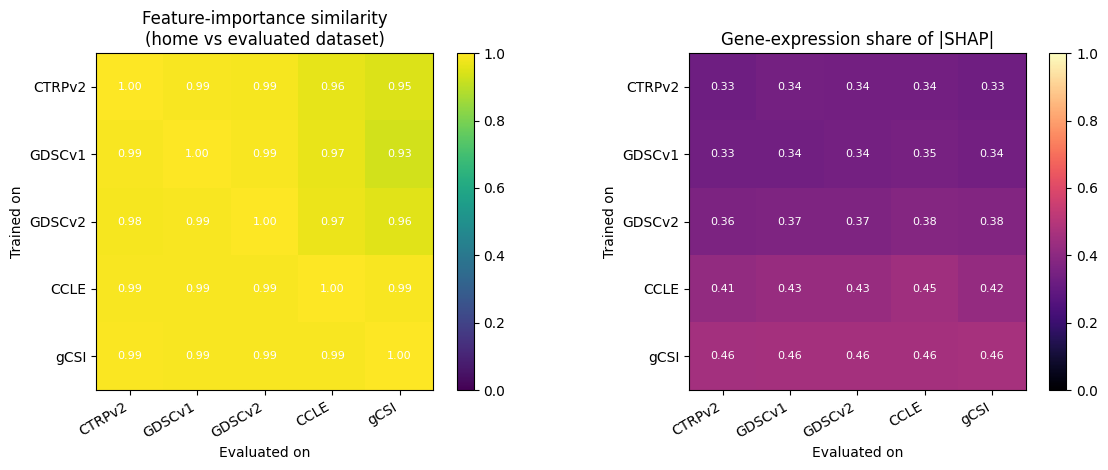

In [7]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

OUT_DIR = Path("/kaggle/working/outputs"); SHAP_DIR = OUT_DIR / "shap"; FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)
imp = pd.read_parquet(SHAP_DIR / "shap_importance_split0.parquet")
meta_cols = ["source", "dataset", "subset", "n", "max_additivity_error"]
feat_cols = [c for c in imp.columns if c not in meta_cols]
ge_mask = np.array([c.startswith("ge.") for c in feat_cols])
order = ["CTRPv2", "GDSCv1", "GDSCv2", "CCLE", "gCSI"]
srcs = [n for n in order if n in set(imp.source)]

def vec(s, t, sub="all"):
    r = imp[(imp.source == s) & (imp.dataset == t) & (imp.subset == sub)]
    return r[feat_cols].iloc[0].to_numpy(dtype=float)

def gene_share(v):
    return v[ge_mask].sum() / v.sum()

# ---- Home vs target comparison ----
rows = []
for s in srcs:
    h = vec(s, s)
    for t in order:
        v = vec(s, t)
        rows.append({
            "source": s, "target": t,
            "importance_spearman": spearmanr(h, v)[0],
            "top50_jaccard": len(set(np.argsort(-h)[:50]) & set(np.argsort(-v)[:50]))
                             / len(set(np.argsort(-h)[:50]) | set(np.argsort(-v)[:50])),
            "gene_share_home": gene_share(h), "gene_share_target": gene_share(v),
            "gene_share_shift": gene_share(v) - gene_share(h)})
pm = pd.DataFrame(rows)
pm.to_csv(SHAP_DIR / "shap_pair_metrics.csv", index=False)

for col, title in [("importance_spearman", "Rank correlation of feature importance, home vs target (1 = same reasoning)"),
                   ("gene_share_target", "Share of |SHAP| carried by gene-expression features on the evaluated dataset")]:
    print(title)
    display(pm.pivot(index="source", columns="target", values=col).reindex(index=srcs, columns=order).round(3))

# ---- High- vs low-error rows on each evaluated dataset (uses labels) ----
rows = []
for s in srcs:
    for t in order:
        hi, lo = vec(s, t, "high_err"), vec(s, t, "low_err")
        rows.append({"source": s, "dataset": t, "spearman_high_vs_low": spearmanr(hi, lo)[0],
                     "gene_share_high_err": gene_share(hi), "gene_share_low_err": gene_share(lo)})
eg = pd.DataFrame(rows)
eg.to_csv(SHAP_DIR / "shap_error_groups.csv", index=False)
print("\nHigh-error vs low-error rows (same source model, same evaluated dataset)")
display(eg.round(3))

# ---- Association with the generalisation gap (20 cross pairs) ----
gap = pd.read_csv(OUT_DIR / "generalisation_gap.csv")
tab = gap.merge(pm[pm.source != pm.target], on=["source", "target"])
tab["abs_gene_share_shift"] = tab.gene_share_shift.abs()
rows = []
for c in ["importance_spearman", "top50_jaccard", "gene_share_shift", "abs_gene_share_shift"]:
    for g in ["r2_gap", "pcc_gap"]:
        rho, p = spearmanr(tab[c], tab[g])
        rows.append({"measure": c, "versus": g, "spearman_rho": rho, "p_value": p, "n_pairs": len(tab)})
sa = pd.DataFrame(rows)
sa.to_csv(SHAP_DIR / "shap_vs_gap_association.csv", index=False)
print("\nAssociation of SHAP measures with the generalisation gap")
display(sa.round(3))

# ---- Figure ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, col, ttl, cmap, rng_ in [
        (axes[0], "importance_spearman", "Feature-importance similarity\n(home vs evaluated dataset)", "viridis", (0, 1)),
        (axes[1], "gene_share_target", "Gene-expression share of |SHAP|", "magma", (0, 1))]:
    M = pm.pivot(index="source", columns="target", values=col).reindex(index=srcs, columns=order)
    im = ax.imshow(M.values.astype(float), cmap=cmap, vmin=rng_[0], vmax=rng_[1])
    ax.set_xticks(range(5)); ax.set_xticklabels(order, rotation=30, ha="right")
    ax.set_yticks(range(len(srcs))); ax.set_yticklabels(srcs)
    ax.set_xlabel("Evaluated on"); ax.set_ylabel("Trained on"); ax.set_title(ttl)
    for i in range(len(srcs)):
        for j in range(5):
            ax.text(j, i, f"{M.values[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white")
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
for ext in ("png", "pdf", "svg"):
    fig.savefig(FIG_DIR / f"shap_comparison.{ext}", dpi=300)
plt.show()

## 22. Features that are both important to the model and shifted between source and target

**Question.** For each failing pair, which features does the source model rely on that also differ most between
the source training rows and the target rows?

**Method.** For each cross-dataset pair, 10,000 source training rows and 10,000 target rows are drawn (fixed seed).
For every feature the standardised mean difference (SMD) is computed. Each feature gets a rank for its
mean |SHAP| on the target (Section 20) and a rank for |SMD|. Two outputs per pair:
- the Spearman correlation between |SMD| and target importance across all features;
- the 10 features with the highest *combined* rank (both important and shifted).

**Uses no response values.**

**Interpretation limit.** All datasets share one omics table and one drug-descriptor table, so a shifted feature
reflects a different mix of cell lines and drugs, not a different measurement of the same entity.
A feature flagged here is a candidate explanation, to be tested (for example by the seen/unseen analysis), not a proven cause.

**Output.** `shap/important_and_shifted_features.csv`, `shap/importance_vs_shift_correlation.csv`.

In [8]:
from scipy.stats import spearmanr, rankdata

need = ["make_xy", "splits", "FEATURE_NAMES", "SEED"]
missing = [v for v in need if v not in globals()]
assert not missing, f"Missing in memory: {missing}. Run Cells 1, 2 and 4-9 first."

imp = pd.read_parquet(SHAP_DIR / "shap_importance_split0.parquet")
assert list(imp.columns[5:]) == list(FEATURE_NAMES), "Feature order differs from the SHAP file."
N_OM = sum(f.startswith("ge.") for f in FEATURE_NAMES)
rng = np.random.default_rng(SEED)

top_rows, corr_rows = [], []
for s in srcs:
    src_rows = np.asarray(splits[(s, 0, "train")])
    Xs, _, _ = make_xy(src_rows[rng.choice(len(src_rows), size=min(10_000, len(src_rows)), replace=False)])
    for t in order:
        if t == s:
            continue
        t_rows = np.asarray(splits[(t, None, "all")])
        Xt, _, _ = make_xy(t_rows[rng.choice(len(t_rows), size=min(10_000, len(t_rows)), replace=False)])
        smd = (np.nanmean(Xt, 0) - np.nanmean(Xs, 0)) / np.sqrt((np.nanvar(Xs, 0) + np.nanvar(Xt, 0)) / 2 + 1e-8)
        imp_t = vec(s, t)
        r_imp = rankdata(-imp_t) / len(imp_t)               # small = important
        r_smd = rankdata(-np.abs(smd)) / len(smd)           # small = strongly shifted
        combined = r_imp + r_smd
        corr_rows.append({"source": s, "target": t,
                          "spearman_absSMD_vs_importance": spearmanr(np.abs(smd), imp_t)[0]})
        for rank, i in enumerate(np.argsort(combined)[:10], 1):
            top_rows.append({"source": s, "target": t, "rank": rank, "feature": FEATURE_NAMES[i],
                             "block": "gene" if i < N_OM else "drug",
                             "mean_abs_shap_on_target": float(imp_t[i]), "smd": float(smd[i])})
        del Xt
    del Xs

top_df, corr_df = pd.DataFrame(top_rows), pd.DataFrame(corr_rows)
top_df.to_csv(SHAP_DIR / "important_and_shifted_features.csv", index=False)
corr_df.to_csv(SHAP_DIR / "importance_vs_shift_correlation.csv", index=False)

print("Do the features the model relies on also differ between source and target?")
display(corr_df.pivot(index="source", columns="target", values="spearman_absSMD_vs_importance")
        .reindex(index=srcs, columns=order).round(3))
print("\nShare of the 10 combined-rank features that are drug descriptors, per pair")
display(top_df.assign(is_drug=top_df.block == "drug")
        .pivot_table(index="source", columns="target", values="is_drug", aggfunc="mean")
        .reindex(index=srcs, columns=order).round(2))
display(top_df[(top_df.source == "CCLE") & (top_df.target == "CTRPv2")].round(3))

Do the features the model relies on also differ between source and target?


target,CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
source,,,,,
CTRPv2,NaN,0.007,0.085,-0.045,-0.069
GDSCv1,-0.008,NaN,-0.063,-0.142,-0.119
GDSCv2,0.032,-0.093,NaN,-0.170,-0.187
CCLE,-0.315,-0.355,-0.284,NaN,-0.205
gCSI,-0.376,-0.395,-0.402,-0.255,NaN



Share of the 10 combined-rank features that are drug descriptors, per pair


target,CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
source,,,,,
CTRPv2,NaN,1.0,1.0,1.0,1.0
GDSCv1,1.0,NaN,1.0,1.0,1.0
GDSCv2,1.0,1.0,NaN,1.0,1.0
CCLE,1.0,1.0,1.0,NaN,1.0
gCSI,1.0,1.0,1.0,1.0,NaN


,source,target,rank,feature,block,mean_abs_shap_on_target,smd
120,CCLE,CTRPv2,1,mordred.VE2_A,drug,0.001,0.577
121,CCLE,CTRPv2,2,mordred.ATSC4d,drug,0.018,-0.497
122,CCLE,CTRPv2,3,mordred.piPC4,drug,0.001,-0.514
123,CCLE,CTRPv2,4,mordred.IC0,drug,0.002,-0.396
124,CCLE,CTRPv2,5,mordred.AATS2i,drug,0.005,-0.385
125,CCLE,CTRPv2,6,mordred.GATS8Z,drug,0.000,0.552
126,CCLE,CTRPv2,7,mordred.VR3_A,drug,0.005,-0.345
127,CCLE,CTRPv2,8,mordred.nAromBond,drug,0.001,-0.387
128,CCLE,CTRPv2,9,mordred.nX,drug,0.000,-0.686
129,CCLE,CTRPv2,10,mordred.AETA_beta_s,drug,0.000,-0.394


## 23. Is the SHAP difference between high- and low-error rows explained by unseen drugs?

**Background.** In Section 21 the CCLE-trained model leaned more on drug features for its high-error rows than
for its low-error rows on the large datasets. Unseen drugs are also more likely to produce high errors
(Section 14). This section tests whether the SHAP pattern is only a side effect of drug coverage.

**Method.** Each SHAP-sampled row (Section 20) is labelled `drug_seen` or `drug_unseen` using the source
model's split-0 training rows. For every cross-dataset pair:
1. Mean absolute error and mean per-row gene-expression share of |SHAP| in each group
   (per-row share = gene |SHAP| / (gene + drug |SHAP|), averaged over rows).
2. Spearman correlation between the per-row gene share and the absolute error, overall and *within* each group.

**Reading the result.** If the correlation between gene share and error disappears inside the seen and unseen
groups, the earlier pattern was explained by drug coverage. If it remains inside the groups, the model's use of
features carries information about its errors beyond drug coverage.

**Uses target labels:** yes (absolute error).  **Outputs.** `shap/shap_seen_unseen_rows.csv`.

**Limit.** Split 0 only; each pair uses at most 5,000 sampled rows, and groups with fewer than `MIN_N` rows are not analysed.

In [9]:
from pathlib import Path
import numpy as np, pandas as pd
from scipy.stats import spearmanr

WORK_DIR = Path("/kaggle/working"); OUT_DIR = WORK_DIR / "outputs"; SHAP_DIR = OUT_DIR / "shap"
RAW = WORK_DIR / "csa_data" / "raw_data"
MIN_N, K = 100, 0
order = ["CTRPv2", "GDSCv1", "GDSCv2", "CCLE", "gCSI"]

resp = pd.read_csv(RAW / "y_data" / "response.tsv", sep="\t", usecols=["improve_chem_id"])
rows = pd.read_parquet(SHAP_DIR / "shap_rows_split0.parquet")
rows["gene_share"] = rows.gene_abs / (rows.gene_abs + rows.drug_abs)

def train_drugs(source):
    ids = [int(x) for x in open(RAW / "splits" / f"{source}_split_{K}_train.txt").read().split()]
    return set(resp.loc[ids, "improve_chem_id"])

def rho(a, b):
    return spearmanr(a, b)[0] if len(a) >= MIN_N and a.std() > 0 and b.std() > 0 else np.nan

out = []
for s in order:
    seen_drugs = train_drugs(s)
    for t in order:
        if s == t:
            continue
        d = rows[(rows.source == s) & (rows.dataset == t)].copy()
        if d.empty:
            continue
        d["seen"] = resp.loc[d.row_id, "improve_chem_id"].isin(seen_drugs).to_numpy()
        g = {"seen": d[d.seen], "unseen": d[~d.seen]}
        out.append({
            "source": s, "target": t,
            "n_seen": len(g["seen"]), "n_unseen": len(g["unseen"]),
            "err_seen": g["seen"].abs_err.mean(), "err_unseen": g["unseen"].abs_err.mean(),
            "gene_share_seen": g["seen"].gene_share.mean(), "gene_share_unseen": g["unseen"].gene_share.mean(),
            "rho_all": rho(d.gene_share, d.abs_err),
            "rho_within_seen": rho(g["seen"].gene_share, g["seen"].abs_err),
            "rho_within_unseen": rho(g["unseen"].gene_share, g["unseen"].abs_err)})

res = pd.DataFrame(out)
res.to_csv(SHAP_DIR / "shap_seen_unseen_rows.csv", index=False)
print("Per pair: error and gene share of |SHAP| on seen vs unseen drugs (blank = fewer than MIN_N rows)")
display(res.round(3))
print("\nSpearman(gene share, absolute error): overall vs within groups, averaged over target datasets")
display(res.groupby("source")[["rho_all", "rho_within_seen", "rho_within_unseen"]].mean()
        .reindex([o for o in order if o in set(res.source)]).round(3))

Per pair: error and gene share of |SHAP| on seen vs unseen drugs (blank = fewer than MIN_N rows)


,source,target,n_seen,n_unseen,err_seen,err_unseen,gene_share_seen,gene_share_unseen,rho_all,rho_within_seen,rho_within_unseen
0,CTRPv2,GDSCv1,2031,2969,0.093,0.112,0.338,0.340,0.044,0.064,0.028
1,CTRPv2,GDSCv2,2179,2821,0.076,0.089,0.338,0.335,0.059,0.147,-0.002
2,CTRPv2,CCLE,3606,1394,0.075,0.096,0.338,0.342,0.032,0.022,0.067
3,CTRPv2,gCSI,3706,1235,0.099,0.118,0.330,0.335,0.120,0.121,0.088
4,GDSCv1,CTRPv2,1290,3710,0.076,0.125,0.341,0.330,-0.009,0.170,-0.019
5,GDSCv1,GDSCv2,2246,2754,0.086,0.100,0.341,0.338,0.079,0.181,-0.006
6,GDSCv1,CCLE,3410,1590,0.076,0.090,0.351,0.345,0.042,0.122,-0.098
7,GDSCv1,gCSI,4327,614,0.107,0.089,0.338,0.336,-0.085,-0.100,0.079
8,GDSCv2,CTRPv2,803,4197,0.075,0.123,0.369,0.359,-0.065,0.140,-0.080
9,GDSCv2,GDSCv1,1456,3544,0.095,0.124,0.367,0.367,-0.016,0.147,-0.085



Spearman(gene share, absolute error): overall vs within groups, averaged over target datasets


,rho_all,rho_within_seen,rho_within_unseen
source,,,
CTRPv2,0.064,0.089,0.045
GDSCv1,0.007,0.093,-0.011
GDSCv2,-0.028,0.150,-0.102
CCLE,-0.348,-0.169,-0.286
gCSI,0.041,0.120,0.055


## 24. Evidence table: all measurements for each source → target pair

**Purpose.** Bring every diagnostic measurement from Sections 13 to 23 into a single table, one row per
cross-dataset pair, so that explanations are built from numbers and nothing else. The same table is saved as JSON
for the reasoning agent (Stage B4).

**Contents per pair.**
- *Failure:* within-dataset and cross-dataset R², R² gap, Pearson gap, whether R² < 0.
- *Coverage:* share of target rows with unseen drugs, cell lines and drug-cell pairs.
- *Counterfactual:* R² when the target is restricted to seen drugs (and to unseen drugs, seen/unseen cell lines),
  group sizes, and the share of the R² gap that is closed by restricting to seen drugs.
- *Feature shift:* domain-classifier AUC for gene and drug features.
- *Assay:* number of drug-cell pairs measured in both datasets, their Pearson correlation and the implied agreement
  ceiling (r²), mean offset, Wasserstein distance between AUC distributions.
- *Model behaviour:* SHAP importance similarity, top-50 overlap, shift in gene-expression share.

**Rule.** No verdict is computed here; the table only reports measurements and flags small groups
(`reliable_seen_drug = n ≥ 500`).

**Important.** The seen-drug R² is computed on a different subset of rows than the overall R²,
so "share of gap closed" describes a restricted evaluation, not the same rows re-scored.

**Outputs.** `evidence/evidence_per_pair.csv`, `evidence/evidence_per_pair.json`.

In [10]:
import json
EV_DIR = OUT_DIR / "evidence"; EV_DIR.mkdir(exist_ok=True)

gap    = pd.read_csv(OUT_DIR / "generalisation_gap.csv")
strat  = pd.read_csv(OUT_DIR / "stratified_performance.csv")
dom    = pd.read_csv(OUT_DIR / "domain_shift_auc.csv")
conc   = pd.read_csv(OUT_DIR / "shared_pair_concordance.csv")
wass   = pd.read_csv(OUT_DIR / "response_wasserstein.csv", index_col=0)
shap_m = pd.read_csv(SHAP_DIR / "shap_pair_metrics.csv")

st = strat.groupby(["source", "target", "stratum"]).agg(r2=("r2", "mean"), n=("n", "mean"), share=("share", "mean")).reset_index()
def st_get(s, t, stratum, col):
    r = st[(st.source == s) & (st.target == t) & (st.stratum == stratum)]
    return float(r[col].iloc[0]) if len(r) else np.nan

rows = []
for _, g in gap.iterrows():
    s, t = g.source, g.target
    rec = {"source": s, "target": t,
           "r2_within": g.r2_within, "r2_cross": g.r2_cross, "r2_gap": g.r2_gap,
           "pcc_cross": g.pcc_cross, "pcc_gap": g.pcc_gap, "worse_than_mean": bool(g.worse_than_mean),
           "share_unseen_drug": st_get(s, t, "drug_unseen", "share"),
           "share_unseen_cell": st_get(s, t, "cell_unseen", "share"),
           "share_unseen_pair": st_get(s, t, "pair_unseen", "share"),
           "r2_drug_seen": st_get(s, t, "drug_seen", "r2"), "n_drug_seen": st_get(s, t, "drug_seen", "n"),
           "r2_drug_unseen": st_get(s, t, "drug_unseen", "r2"), "n_drug_unseen": st_get(s, t, "drug_unseen", "n"),
           "r2_cell_seen": st_get(s, t, "cell_seen", "r2"), "r2_cell_unseen": st_get(s, t, "cell_unseen", "r2"),
           "n_cell_unseen": st_get(s, t, "cell_unseen", "n")}
    rec["reliable_seen_drug"] = bool(rec["n_drug_seen"] >= 500)
    rec["share_gap_closed_by_seen_drugs"] = (rec["r2_drug_seen"] - g.r2_cross) / g.r2_gap if g.r2_gap > 0 else np.nan
    d = dom[(dom.source == s) & (dom.target == t)].iloc[0]
    rec.update({"domain_auc_gene": d.auc_gene_expression, "domain_auc_drug": d.auc_drug_descriptors})
    c = conc[(conc.source == s) & (conc.target == t)].iloc[0]
    rec.update({"n_shared_pairs": int(c.n_shared), "pcc_shared": c.pcc_shared,
                "agreement_ceiling_r2": c.pcc_shared ** 2, "mean_offset_t_minus_s": c.mean_diff_t_minus_s,
                "wasserstein_auc": float(wass.loc[s, t])})
    m = shap_m[(shap_m.source == s) & (shap_m.target == t)].iloc[0]
    rec.update({"shap_importance_spearman": m.importance_spearman, "shap_top50_jaccard": m.top50_jaccard,
                "shap_gene_share_shift": m.gene_share_shift})
    rows.append(rec)

ev = pd.DataFrame(rows).sort_values("r2_gap", ascending=False).reset_index(drop=True)
ev.to_csv(EV_DIR / "evidence_per_pair.csv", index=False)

limitations = [
    "Split 0 only unless stated otherwise; all pairs share one omics table and one drug-descriptor table.",
    "The 20 pairs are not independent: each dataset appears as source and as target several times.",
    "Seen-drug R2 is computed on a restricted subset, not the same rows as the overall R2.",
    "Domain-classifier AUC for drug descriptors is near 1 for every pair and does not separate pairs.",
    "SHAP describes model behaviour, not biological causation."]
with open(EV_DIR / "evidence_per_pair.json", "w") as f:
    json.dump({"limitations": limitations,
               "pairs": json.loads(ev.round(4).to_json(orient="records"))}, f, indent=2)

pd.set_option("display.width", 220)
show = ["source", "target", "r2_cross", "r2_gap", "share_unseen_drug", "r2_drug_seen", "n_drug_seen",
        "reliable_seen_drug", "share_gap_closed_by_seen_drugs", "pcc_shared", "agreement_ceiling_r2", "shap_top50_jaccard"]
display(ev[show].round(2))

,source,target,r2_cross,r2_gap,share_unseen_drug,r2_drug_seen,n_drug_seen,reliable_seen_drug,share_gap_closed_by_seen_drugs,pcc_shared,agreement_ceiling_r2,shap_top50_jaccard
0,CCLE,CTRPv2,-1.32,2.13,0.96,0.61,11495.0,True,0.91,0.82,0.68,0.75
1,gCSI,CTRPv2,-1.07,1.83,0.97,0.53,7804.0,True,0.87,0.74,0.55,0.85
2,CCLE,GDSCv2,-0.56,1.37,0.90,0.12,11837.0,True,0.50,0.71,0.50,0.96
3,CCLE,GDSCv1,-0.55,1.36,0.95,0.47,9161.0,True,0.75,0.78,0.61,0.79
4,gCSI,GDSCv1,-0.52,1.28,0.96,0.42,6732.0,True,0.73,0.69,0.47,0.85
5,gCSI,GDSCv2,-0.42,1.18,0.89,0.39,12425.0,True,0.68,0.71,0.50,0.85
6,GDSCv2,CTRPv2,-0.16,0.94,0.85,0.61,43996.0,True,0.82,0.79,0.63,0.79
7,gCSI,CCLE,-0.10,0.87,0.76,0.60,2316.0,True,0.81,0.78,0.61,0.82
8,CCLE,gCSI,0.10,0.71,0.62,0.43,1863.0,True,0.47,0.78,0.61,0.79
9,GDSCv1,CTRPv2,-0.01,0.71,0.75,0.51,72359.0,True,0.74,0.69,0.48,0.89


## 25. Drug novelty score: how far is each target drug from the source model's training drugs?

**Question.** Can the chemical distance between a target drug and the source model's training drugs, which needs no
response values, predict where the model fails?

**Definition.** Each drug is represented by its 512-bit ECFP4 fingerprint (the `drug_ecfp4_nbits512` table of the benchmark).
Similarity between two drugs is the Tanimoto coefficient (shared bits / bits present in either; 1 = identical
fingerprints). For a source model, the nearest-neighbour similarity of a drug is its highest Tanimoto similarity to any drug in
that source's split-0 training rows, and **novelty = 1 − nearest-neighbour similarity**. Drugs that were in training have novelty 0.
Novelty is calculated per drug, then attached to every response row of that drug.

**Analyses for each of the 20 cross-dataset pairs.**
1. Spearman correlation between novelty and absolute prediction error among rows with unseen drugs.
2. Mean absolute error (MAE) and R² for four groups: seen drugs, and unseen drugs split into near / mid / far thirds by novelty.
3. Early-warning ability: ROC-AUC of novelty for flagging the 25% of rows with the largest error, compared with the
   plain "drug unseen: yes/no" flag. (Novelty is label-free; response values are used only to evaluate it.)
4. Across the 20 pairs: Spearman correlation of the mean novelty and of the share of unseen drugs with the R² gap.

**Inputs.** Saved predictions (`predictions_xgb_gpu/`), split files, fingerprint table, `generalisation_gap.csv`.
**Outputs.** `novelty/drug_nn_similarity_split0.csv`, `novelty/novelty_pair_metrics.csv`, `novelty/novelty_bins.csv`,
`figures/novelty_error_bins.(png|pdf|svg)`.

**Limits.** A 512-bit ECFP4 fingerprint is a crude description of a drug; chemically different drugs can act on the same biology and vice versa.
Novelty here means chemical distance only. Split 0 only. Groups with fewer than `MIN_N` rows are not scored.

Per pair: novelty vs error (unseen rows) and early-warning AUC


,source,target,n,share_unseen,mean_novelty_all,mean_novelty_unseen,rho_novelty_error_unseen,warn_auc_novelty,warn_auc_unseen_flag
0,CTRPv2,GDSCv1,171940,0.596,0.365,0.611,0.022,0.535,0.533
1,CTRPv2,GDSCv2,114644,0.552,0.338,0.611,-0.050,0.516,0.528
2,CTRPv2,CCLE,9519,0.280,0.123,0.440,-0.163,0.549,0.558
3,CTRPv2,gCSI,4941,0.250,0.120,0.482,-0.131,0.522,0.527
4,GDSCv1,CTRPv2,286665,0.748,0.503,0.673,0.141,0.636,0.584
5,GDSCv1,GDSCv2,114644,0.537,0.334,0.622,0.039,0.550,0.545
6,GDSCv1,CCLE,9519,0.324,0.190,0.586,-0.124,0.558,0.567
7,GDSCv1,gCSI,4941,0.124,0.060,0.484,0.068,0.460,0.460
8,GDSCv2,CTRPv2,286665,0.847,0.585,0.691,0.177,0.642,0.554
9,GDSCv2,GDSCv1,171940,0.715,0.472,0.660,0.069,0.575,0.552



Mean absolute error by novelty group (rows = source -> target)


bin             seen   near    mid    far
source target                            
CCLE   CTRPv2  0.079  0.158  0.199  0.210
       GDSCv1  0.094  0.148  0.171  0.191
       GDSCv2  0.099  0.140  0.171  0.168
       gCSI    0.102  0.199  0.119  0.170
CTRPv2 CCLE    0.075  0.109  0.111  0.072
       GDSCv1  0.093  0.110  0.109  0.116
       GDSCv2  0.078  0.092  0.099  0.075
       gCSI    0.099  0.163  0.082  0.111
GDSCv1 CCLE    0.076  0.099  0.096  0.077
       CTRPv2  0.079  0.115  0.118  0.146
       GDSCv2  0.085  0.100  0.091  0.112
       gCSI    0.107  0.090  0.089  0.088
GDSCv2 CCLE    0.088  0.108  0.100  0.167
       CTRPv2  0.077  0.105  0.118  0.150
       GDSCv1  0.093  0.116  0.120  0.129
       gCSI    0.107  0.066  0.122  0.093
gCSI   CCLE    0.099  0.135  0.170  0.133
       CTRPv2  0.104  0.167  0.172  0.186
       GDSCv1  0.129  0.166  0.161  0.172
       GDSCv2  0.124  0.149  0.136  0.167


R² by novelty group (blank = fewer than MIN_N rows)


bin            seen  near   mid   far
source target                        
CCLE   CTRPv2  0.61 -0.74 -1.66 -2.03
       GDSCv1  0.47 -0.29 -0.61 -0.97
       GDSCv2  0.12 -0.15 -1.21 -0.79
       gCSI    0.43 -0.07 -0.03 -0.27
CTRPv2 CCLE    0.67 -0.09 -0.03 -0.18
       GDSCv1  0.47  0.16 -0.01 -0.02
       GDSCv2  0.59  0.47  0.15 -0.06
       gCSI    0.55 -0.29  0.26  0.50
GDSCv1 CCLE    0.68  0.23 -0.96 -0.50
       CTRPv2  0.51 -0.15 -0.29 -0.43
       GDSCv2  0.52  0.31 -0.21 -0.02
       gCSI    0.48 -0.45  0.23 -5.17
GDSCv2 CCLE    0.53 -1.50 -0.62 -0.52
       CTRPv2  0.61 -0.19 -0.29 -0.75
       GDSCv1  0.51  0.12 -0.12 -0.15
       gCSI    0.50  0.23 -6.40 -0.32
gCSI   CCLE    0.60 -0.54 -0.23 -3.02
       CTRPv2  0.53 -0.95 -0.98 -2.03
       GDSCv1  0.42 -0.35 -0.60 -1.39
       GDSCv2  0.39 -0.22 -0.56 -3.07


Early-warning AUC averaged over target datasets (0.5 = no better than chance)


,warn_auc_novelty,warn_auc_unseen_flag
source,,
CTRPv2,0.531,0.537
GDSCv1,0.551,0.539
GDSCv2,0.584,0.545
CCLE,0.604,0.555
gCSI,0.542,0.534



Across the cross-dataset pairs (descriptive; pairs are not independent)


,measure,spearman_rho_with_r2_gap,n_pairs
0,share_unseen,0.953,20
1,mean_novelty_all,0.955,20
2,mean_novelty_unseen,0.920,20


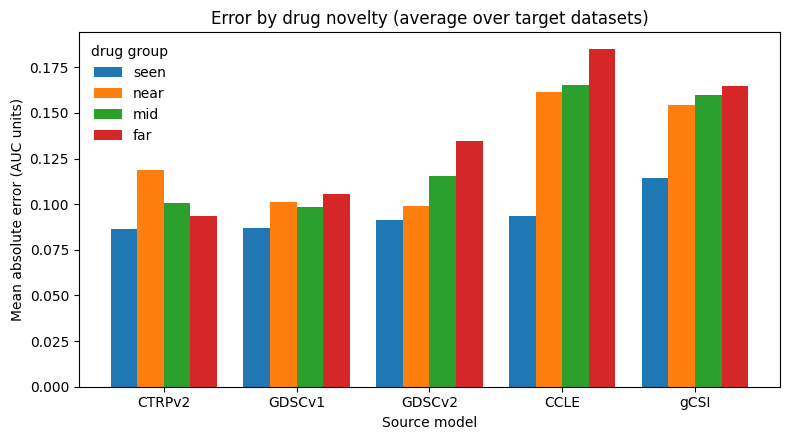

In [11]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score, r2_score

WORK_DIR = Path("/kaggle/working"); RAW = WORK_DIR / "csa_data" / "raw_data"
OUT_DIR = WORK_DIR / "outputs"; PRED_DIR = OUT_DIR / "predictions_xgb_gpu"
ND_DIR = OUT_DIR / "novelty"; ND_DIR.mkdir(exist_ok=True)
FIG_DIR = OUT_DIR / "figures"; FIG_DIR.mkdir(exist_ok=True)
K, MIN_N = 0, 100
order = ["CTRPv2", "GDSCv1", "GDSCv2", "CCLE", "gCSI"]

# ---- Drug similarity (Tanimoto on ECFP4 bits) ----
fp = pd.read_csv(RAW / "x_data" / "drug_ecfp4_nbits512.tsv", sep="\t", index_col=0)
F = fp.to_numpy(dtype=np.float32); drug_ids = fp.index.to_numpy()
bits = F.sum(1); inter = F @ F.T
union = bits[:, None] + bits[None, :] - inter
tani = np.divide(inter, union, out=np.zeros_like(inter), where=union > 0)
np.fill_diagonal(tani, 1.0)                                   # a drug is identical to itself
pos = {d: i for i, d in enumerate(drug_ids)}

resp_drug = pd.read_csv(RAW / "y_data" / "response.tsv", sep="\t", usecols=["improve_chem_id"])["improve_chem_id"]
def read_ids(p): return [int(x) for x in open(p).read().split()]

train_drugs, nn_sim = {}, {}
for s in order:
    ids = read_ids(RAW / "splits" / f"{s}_split_{K}_train.txt")
    train_drugs[s] = set(resp_drug.iloc[ids])
    tr_idx = np.array([pos[d] for d in train_drugs[s] if d in pos])
    nn_sim[s] = tani[:, tr_idx].max(1)                        # nearest training drug, for every drug
pd.DataFrame(nn_sim, index=drug_ids).to_csv(ND_DIR / "drug_nn_similarity_split0.csv")

# ---- Per-pair analysis ----
BIN_ORDER = ["seen", "near", "mid", "far"]
pair_rows, bin_rows = [], []
for s in order:
    f = PRED_DIR / f"{s}_split{K}.parquet"
    if not f.exists():
        print(f"[skip] no predictions for {s} split {K}"); continue
    P = pd.read_parquet(f, columns=["target", "improve_chem_id", "auc", "y_pred"])
    nn = pd.Series(nn_sim[s], index=drug_ids)
    for t in order:
        if t == s: continue
        d = P[P.target == t]
        nov = 1 - d.improve_chem_id.map(nn).to_numpy()
        seen = d.improve_chem_id.isin(train_drugs[s]).to_numpy()
        ok = ~np.isnan(nov)
        nov, seen = nov[ok], seen[ok]
        y, p = d.auc.to_numpy()[ok], d.y_pred.to_numpy()[ok]
        err = np.abs(y - p); un = ~seen
        hi = err >= np.quantile(err, 0.75)
        rec = {"source": s, "target": t, "n": len(err), "share_unseen": un.mean(),
               "mean_novelty_all": nov.mean(), "mean_novelty_unseen": nov[un].mean() if un.any() else np.nan,
               "rho_novelty_error_unseen": spearmanr(nov[un], err[un])[0] if un.sum() >= MIN_N else np.nan,
               "warn_auc_novelty": roc_auc_score(hi, nov), "warn_auc_unseen_flag": roc_auc_score(hi, un.astype(float))}
        pair_rows.append(rec)

        lab = np.full(len(err), "seen", dtype=object)
        if un.sum() >= 3:
            r = pd.Series(nov[un]).rank(method="first")
            lab[un] = pd.qcut(r, 3, labels=["near", "mid", "far"]).astype(str)
        for b in BIN_ORDER:
            m = lab == b
            if m.sum() == 0: continue
            bin_rows.append({"source": s, "target": t, "bin": b, "n": int(m.sum()),
                             "mean_novelty": nov[m].mean(), "mae": err[m].mean(),
                             "r2": r2_score(y[m], p[m]) if m.sum() >= MIN_N and y[m].std() > 0 else np.nan})

pm = pd.DataFrame(pair_rows); bn = pd.DataFrame(bin_rows)
pm.to_csv(ND_DIR / "novelty_pair_metrics.csv", index=False)
bn.to_csv(ND_DIR / "novelty_bins.csv", index=False)

print("Per pair: novelty vs error (unseen rows) and early-warning AUC")
display(pm.round(3))
print("\nMean absolute error by novelty group (rows = source -> target)")
display(bn.pivot_table(index=["source", "target"], columns="bin", values="mae").reindex(columns=BIN_ORDER).round(3))
print("\nR² by novelty group (blank = fewer than MIN_N rows)")
display(bn.pivot_table(index=["source", "target"], columns="bin", values="r2").reindex(columns=BIN_ORDER).round(2))
print("\nEarly-warning AUC averaged over target datasets (0.5 = no better than chance)")
display(pm.groupby("source")[["warn_auc_novelty", "warn_auc_unseen_flag"]].mean()
        .reindex([o for o in order if o in set(pm.source)]).round(3))

# ---- Across pairs: does novelty add information beyond the unseen-drug share? ----
gap = pd.read_csv(OUT_DIR / "generalisation_gap.csv")
tab = gap.merge(pm, on=["source", "target"])
assoc = pd.DataFrame([{"measure": c, "spearman_rho_with_r2_gap": spearmanr(tab[c], tab.r2_gap)[0], "n_pairs": len(tab)}
                      for c in ["share_unseen", "mean_novelty_all", "mean_novelty_unseen"]])
print("\nAcross the cross-dataset pairs (descriptive; pairs are not independent)")
display(assoc.round(3))

# ---- Figure ----
mean_mae = bn.groupby(["source", "bin"]).mae.mean().unstack().reindex(columns=BIN_ORDER)
mean_mae = mean_mae.reindex([o for o in order if o in mean_mae.index])
fig, ax = plt.subplots(figsize=(8, 4.5)); w = 0.2
for j, b in enumerate(BIN_ORDER):
    ax.bar(np.arange(len(mean_mae)) + (j - 1.5) * w, mean_mae[b], w, label=b)
ax.set_xticks(range(len(mean_mae))); ax.set_xticklabels(mean_mae.index)
ax.set_ylabel("Mean absolute error (AUC units)"); ax.set_xlabel("Source model")
ax.set_title("Error by drug novelty (average over target datasets)"); ax.legend(frameon=False, title="drug group")
plt.tight_layout()
for ext in ("png", "pdf", "svg"):
    fig.savefig(FIG_DIR / f"novelty_error_bins.{ext}", dpi=300)
plt.show()

## 26. Does drug novelty explain the SHAP pattern seen for the CCLE model?

**Background.** In Section 23, rows on which the CCLE-trained model relied more on drug features had larger errors, even among
drugs it never saw (Spearman ρ about −0.4). Drug novelty (Section 25) is a possible common cause: a drug far from the training drugs may
both shift the attribution towards drug features and raise the error.

**Method.** For every SHAP-sampled row (Section 20), the drug novelty is attached. For each cross-dataset pair, in two subsets
(all sampled rows; rows with unseen drugs, novelty > 0), the following are computed:
- `rho_gene_err`: Spearman correlation between the row's gene-expression share of |SHAP| and its absolute error;
- `partial_gene_err_given_novelty`: the same correlation after removing the linear effect of the **rank** of novelty from both
  variables (partial rank correlation);
- `rho_novelty_gene` and `rho_novelty_err`: how novelty relates to each of the two.

**Reading the result.** If the partial correlation is close to zero while the plain one is not, the SHAP pattern is a side effect of drug
novelty. If it stays, the model's feature use carries information about its errors beyond how unusual the drug is.

**Uses target labels:** yes (absolute error).  **Outputs.** `novelty/shap_novelty_partial.csv`.

**Limit.** Split 0, at most 5,000 sampled rows per pair, linear control for novelty only.
Some rows' novelty is identical (ties), which is handled by ranking.

In [13]:
from scipy.stats import rankdata, spearmanr
SHAP_DIR = OUT_DIR / "shap"; MIN_N = 100
order = ["CTRPv2", "GDSCv1", "GDSCv2", "CCLE", "gCSI"]

rows = pd.read_parquet(SHAP_DIR / "shap_rows_split0.parquet")
rows["gene_share"] = rows.gene_abs / (rows.gene_abs + rows.drug_abs)
rows["drug"] = resp_drug.iloc[rows.row_id.to_numpy()].to_numpy()
nn = pd.read_csv(ND_DIR / "drug_nn_similarity_split0.csv", index_col=0)
rows["novelty"] = np.nan
for s in nn.columns:
    m = (rows.source == s).to_numpy()
    rows.loc[m, "novelty"] = 1 - nn[s].reindex(rows.loc[m, "drug"]).to_numpy()

def partial_spearman(x, y, z):
    rx, ry, rz = rankdata(x), rankdata(y), rankdata(z)
    if rz.std() == 0: return np.nan
    res = lambda a: a - np.polyval(np.polyfit(rz, a, 1), rz)
    return float(np.corrcoef(res(rx), res(ry))[0, 1])

out = []
for s in order:
    for t in order:
        if s == t: continue
        d = rows[(rows.source == s) & (rows.dataset == t)].dropna(subset=["novelty"])
        for subset, dd in [("all", d), ("unseen", d[d.novelty > 0])]:
            if len(dd) < MIN_N: continue
            out.append({"source": s, "target": t, "subset": subset, "n": len(dd),
                        "rho_gene_err": spearmanr(dd.gene_share, dd.abs_err)[0],
                        "partial_gene_err_given_novelty": partial_spearman(dd.gene_share, dd.abs_err, dd.novelty),
                        "rho_novelty_gene": spearmanr(dd.novelty, dd.gene_share)[0],
                        "rho_novelty_err": spearmanr(dd.novelty, dd.abs_err)[0]})
sp = pd.DataFrame(out)
sp.to_csv(ND_DIR / "shap_novelty_partial.csv", index=False)

for subset in ["all", "unseen"]:
    print(f"\nSubset: {subset} rows. Averaged over target datasets")
    display(sp[sp.subset == subset].groupby("source")[["rho_gene_err", "partial_gene_err_given_novelty",
            "rho_novelty_gene", "rho_novelty_err"]].mean().reindex([o for o in order if o in set(sp.source)]).round(3))
print("\nCCLE-trained model, rows with unseen drugs, per target dataset")
display(sp[(sp.source == "CCLE") & (sp.subset == "unseen")].round(3))


Subset: all rows. Averaged over target datasets


,rho_gene_err,partial_gene_err_given_novelty,rho_novelty_gene,rho_novelty_err
source,,,,
CTRPv2,0.064,0.067,-0.045,0.078
GDSCv1,0.007,0.023,-0.106,0.113
GDSCv2,-0.028,0.001,-0.219,0.144
CCLE,-0.348,-0.327,-0.163,0.199
gCSI,0.041,0.051,-0.119,0.079



Subset: unseen rows. Averaged over target datasets


,rho_gene_err,partial_gene_err_given_novelty,rho_novelty_gene,rho_novelty_err
source,,,,
CTRPv2,0.045,-0.001,-0.325,-0.084
GDSCv1,-0.011,-0.006,-0.116,0.018
GDSCv2,-0.102,-0.105,-0.018,0.157
CCLE,-0.286,-0.272,-0.069,0.092
gCSI,0.055,0.057,-0.031,0.011



CCLE-trained model, rows with unseen drugs, per target dataset


,source,target,subset,n,rho_gene_err,partial_gene_err_given_novelty,rho_novelty_gene,rho_novelty_err
25,CCLE,CTRPv2,unseen,4794,-0.483,-0.460,-0.209,0.200
27,CCLE,GDSCv1,unseen,4731,-0.380,-0.362,-0.177,0.158
29,CCLE,GDSCv2,unseen,4502,-0.434,-0.435,-0.014,0.113
31,CCLE,gCSI,unseen,3078,0.153,0.168,0.125,-0.104


## 27. Update the evidence table: corrected replicate benchmark and novelty columns

**Correction.** In Section 24 the squared correlation between two datasets' measurements of the same drug-cell
pairs was named `agreement_ceiling_r2` and described as an upper bound. That is not correct: a model that
captures the true signal can score above the R² obtained by using one lab's measurement to predict the other
(two pairs do). The column is renamed `replicate_r2` and described as a **benchmark**, not a ceiling.

**New columns (from Sections 25 and 26).**
- `mean_novelty_unseen`: average chemical distance of unseen target drugs from the source's training drugs.
- `rho_novelty_error_unseen`: Spearman correlation between novelty and absolute error on unseen-drug rows.
- `warn_auc_novelty` / `warn_auc_unseen_flag`: ability of novelty, and of the plain unseen flag, to flag the 25% largest-error rows.
- `shap_gene_error_rho_unseen` / `shap_gene_error_partial_novelty_unseen`: correlation between gene-expression share of |SHAP| and
  error on unseen-drug rows, before and after controlling for novelty.

**Outputs.** `evidence/evidence_per_pair.csv` and `evidence_per_pair.json` are overwritten, with an extended `limitations` list.
This file is the only input the reasoning agent (Stage B4) receives.

In [14]:
import json
EV_DIR = OUT_DIR / "evidence"
ev = pd.read_csv(EV_DIR / "evidence_per_pair.csv")
ev = ev.rename(columns={"agreement_ceiling_r2": "replicate_r2"})

new_cols = ["mean_novelty_unseen", "rho_novelty_error_unseen", "warn_auc_novelty", "warn_auc_unseen_flag",
            "shap_gene_error_rho_unseen", "shap_gene_error_partial_novelty_unseen"]
ev = ev.drop(columns=[c for c in new_cols if c in ev.columns])

nd = pd.read_csv(ND_DIR / "novelty_pair_metrics.csv")[["source", "target", "mean_novelty_unseen",
        "rho_novelty_error_unseen", "warn_auc_novelty", "warn_auc_unseen_flag"]]
sp_u = (pd.read_csv(ND_DIR / "shap_novelty_partial.csv").query("subset == 'unseen'")
        [["source", "target", "rho_gene_err", "partial_gene_err_given_novelty"]]
        .rename(columns={"rho_gene_err": "shap_gene_error_rho_unseen",
                         "partial_gene_err_given_novelty": "shap_gene_error_partial_novelty_unseen"}))
ev = ev.merge(nd, on=["source", "target"], how="left").merge(sp_u, on=["source", "target"], how="left")
ev.to_csv(EV_DIR / "evidence_per_pair.csv", index=False)

limitations = [
    "Split 0 only unless stated otherwise; all pairs share one omics table and one drug-descriptor table.",
    "The 20 pairs are not independent: each dataset appears as source and as target several times.",
    "Seen-drug R2 is computed on a restricted subset, not the same rows as the overall R2.",
    "replicate_r2 (squared correlation between two datasets on shared drug-cell pairs) is a benchmark, not an upper bound on model performance.",
    "Domain-classifier AUC for drug descriptors is near 1 for every pair and does not separate pairs.",
    "SHAP describes model behaviour, not biological causation; single-feature SHAP rankings are unstable for correlated features.",
    "Drug novelty is a chemical (ECFP4, 512-bit) distance only and does not capture mechanism of action."]
with open(EV_DIR / "evidence_per_pair.json", "w") as f:
    json.dump({"limitations": limitations, "pairs": json.loads(ev.round(4).to_json(orient="records"))}, f, indent=2)

pd.set_option("display.width", 220)
display(ev[["source", "target", "r2_gap", "share_unseen_drug", "replicate_r2", "mean_novelty_unseen",
            "rho_novelty_error_unseen", "warn_auc_novelty", "warn_auc_unseen_flag",
            "shap_gene_error_rho_unseen", "shap_gene_error_partial_novelty_unseen"]].round(2))

,source,target,r2_gap,share_unseen_drug,replicate_r2,mean_novelty_unseen,rho_novelty_error_unseen,warn_auc_novelty,warn_auc_unseen_flag,shap_gene_error_rho_unseen,shap_gene_error_partial_novelty_unseen
0,CCLE,CTRPv2,2.13,0.96,0.68,0.76,0.20,0.62,0.52,-0.48,-0.46
1,gCSI,CTRPv2,1.83,0.97,0.55,0.77,0.06,0.53,0.51,0.07,0.07
2,CCLE,GDSCv2,1.37,0.90,0.50,0.74,0.10,0.57,0.54,-0.43,-0.44
3,CCLE,GDSCv1,1.36,0.95,0.61,0.74,0.16,0.61,0.53,-0.38,-0.36
4,gCSI,GDSCv1,1.28,0.96,0.47,0.76,0.04,0.52,0.51,0.04,0.05
5,gCSI,GDSCv2,1.18,0.89,0.50,0.76,0.08,0.56,0.53,0.02,0.02
6,GDSCv2,CTRPv2,0.94,0.85,0.63,0.69,0.18,0.64,0.55,-0.08,-0.06
7,gCSI,CCLE,0.87,0.76,0.61,0.74,-0.14,0.56,0.59,0.09,0.09
8,CCLE,gCSI,0.71,0.62,0.61,0.70,-0.10,0.62,0.63,0.15,0.17
9,GDSCv1,CTRPv2,0.71,0.75,0.48,0.67,0.14,0.64,0.58,-0.02,-0.01


## 11b. Remaining splits (1 to 4) on a single GPU, resumable with a time budget

**Purpose.** The baseline paper averages over 10 random splits. Splits 1 to 4 are trained here, giving 5 splits in total
(extend `RUN_SPLITS` to 5 to 9 later if quota allows).

**Settings.** Identical to split 0 (Section 11: 2000 trees maximum, learning rate 0.05, depth 6, early stopping 50) so that
all splits are comparable. GPU 0 only; one job at a time.

**Safety.** A job is skipped if its score file exists (the file is written last). No new job starts after `MAX_MINUTES`.
Free RAM is printed before each job.

**Outputs.** `scores_xgb_gpu/`, `predictions_xgb_gpu/`, `models_xgb_gpu/` for each source and split.

In [2]:
import gc, time, psutil
import numpy as np, pandas as pd, xgboost as xgb

need = ["make_xy", "split_ids", "splits", "names", "score", "OUT_DIR", "SEED"]
missing = [v for v in need if v not in globals()]
assert not missing, f"Missing in memory: {missing}. Run the session-restore cell (0b) first."

GPU_ID       = 0                                   # the only GPU used
MODEL_TAG    = "xgb_gpu"
RUN_SPLITS   = [0,1, 2, 3, 4]
SOURCE_ORDER = ["CCLE", "gCSI", "GDSCv2", "GDSCv1", "CTRPv2"]
MAX_MINUTES  = 120
CHUNK        = 50_000

XGB_PARAMS = dict(                                  # same as split 0
    n_estimators=2000, learning_rate=0.05, max_depth=6,
    subsample=0.8, colsample_bytree=0.5, min_child_weight=1,
    tree_method="hist", device=f"cuda:{GPU_ID}",
    objective="reg:squarederror", eval_metric="rmse",
    early_stopping_rounds=50, random_state=SEED, verbosity=0)

RES_DIR   = OUT_DIR / f"scores_{MODEL_TAG}";      RES_DIR.mkdir(exist_ok=True)
PRED_DIR  = OUT_DIR / f"predictions_{MODEL_TAG}"; PRED_DIR.mkdir(exist_ok=True)
MODEL_DIR = OUT_DIR / f"models_{MODEL_TAG}";      MODEL_DIR.mkdir(exist_ok=True)

def train_source(source, k):
    Xtr, ytr, _ = make_xy(split_ids(source, k, "train"))
    Xva, yva, _ = make_xy(split_ids(source, k, "val"))
    model = xgb.XGBRegressor(**XGB_PARAMS)
    model.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    del Xtr, Xva
    return model

def predict_chunked(model, rows):
    booster, rng = model.get_booster(), (0, model.best_iteration + 1)
    ys, ps, metas = [], [], []
    for i in range(0, len(rows), CHUNK):
        X, y, meta = make_xy(rows[i:i + CHUNK])
        ps.append(booster.inplace_predict(X, iteration_range=rng))
        ys.append(y); metas.append(meta); del X
    return np.concatenate(ys), np.concatenate(ps), pd.concat(metas)

def evaluate_source(model, source, k):
    results, preds = [], []
    for target in names:
        rows = split_ids(target, k, "test") if target == source else splits[(target, None, "all")]
        y, p, meta = predict_chunked(model, rows)
        results.append({"source": source, "target": target, "split": k, **score(y, p)})
        out = meta.reset_index().rename(columns={"index": "row_id"})
        out["source"], out["target"], out["split"], out["y_pred"] = source, target, k, p
        preds.append(out)
    return pd.DataFrame(results), pd.concat(preds, ignore_index=True)

jobs = [(s, k) for k in RUN_SPLITS for s in SOURCE_ORDER
        if not (RES_DIR / f"{s}_split{k}.csv").exists()]
print(f"{len(jobs)} jobs to run (GPU {GPU_ID} only)\n")

t_all = time.time()
for s, k in jobs:
    if (time.time() - t_all) / 60 > MAX_MINUTES:
        print(f"Time budget of {MAX_MINUTES} min reached; stopping. Re-run the cell to continue.")
        break
    print(f"free RAM {psutil.virtual_memory().available/1e9:.1f} GB | starting {s} split {k}")
    t0 = time.time()
    model = train_source(s, k)
    t_train = time.time() - t0
    scores_df, preds_df = evaluate_source(model, s, k)
    model.save_model(str(MODEL_DIR / f"{s}_split{k}.json"))
    preds_df.to_parquet(PRED_DIR / f"{s}_split{k}.parquet", index=False)
    scores_df.to_csv(RES_DIR / f"{s}_split{k}.csv", index=False)       # written last = "done"
    print(f"[done] {s} split {k}: train {t_train:.0f}s, total {time.time()-t0:.0f}s, best_iter {model.best_iteration}")
    del model, scores_df, preds_df; gc.collect()

print(f"\nFinished in {(time.time()-t_all)/60:.1f} min")
print("Score files per source:", {n: len(list(RES_DIR.glob(f'{n}_split*.csv'))) for n in names})

AssertionError: Missing in memory: ['make_xy', 'split_ids', 'splits', 'names', 'score', 'OUT_DIR', 'SEED']. Run the session-restore cell (0b) first.

## 11b. Self-contained run: rebuild state, then train splits 0 to 4 on one GPU (resumable)

**Purpose.** Train one XGBoost model per source dataset for splits 0 to 4 and test each on all five datasets,
using GPU 0 only. This cell does not rely on any earlier cell: it first rebuilds the response table, the paper's
splits, the features and the scoring function from the downloaded benchmark data (as in Sections 3 to 8).

**Settings.** XGBoost, `tree_method="hist"`, 2000 trees maximum, learning rate 0.05, depth 6, early stopping 50;
1,000 most variable genes (chosen without using response values) plus Mordred descriptors.

**Safety.** A job is skipped if its score file exists (written last). No new job starts after `MAX_MINUTES`.
At the end, a results zip is written for download.

**Requirement.** `csa_data` must exist (run the download cell if the session was reset); Internet is not needed otherwise.

In [1]:
import os, csv, gc, time, random, zipfile
from pathlib import Path
import numpy as np, pandas as pd, psutil, xgboost as xgb
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import r2_score, mean_squared_error

# ---------------- Settings ----------------
SEED, N_SPLITS, N_GENES = 42, 10, 1000
GPU_ID       = 0                                  # the only GPU used
RUN_SPLITS   = list(range(10))   # was [0, 1, 2, 3, 4]
MAX_MINUTES  = 120               # keep. It stops cleanly; re-run the cell to continue.
SOURCE_ORDER = ["CCLE", "gCSI", "GDSCv2", "GDSCv1", "CTRPv2"]
#MAX_MINUTES  = 120
CHUNK        = 50_000
MODEL_TAG    = "xgb_gpu"

WORK_DIR = Path("/kaggle/working"); RAW = WORK_DIR / "csa_data" / "raw_data"
OUT_DIR = WORK_DIR / "outputs"; OUT_DIR.mkdir(exist_ok=True)
names = ["CTRPv2", "GDSCv1", "GDSCv2", "CCLE", "gCSI"]
random.seed(SEED); np.random.seed(SEED); os.environ["PYTHONHASHSEED"] = str(SEED)
import hashlib, subprocess, zipfile
DATA_URL = "https://zenodo.org/records/15258451/files/csa_data.zip?download=1"
EXPECTED_MD5 = "984eabec912914e62d56d8e0073475f8"

if not RAW.exists():
    candidates = [WORK_DIR / "csa_data.zip"] + list(Path("/kaggle/input").rglob("csa_data.zip"))
    zip_path = next((p for p in candidates if p.exists()), None)
    if zip_path is None:                                   # nothing local: download it
        zip_path = WORK_DIR / "csa_data.zip"
        try:
            subprocess.run(["wget", "-q", "-O", str(zip_path), DATA_URL], check=True)
        except subprocess.CalledProcessError:
            raise RuntimeError("Download failed: switch Internet ON in the notebook settings and re-run.")
    h = hashlib.md5()
    with open(zip_path, "rb") as f:
        while block := f.read(1 << 20):
            h.update(block)
    assert h.hexdigest() == EXPECTED_MD5, "Checksum mismatch: the zip is incomplete; delete it and re-run."
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(WORK_DIR)
    print("Benchmark data restored from", zip_path)
assert RAW.exists(), "csa_data still not found after extraction."

# ---------------- Rebuild state ----------------
resp = pd.read_csv(RAW / "y_data" / "response.tsv", sep="\t", low_memory=False)

def read_ids(path):
    with open(path) as f:
        return [int(x) for x in f.read().split()]

splits = {}
for n in names:
    splits[(n, None, "all")] = read_ids(RAW / "splits" / f"{n}_all.txt")
    for k in range(N_SPLITS):
        for part in ("train", "val", "test"):
            splits[(n, k, part)] = read_ids(RAW / "splits" / f"{n}_split_{k}_{part}.txt")
def split_ids(name, k, part): return splits[(name, k, part)]

def load_omics(path):
    with open(path) as f:
        reader = csv.reader(f, delimiter="\t"); next(reader); k = 0
        for row in reader:
            if row[0] == "": k += 1
            else: break
    df = pd.read_csv(path, sep="\t", index_col=0, skiprows=range(1, 1 + k))
    return df.apply(pd.to_numeric, errors="coerce").astype(np.float32)

used_cells, used_drugs = set(resp["improve_sample_id"]), set(resp["improve_chem_id"])
omics = load_omics(RAW / "x_data" / "cancer_gene_expression.tsv")
omics = omics.loc[omics.index.isin(used_cells)]
omics = omics[omics.var(axis=0).nlargest(N_GENES).index]
omics.columns = ["ge." + c for c in omics.columns]
drug = pd.read_csv(RAW / "x_data" / "drug_mordred.tsv", sep="\t", index_col=0)
drug = drug.apply(pd.to_numeric, errors="coerce").astype(np.float32)
drug = drug.loc[drug.index.isin(used_drugs)]
drug = drug.loc[:, drug.nunique(dropna=True) > 1]

omics_np, drug_np = omics.to_numpy(np.float32), drug.to_numpy(np.float32)
omics_pos = {c: i for i, c in enumerate(omics.index)}
drug_pos = {d: i for i, d in enumerate(drug.index)}
FEATURE_NAMES = list(omics.columns) + list(drug.columns); N_OM = omics_np.shape[1]
print("Features:", omics.shape[1], "gene +", drug.shape[1], "drug =", len(FEATURE_NAMES))
del omics, drug

def make_xy(row_ids, chunk=20_000):
    d = resp.loc[row_ids, ["improve_sample_id", "improve_chem_id", "auc"]]
    ci = d["improve_sample_id"].map(omics_pos).to_numpy()
    di = d["improve_chem_id"].map(drug_pos).to_numpy()
    X = np.empty((len(d), N_OM + drug_np.shape[1]), dtype=np.float32)
    for i in range(0, len(d), chunk):
        sl = slice(i, i + chunk)
        X[sl, :N_OM] = omics_np[ci[sl]]; X[sl, N_OM:] = drug_np[di[sl]]
    return X, d["auc"].to_numpy(dtype=np.float32), d

def score(y_true, y_pred):
    return {"r2": float(r2_score(y_true, y_pred)),
            "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "pcc": float(pearsonr(y_true, y_pred)[0]),
            "scc": float(spearmanr(y_true, y_pred)[0]), "n": int(len(y_true))}

# ---------------- Training ----------------
XGB_PARAMS = dict(
    n_estimators=2000, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.5,
    min_child_weight=1, tree_method="hist", device=f"cuda:{GPU_ID}",
    objective="reg:squarederror", eval_metric="rmse", early_stopping_rounds=50,
    random_state=SEED, verbosity=0)

RES_DIR   = OUT_DIR / f"scores_{MODEL_TAG}";      RES_DIR.mkdir(exist_ok=True)
PRED_DIR  = OUT_DIR / f"predictions_{MODEL_TAG}"; PRED_DIR.mkdir(exist_ok=True)
MODEL_DIR = OUT_DIR / f"models_{MODEL_TAG}";      MODEL_DIR.mkdir(exist_ok=True)

def train_source(source, k):
    Xtr, ytr, _ = make_xy(split_ids(source, k, "train"))
    Xva, yva, _ = make_xy(split_ids(source, k, "val"))
    model = xgb.XGBRegressor(**XGB_PARAMS)
    model.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    del Xtr, Xva
    return model

def predict_chunked(model, rows):
    booster, rng = model.get_booster(), (0, model.best_iteration + 1)
    ys, ps, metas = [], [], []
    for i in range(0, len(rows), CHUNK):
        X, y, meta = make_xy(rows[i:i + CHUNK])
        ps.append(booster.inplace_predict(X, iteration_range=rng))
        ys.append(y); metas.append(meta); del X
    return np.concatenate(ys), np.concatenate(ps), pd.concat(metas)

def evaluate_source(model, source, k):
    results, preds = [], []
    for target in names:
        rows = split_ids(target, k, "test") if target == source else splits[(target, None, "all")]
        y, p, meta = predict_chunked(model, rows)
        results.append({"source": source, "target": target, "split": k, **score(y, p)})
        out = meta.reset_index().rename(columns={"index": "row_id"})
        out["source"], out["target"], out["split"], out["y_pred"] = source, target, k, p
        preds.append(out)
    return pd.DataFrame(results), pd.concat(preds, ignore_index=True)

jobs = [(s, k) for k in RUN_SPLITS for s in SOURCE_ORDER if not (RES_DIR / f"{s}_split{k}.csv").exists()]
print(f"\n{len(jobs)} jobs to run (GPU {GPU_ID} only)\n")
t_all = time.time()
for s, k in jobs:
    if (time.time() - t_all) / 60 > MAX_MINUTES:
        print(f"Time budget of {MAX_MINUTES} min reached; stopping. Re-run the cell to continue."); break
    print(f"free RAM {psutil.virtual_memory().available/1e9:.1f} GB | starting {s} split {k}", flush=True)
    t0 = time.time()
    model = train_source(s, k); t_train = time.time() - t0
    scores_df, preds_df = evaluate_source(model, s, k)
    model.save_model(str(MODEL_DIR / f"{s}_split{k}.json"))
    preds_df.to_parquet(PRED_DIR / f"{s}_split{k}.parquet", index=False)
    scores_df.to_csv(RES_DIR / f"{s}_split{k}.csv", index=False)        # written last = "done"
    print(f"[done] {s} split {k}: train {t_train:.0f}s, total {time.time()-t0:.0f}s, best_iter {model.best_iteration}", flush=True)
    del model, scores_df, preds_df; gc.collect()

print(f"\nFinished in {(time.time()-t_all)/60:.1f} min")
print("Score files per source:", {n: len(list(RES_DIR.glob(f'{n}_split*.csv'))) for n in names})

# ---------------- Results zip for download ----------------
bundle = WORK_DIR / "results_backup.zip"
with zipfile.ZipFile(bundle, "w", zipfile.ZIP_DEFLATED) as z:
    for sub in [f"scores_{MODEL_TAG}", f"predictions_{MODEL_TAG}", f"models_{MODEL_TAG}"]:
        for p in (OUT_DIR / sub).rglob("*"):
            if p.is_file(): z.write(p, p.relative_to(OUT_DIR))
print(f"Backup written: {bundle} ({bundle.stat().st_size/1e6:.1f} MB). Download it from the Output panel.")

Benchmark data restored from /kaggle/working/csa_data.zip


KeyboardInterrupt: 

## 28. Restore saved results from the backup zip

**Purpose.** After a session reset, `/kaggle/working` is empty. This cell unpacks `results_backup.zip` into `outputs/`
so the saved score files, predictions and models are available again, without retraining.

**Inputs.** `results_backup.zip` (in `/kaggle/working` or attached under `/kaggle/input`).
**Outputs.** `outputs/scores_xgb_gpu/`, `predictions_xgb_gpu/`, `models_xgb_gpu/` (and any other folders in the zip).
**Check.** Each of the five sources should have 5 score files (splits 0 to 4).

In [7]:
import shutil
from pathlib import Path

WORK_DIR = Path("/kaggle/working"); OUT_DIR = WORK_DIR / "outputs"; OUT_DIR.mkdir(exist_ok=True)
RES_DIR = OUT_DIR / "scores_xgb_gpu"
names = ["CTRPv2", "GDSCv1", "GDSCv2", "CCLE", "gCSI"]

# find the folder that contains scores_xgb_gpu, wherever the upload put it
hit = next((p.parent for p in Path("/kaggle/input").rglob("scores_xgb_gpu") if p.is_dir()), None)
assert hit, "scores_xgb_gpu not found under /kaggle/input. Paste the listing from the check above."
for sub in hit.iterdir():
    dest = OUT_DIR / sub.name
    if sub.is_dir():
        shutil.copytree(sub, dest, dirs_exist_ok=True)
    else:
        shutil.copy(sub, dest)
print("Copied from", hit)

print("Folders in outputs/:", sorted(p.name for p in OUT_DIR.iterdir()))
print("Score files per source:", {n: len(list(RES_DIR.glob(f"{n}_split*.csv"))) for n in names})
print("Evidence file present:", (OUT_DIR / "evidence" / "evidence_per_pair.json").exists())

Copied from /kaggle/input/datasets/aniketsharma69420/result-backup
Folders in outputs/: ['models_xgb_gpu', 'predictions_xgb_gpu', 'scores_xgb_gpu']
Score files per source: {'CTRPv2': 5, 'GDSCv1': 5, 'GDSCv2': 5, 'CCLE': 5, 'gCSI': 5}
Evidence file present: False


## 29. Load the score files and check completeness

**Purpose.** Collect all per-job score files into one table and confirm that every source → target pair
has exactly five splits (0 to 4), so averages are over the same number of splits everywhere.

In [8]:
import numpy as np, pandas as pd

S = pd.concat([pd.read_csv(f) for f in sorted(RES_DIR.glob("*_split*.csv"))], ignore_index=True)
S.to_csv(OUT_DIR / "all_scores_long.csv", index=False)
cnt = S.groupby(["source", "target"]).split.nunique().unstack()
display(cnt)
assert (cnt.fillna(5) == 5).all().all(), "Some pairs do not have 5 splits. Re-run the training cell for the missing ones."
N_SPLITS_USED = int(S.split.nunique()); print("Splits used:", sorted(S.split.unique()))

target,CCLE,CTRPv2,GDSCv1,GDSCv2,gCSI
source,,,,,
CCLE,5,5,5,5,5
CTRPv2,5,5,5,5,5
GDSCv1,5,5,5,5,5
GDSCv2,5,5,5,5,5
gCSI,5,5,5,5,5


Splits used: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


In [9]:
from scipy import stats

home = S[S.source == S.target].set_index(["source", "split"])[["r2", "pcc"]].add_suffix("_within")
X = S[S.source != S.target].join(home, on=["source", "split"])
X["r2_gap"] = X.r2_within - X.r2
X["pcc_gap"] = X.pcc_within - X.pcc

def summ(g, col):
    v = g[col].to_numpy(); n = len(v); sd = v.std(ddof=1)
    h = stats.t.ppf(0.975, n - 1) * sd / np.sqrt(n)
    return pd.Series({f"{col}_mean": v.mean(), f"{col}_sd": sd, f"{col}_ci_lo": v.mean() - h, f"{col}_ci_hi": v.mean() + h})

rows = []
for (s, t), g in X.groupby(["source", "target"]):
    rows.append(pd.concat([pd.Series({"source": s, "target": t, "n_splits": len(g)})]
                          + [summ(g, c) for c in ("r2", "r2_within", "r2_gap", "pcc", "pcc_gap")]))
gap5 = pd.DataFrame(rows).sort_values("r2_gap_mean", ascending=False).reset_index(drop=True)
gap5["gap_clearly_positive"] = gap5.r2_gap_ci_lo > 0
gap5.to_csv(OUT_DIR / "generalisation_gap_5split.csv", index=False)
display(gap5[["source", "target", "r2_mean", "r2_sd", "r2_gap_mean", "r2_gap_ci_lo", "r2_gap_ci_hi", "gap_clearly_positive"]].round(3))

# 5x5 matrices, mean and SD
for m in ("r2", "pcc"):
    mean = S.groupby(["source", "target"])[m].mean().unstack().reindex(index=names, columns=names)
    sd = S.groupby(["source", "target"])[m].std().unstack().reindex(index=names, columns=names)
    print(f"\n{m.upper()} mean"); display(mean.round(3)); print(f"{m.upper()} SD"); display(sd.round(3))
    mean.to_csv(OUT_DIR / f"matrix_{m}_mean_5split.csv"); sd.to_csv(OUT_DIR / f"matrix_{m}_sd_5split.csv")

,source,target,r2_mean,r2_sd,r2_gap_mean,r2_gap_ci_lo,r2_gap_ci_hi,gap_clearly_positive
0,CCLE,CTRPv2,-1.334,0.039,2.143,2.099,2.188,True
1,gCSI,CTRPv2,-1.044,0.063,1.829,1.741,1.916,True
2,CCLE,GDSCv1,-0.572,0.027,1.381,1.350,1.412,True
3,CCLE,GDSCv2,-0.564,0.016,1.373,1.352,1.395,True
4,gCSI,GDSCv1,-0.485,0.067,1.269,1.179,1.360,True
5,gCSI,GDSCv2,-0.396,0.069,1.181,1.087,1.275,True
6,GDSCv2,CTRPv2,-0.139,0.018,0.905,0.879,0.930,True
7,gCSI,CCLE,-0.073,0.043,0.857,0.794,0.921,True
8,GDSCv1,CTRPv2,-0.018,0.012,0.722,0.701,0.742,True
9,CCLE,gCSI,0.094,0.025,0.715,0.686,0.744,True



R2 mean


target,CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
source,,,,,
CTRPv2,0.803,0.260,0.446,0.570,0.500
GDSCv1,-0.018,0.704,0.355,0.557,0.526
GDSCv2,-0.139,0.168,0.766,0.240,0.527
CCLE,-1.334,-0.572,-0.564,0.809,0.094
gCSI,-1.044,-0.485,-0.396,-0.073,0.785


R2 SD


target,CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
source,,,,,
CTRPv2,0.002,0.003,0.007,0.008,0.012
GDSCv1,0.012,0.007,0.006,0.020,0.012
GDSCv2,0.018,0.012,0.010,0.028,0.012
CCLE,0.039,0.027,0.016,0.008,0.025
gCSI,0.063,0.067,0.069,0.043,0.022



PCC mean


target,CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
source,,,,,
CTRPv2,0.896,0.526,0.677,0.774,0.726
GDSCv1,0.433,0.839,0.649,0.749,0.770
GDSCv2,0.350,0.446,0.875,0.533,0.742
CCLE,0.130,0.109,0.198,0.900,0.443
gCSI,0.094,0.143,0.301,0.332,0.887


PCC SD


target,CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
source,,,,,
CTRPv2,0.001,0.002,0.005,0.006,0.006
GDSCv1,0.004,0.004,0.004,0.015,0.004
GDSCv2,0.007,0.008,0.005,0.024,0.007
CCLE,0.006,0.006,0.008,0.005,0.014
gCSI,0.007,0.013,0.018,0.015,0.012


## 30. Cross-dataset results averaged over 5 splits (mean, SD, 95% CI)

**Purpose.** For each source → target pair, compute the generalisation gap in every split
(within-dataset R² minus cross-dataset R², same split), then summarise over the 5 splits.

**Interval.** 95% confidence interval from the t-distribution with 4 degrees of freedom.

**Limitation.** Cross-dataset target rows are identical in every split, so the SD reflects variation in the
*training split* only. Only 5 of the 10 predefined splits are used.

In [13]:
from scipy import stats

home = S[S.source == S.target].set_index(["source", "split"])[["r2", "pcc"]].add_suffix("_within")
X = S[S.source != S.target].join(home, on=["source", "split"])
X["r2_gap"] = X.r2_within - X.r2
X["pcc_gap"] = X.pcc_within - X.pcc

def summ(g, col):
    v = g[col].to_numpy(); n = len(v); sd = v.std(ddof=1)
    h = stats.t.ppf(0.975, n - 1) * sd / np.sqrt(n)
    return pd.Series({f"{col}_mean": v.mean(), f"{col}_sd": sd, f"{col}_ci_lo": v.mean() - h, f"{col}_ci_hi": v.mean() + h})

rows = []
for (s, t), g in X.groupby(["source", "target"]):
    rows.append(pd.concat([pd.Series({"source": s, "target": t, "n_splits": len(g)})]
                          + [summ(g, c) for c in ("r2", "r2_within", "r2_gap", "pcc", "pcc_gap")]))
gap5 = pd.DataFrame(rows).sort_values("r2_gap_mean", ascending=False).reset_index(drop=True)
gap5["gap_clearly_positive"] = gap5.r2_gap_ci_lo > 0
gap5.to_csv(OUT_DIR / "generalisation_gap_5split.csv", index=False)
display(gap5[["source", "target", "r2_mean", "r2_sd", "r2_gap_mean", "r2_gap_ci_lo", "r2_gap_ci_hi", "gap_clearly_positive"]].round(3))

# 5x5 matrices, mean and SD
for m in ("r2", "pcc"):
    mean = S.groupby(["source", "target"])[m].mean().unstack().reindex(index=names, columns=names)
    sd = S.groupby(["source", "target"])[m].std().unstack().reindex(index=names, columns=names)
    print(f"\n{m.upper()} mean"); display(mean.round(3)); print(f"{m.upper()} SD"); display(sd.round(3))
    mean.to_csv(OUT_DIR / f"matrix_{m}_mean_5split.csv"); sd.to_csv(OUT_DIR / f"matrix_{m}_sd_5split.csv")

,source,target,r2_mean,r2_sd,r2_gap_mean,r2_gap_ci_lo,r2_gap_ci_hi,gap_clearly_positive
0,CCLE,CTRPv2,-1.334,0.039,2.143,2.099,2.188,True
1,gCSI,CTRPv2,-1.044,0.063,1.829,1.741,1.916,True
2,CCLE,GDSCv1,-0.572,0.027,1.381,1.350,1.412,True
3,CCLE,GDSCv2,-0.564,0.016,1.373,1.352,1.395,True
4,gCSI,GDSCv1,-0.485,0.067,1.269,1.179,1.360,True
5,gCSI,GDSCv2,-0.396,0.069,1.181,1.087,1.275,True
6,GDSCv2,CTRPv2,-0.139,0.018,0.905,0.879,0.930,True
7,gCSI,CCLE,-0.073,0.043,0.857,0.794,0.921,True
8,GDSCv1,CTRPv2,-0.018,0.012,0.722,0.701,0.742,True
9,CCLE,gCSI,0.094,0.025,0.715,0.686,0.744,True



R2 mean


target,CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
source,,,,,
CTRPv2,0.803,0.260,0.446,0.570,0.500
GDSCv1,-0.018,0.704,0.355,0.557,0.526
GDSCv2,-0.139,0.168,0.766,0.240,0.527
CCLE,-1.334,-0.572,-0.564,0.809,0.094
gCSI,-1.044,-0.485,-0.396,-0.073,0.785


R2 SD


target,CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
source,,,,,
CTRPv2,0.002,0.003,0.007,0.008,0.012
GDSCv1,0.012,0.007,0.006,0.020,0.012
GDSCv2,0.018,0.012,0.010,0.028,0.012
CCLE,0.039,0.027,0.016,0.008,0.025
gCSI,0.063,0.067,0.069,0.043,0.022



PCC mean


target,CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
source,,,,,
CTRPv2,0.896,0.526,0.677,0.774,0.726
GDSCv1,0.433,0.839,0.649,0.749,0.770
GDSCv2,0.350,0.446,0.875,0.533,0.742
CCLE,0.130,0.109,0.198,0.900,0.443
gCSI,0.094,0.143,0.301,0.332,0.887


PCC SD


target,CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
source,,,,,
CTRPv2,0.001,0.002,0.005,0.006,0.006
GDSCv1,0.004,0.004,0.004,0.015,0.004
GDSCv2,0.007,0.008,0.005,0.024,0.007
CCLE,0.006,0.006,0.008,0.005,0.014
gCSI,0.007,0.013,0.018,0.015,0.012


## 31. Update the evidence table with 5-split results

**Purpose.** Add the 5-split mean, SD and confidence interval of the R² and the gap to `evidence_per_pair`, so the
reasoning agent can quote them.

**Important.** The seen-drug counterfactual, SHAP, domain-shift and novelty columns were computed on split 0 only.
They are left unchanged and are not mixed with the 5-split columns. The limitations list is updated accordingly.

In [15]:
import json
EV_DIR = OUT_DIR / "evidence"
ev = pd.read_csv(EV_DIR / "evidence_per_pair.csv")
keep = ["source", "target", "n_splits", "r2_mean", "r2_sd", "r2_gap_mean", "r2_gap_sd", "r2_gap_ci_lo", "r2_gap_ci_hi"]
ev = ev.drop(columns=[c for c in keep[2:] if c in ev.columns]).merge(gap5[keep], on=["source", "target"], how="left")
ev["ci_level"] = 0.95
ev.to_csv(EV_DIR / "evidence_per_pair.csv", index=False)

limitations = [
    "Results are averaged over 5 of the 10 predefined splits (0 to 4). The SD reflects training-split variation only, because cross-dataset target rows are the same in every split.",
    "Seen-drug counterfactual, SHAP, domain-shift and novelty measurements are from split 0 only.",
    "The 20 pairs are not independent: each dataset appears as source and as target several times.",
    "Seen-drug R2 is computed on a restricted subset, not the same rows as the overall R2.",
    "replicate_r2 (squared correlation between two datasets on shared drug-cell pairs) is a benchmark, not an upper bound on model performance.",
    "Domain-classifier AUC for drug descriptors is near 1 for every pair and does not separate pairs.",
    "SHAP describes model behaviour, not biological causation; single-feature SHAP rankings are unstable for correlated features.",
    "Drug novelty is a chemical (ECFP4, 512-bit) distance only and does not capture mechanism of action."]
with open(EV_DIR / "evidence_per_pair.json", "w") as f:
    json.dump({"limitations": limitations, "pairs": json.loads(ev.round(4).to_json(orient="records"))}, f, indent=2)
print(ev.shape, "| 5-split columns added:", keep[2:])

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/outputs/evidence/evidence_per_pair.csv'

In [16]:
from pathlib import Path
O = Path("/kaggle/working/outputs")
for p in sorted(O.iterdir()):
    n = len(list(p.rglob("*"))) if p.is_dir() else ""
    print(p.name, "(dir,", n, "files)" if p.is_dir() else f"{p.stat().st_size/1e6:.1f} MB")
print("predictions:", len(list((O / "predictions_xgb_gpu").glob("*.parquet"))), "| models:", len(list((O / "models_xgb_gpu").glob("*.json"))))

all_scores_long.csv (dir,  0.0 MB
generalisation_gap_5split.csv (dir,  0.0 MB
matrix_pcc_mean_5split.csv (dir,  0.0 MB
matrix_pcc_sd_5split.csv (dir,  0.0 MB
matrix_r2_mean_5split.csv (dir,  0.0 MB
matrix_r2_sd_5split.csv (dir,  0.0 MB
models_xgb_gpu (dir, 25 files)
predictions_xgb_gpu (dir, 25 files)
scores_xgb_gpu (dir, 25 files)
predictions: 25 | models: 25


## 0. Shared setup: data, saved results and helpers (`drp_setup.py`)

**Purpose.** Write the setup code to a file so that every later section can rebuild its working state after
a kernel restart without re-running earlier cells. The setup (1) downloads and checksum-verifies the benchmark data
if it is missing, (2) restores the saved scores, predictions and models from the results backup if `outputs/` is empty,
(3) loads the response table and the paper's splits, and (4) defines helpers: `split_ids`, `load_pred`, `score`
and `make_backup`.

**Requirements.** The results backup must be attached as a notebook input; Internet must be ON the first time the data is downloaded.

**Output.** The list of splits that are complete for all five sources and the number of saved files per source.
Nothing is trained here.

In [3]:
%%writefile /kaggle/working/drp_setup.py
# drp_setup.py: shared setup for the cross-dataset DRP failure-diagnosis notebook.
# Restart-safe: rebuilds data, saved results and shared helpers; nothing is retrained.
import os, re, gc, json, time, shutil, hashlib, random, zipfile, subprocess, warnings
from pathlib import Path
from functools import lru_cache
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")
try:
    display
except NameError:
    def display(x): print(x)

# ---------------- Configuration ----------------
SEED = 42
WORK_DIR  = Path(os.environ.get("DRP_WORK", "/kaggle/working"))   # override to run outside Kaggle
INPUT_DIR = Path(os.environ.get("DRP_INPUT", "/kaggle/input"))
DATA_DIR  = WORK_DIR / "csa_data"; RAW = DATA_DIR / "raw_data"
OUT_DIR   = WORK_DIR / "outputs";  OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR   = OUT_DIR / "figures";   FIG_DIR.mkdir(exist_ok=True)
MODEL_TAG = "xgb_gpu"
RES_DIR   = OUT_DIR / f"scores_{MODEL_TAG}"
PRED_DIR  = OUT_DIR / f"predictions_{MODEL_TAG}"
MODEL_DIR = OUT_DIR / f"models_{MODEL_TAG}"
names = ["CTRPv2", "GDSCv1", "GDSCv2", "CCLE", "gCSI"]            # D1..D5
DATA_URL = "https://zenodo.org/records/15258451/files/csa_data.zip?download=1"
EXPECTED_MD5 = "984eabec912914e62d56d8e0073475f8"
random.seed(SEED); np.random.seed(SEED)

# ---------------- 1. Benchmark data (download only if missing) ----------------
if not RAW.exists():
    cands = [WORK_DIR / "csa_data.zip"] + (list(INPUT_DIR.rglob("csa_data.zip")) if INPUT_DIR.exists() else [])
    zp = next((p for p in cands if p.exists()), None)
    if zp is None:
        zp = WORK_DIR / "csa_data.zip"
        try:
            subprocess.run(["wget", "-q", "-O", str(zp), DATA_URL], check=True)
        except subprocess.CalledProcessError:
            raise RuntimeError("Download failed: switch Internet ON in the notebook settings and re-run.")
    h = hashlib.md5()
    with open(zp, "rb") as f:
        while block := f.read(1 << 20):
            h.update(block)
    assert h.hexdigest() == EXPECTED_MD5, "Checksum mismatch: delete the zip and re-run."
    with zipfile.ZipFile(zp) as z:
        z.extractall(WORK_DIR)
    print("Benchmark data restored.")
assert RAW.exists(), "csa_data still missing."

# ---------------- 2. Saved results (restore only if missing) ----------------
def _n_scores():
    return len(list(RES_DIR.glob("*_split*.csv"))) if RES_DIR.exists() else 0

if _n_scores() == 0 and INPUT_DIR.exists():
    hit = next((p.parent for p in INPUT_DIR.rglob(f"scores_{MODEL_TAG}") if p.is_dir()), None)
    if hit is not None:                                   # backup uploaded as an extracted dataset
        shutil.copytree(hit, OUT_DIR, dirs_exist_ok=True)
        print("Restored saved results from", hit)
    else:                                                 # backup uploaded as a zip
        zips = [p for p in INPUT_DIR.rglob("results_backup*.zip")] + list(WORK_DIR.glob("results_backup*.zip"))
        if zips:
            with zipfile.ZipFile(zips[0]) as z:
                z.extractall(OUT_DIR)
            print("Restored saved results from", zips[0])
assert _n_scores() > 0, "No score files found. Attach the results backup as a notebook input and re-run."

# ---------------- 3. Response table, codes, splits ----------------
resp = pd.read_csv(RAW / "y_data" / "response.tsv", sep="\t", low_memory=False)
assert (resp.index == np.arange(len(resp))).all()
chem_codes, chem_uni = pd.factorize(resp["improve_chem_id"])
cell_codes, _        = pd.factorize(resp["improve_sample_id"])
chem_codes = chem_codes.astype(np.int64); cell_codes = cell_codes.astype(np.int64)
pair_codes = chem_codes * 1_000_000 + cell_codes
auc_all = resp["auc"].to_numpy(dtype=np.float64)
src_all = resp["source"].to_numpy()

@lru_cache(None)
def split_ids(name, k, part):
    return np.array([int(x) for x in open(RAW / "splits" / f"{name}_split_{k}_{part}.txt").read().split()])

@lru_cache(None)
def all_ids(name):
    return np.array([int(x) for x in open(RAW / "splits" / f"{name}_all.txt").read().split()])

_cnt = {}
for p in RES_DIR.glob("*_split*.csv"):
    m = re.match(r"(.+)_split(\d+)\.csv$", p.name)
    if m:
        _cnt.setdefault(int(m.group(2)), set()).add(m.group(1))
SPLITS = sorted(k for k, v in _cnt.items() if set(names) <= v)          # splits finished for all 5 sources
assert SPLITS, "No split is complete for all five sources."

def load_pred(source, k, cols=("row_id", "target", "auc", "y_pred")):
    return pd.read_parquet(PRED_DIR / f"{source}_split{k}.parquet", columns=list(cols))

def score(y, p):
    y = np.asarray(y, float); p = np.asarray(p, float)
    ss_res = ((y - p) ** 2).sum(); ss_tot = ((y - y.mean()) ** 2).sum()
    return {"r2": 1 - ss_res / ss_tot, "rmse": float(np.sqrt(((y - p) ** 2).mean())),
            "pcc": float(np.corrcoef(y, p)[0, 1])}

def make_backup(name="results_backup_v2.zip"):
    """Zip everything in outputs/ (scores, predictions, models, CSVs, figures) for download."""
    z = WORK_DIR / name
    with zipfile.ZipFile(z, "w", zipfile.ZIP_DEFLATED) as zf:
        for p in OUT_DIR.rglob("*"):
            if p.is_file():
                zf.write(p, p.relative_to(OUT_DIR))
    print(f"Backup written: {z} ({z.stat().st_size / 1e6:.1f} MB). Download it from the Output panel.")

print(f"Setup OK | complete splits: {SPLITS} | rows: {len(resp):,}")
print("Saved files:", {n: len(list(RES_DIR.glob(f'{n}_split*.csv'))) for n in names})

Overwriting /kaggle/working/drp_setup.py


##Run this right after Cell 1. After any kernel restart you only run this cell again

In [4]:
exec(open("/kaggle/working/drp_setup.py").read())

Setup OK | complete splits: [0, 1, 2, 3, 4] | rows: 587,709
Saved files: {'CTRPv2': 5, 'GDSCv1': 5, 'GDSCv2': 5, 'CCLE': 5, 'gCSI': 5}


## 1. Diagnostics on 5 splits: coverage, seen/unseen counterfactual, response agreement

**Purpose.** Regenerate, now across all five splits, the measurements that explain the cross-dataset performance loss.

**Parts.**
- **A. Coverage.** Share of each target dataset's drugs, cell lines and drug-cell pairs that also occur in the source dataset.
- **B. Stratification.** For every source, split and target, each evaluated row is labelled *seen* or *unseen* by whether its drug,
  cell line or exact pair occurs in the source model's **training rows of that split**; R² is computed per group.
- **C. Counterfactual.** `share_gap_closed` = (R² on seen-drug rows − cross-dataset R²) / (R² gap), per split, then mean and SD.
  Groups with fewer than 500 seen-drug rows are flagged unreliable.
- **D. Response side (uses labels, no model).** AUC distributions, Wasserstein distance, and agreement on drug-cell pairs measured in
  both datasets (repeats reduced to their median); `replicate_r2` is the squared Pearson correlation and is a benchmark, not an upper bound.
- **E. Association.** Spearman correlation across the 20 pairs between each measurement and the 5-split mean R² gap, and the correlation
  of unseen-drug share with the gap in each individual split.

**How to read it.** A large difference between R² on seen and unseen drugs, and a `share_gap_closed` near 1, mean unseen drugs account for most
of the loss. A correlation near 0 means the measurement does not track the gap.

**Cautions.** The 20 pairs are not independent (each dataset appears several times); correlations are descriptive.
Seen and unseen groups contain different drugs, so part of the difference may reflect drug difficulty.

**Outputs.** `diagnostics/*.csv` and `figures/unseen_drug_share_vs_gap.(png|pdf|svg)`.


Share of target drugs also present in the source dataset


target (test),CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
source (train),,,,,
CTRPv2,1.000,0.384,0.429,0.708,0.750
GDSCv1,0.229,1.000,0.458,0.667,0.875
GDSCv2,0.146,0.262,1.000,0.500,0.812
CCLE,0.034,0.054,0.071,1.000,0.375
gCSI,0.024,0.048,0.077,0.250,1.000



Share of target cells also present in the source dataset


target (test),CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
source (train),,,,,
CTRPv2,1.000,0.905,0.902,0.925,0.936
GDSCv1,0.686,1.000,1.000,0.745,0.853
GDSCv2,0.589,0.861,1.000,0.679,0.766
CCLE,0.528,0.560,0.594,1.000,0.750
gCSI,0.406,0.487,0.509,0.569,1.000



Share of target pairs also present in the source dataset


target (test),CTRPv2,GDSCv1,GDSCv2,CCLE,gCSI
source (train),,,,,
CTRPv2,1.000,0.300,0.314,0.624,0.632
GDSCv1,0.145,1.000,0.352,0.306,0.460
GDSCv2,0.074,0.171,1.000,0.317,0.595
CCLE,0.021,0.021,0.045,1.000,0.265
gCSI,0.011,0.017,0.044,0.138,1.000


... (7 outputs left out)

,source,target,n_shared_pairs,pcc_shared,scc_shared,replicate_r2,mean_diff_t_minus_s,mae_shared
0,CTRPv2,GDSCv1,40855,0.694,0.627,0.481,-0.011,0.091
1,CTRPv2,GDSCv2,20852,0.794,0.717,0.630,0.007,0.078
2,CTRPv2,CCLE,5943,0.824,0.732,0.679,-0.029,0.079
3,CTRPv2,gCSI,3122,0.739,0.701,0.545,0.001,0.106
4,GDSCv1,CTRPv2,40855,0.694,0.627,0.481,0.011,0.091
5,GDSCv1,GDSCv2,23352,0.741,0.627,0.549,0.020,0.095
6,GDSCv1,CCLE,2917,0.780,0.675,0.608,-0.007,0.089
7,GDSCv1,gCSI,2273,0.687,0.694,0.472,0.026,0.124
8,GDSCv2,CTRPv2,20852,0.794,0.717,0.630,-0.007,0.078
9,GDSCv2,GDSCv1,23352,0.741,0.627,0.549,-0.020,0.095



Association with the 5-split mean R² gap (descriptive: the 20 pairs are not independent)


,measure,spearman_rho_with_r2_gap,p_value,n_pairs
0,share_unseen_drug_mean,0.962,0.000,20
1,share_unseen_cell_mean,0.791,0.000,20
2,share_unseen_pair_mean,0.926,0.000,20
3,pcc_shared,0.051,0.830,20
4,replicate_r2,0.051,0.830,20
5,abs_mean_offset,-0.003,0.990,20
6,mae_shared,-0.018,0.940,20
7,wasserstein,0.082,0.733,20


Spearman(share of unseen drugs, R² gap) in each split: [0.953 0.961 0.962 0.961 0.965]


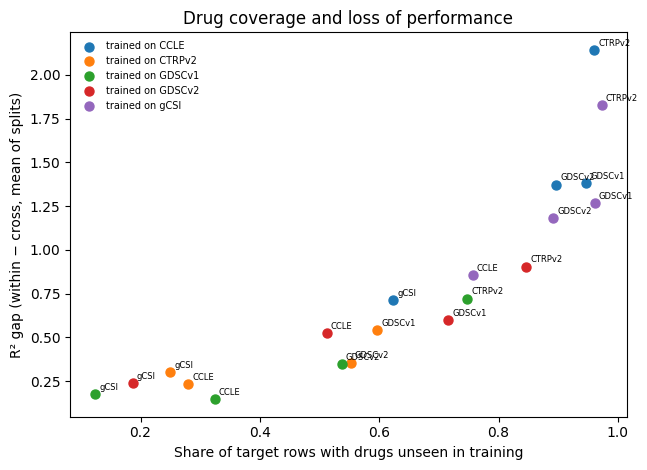

In [5]:
import os
if "resp" not in globals():
    exec(open(os.path.join(os.environ.get("DRP_WORK", "/kaggle/working"), "drp_setup.py")).read())
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, wasserstein_distance

DIAG_DIR = OUT_DIR / "diagnostics"; DIAG_DIR.mkdir(exist_ok=True)
MIN_N, MIN_RELIABLE = 30, 500

# ---------- A. Dataset-level coverage (share of the target present in the source) ----------
def coverage(codes):
    sets = {n: set(np.unique(codes[src_all == n])) for n in names}
    m = pd.DataFrame(index=names, columns=names, dtype=float)
    for s in names:
        for t in names:
            m.loc[s, t] = len(sets[t] & sets[s]) / len(sets[t])
    m.index.name, m.columns.name = "source (train)", "target (test)"
    return m
for nm, codes in [("drug", chem_codes), ("cell", cell_codes), ("pair", pair_codes)]:
    cov = coverage(codes); cov.to_csv(DIAG_DIR / f"coverage_{nm}.csv")
    print(f"\nShare of target {nm}s also present in the source dataset"); display(cov.round(3))

# ---------- B. Seen vs unseen stratification, every split ----------
def stratify(source, k):
    P = load_pred(source, k)
    tr = split_ids(source, k, "train")
    sd, sc_, sp = np.unique(chem_codes[tr]), np.unique(cell_codes[tr]), np.unique(pair_codes[tr])
    out = []
    for t, d in P.groupby("target", sort=False):
        rid = d["row_id"].to_numpy(); y = d["auc"].to_numpy(float); p = d["y_pred"].to_numpy(float)
        ds, cs_, ps = (np.isin(chem_codes[rid], sd), np.isin(cell_codes[rid], sc_), np.isin(pair_codes[rid], sp))
        masks = {"all": np.ones(len(rid), bool), "drug_seen": ds, "drug_unseen": ~ds,
                 "cell_seen": cs_, "cell_unseen": ~cs_, "pair_seen": ps, "pair_unseen": ~ps}
        for nm, m in masks.items():
            n = int(m.sum()); rec = {"source": source, "target": t, "split": k, "stratum": nm, "n": n, "share": n / len(rid)}
            if n >= MIN_N and y[m].std() > 0 and p[m].std() > 0:
                rec.update(score(y[m], p[m]))
            out.append(rec)
    return out

strat = pd.DataFrame([r for k in SPLITS for s in names for r in stratify(s, k)])
strat.to_csv(DIAG_DIR / "stratified_performance_per_split.csv", index=False)

# ---------- C. Counterfactual: restrict the target to what the source has seen ----------
S = pd.concat([pd.read_csv(RES_DIR / f"{s}_split{k}.csv") for s in names for k in SPLITS], ignore_index=True)
home = S[S.source == S.target].set_index(["source", "split"]).r2.rename("r2_within")
idx = ["source", "target", "split"]
def pick(stratum, col, new):
    return strat[strat.stratum == stratum].set_index(idx)[col].rename(new)
cf = pd.concat([pick("all", "r2", "r2_cross"), pick("drug_seen", "r2", "r2_drug_seen"), pick("drug_seen", "n", "n_drug_seen"),
                pick("drug_unseen", "r2", "r2_drug_unseen"), pick("drug_unseen", "share", "share_unseen_drug"),
                pick("cell_seen", "r2", "r2_cell_seen"), pick("cell_unseen", "r2", "r2_cell_unseen"),
                pick("cell_unseen", "share", "share_unseen_cell"), pick("pair_unseen", "share", "share_unseen_pair")],
               axis=1).reset_index()
cf = cf[cf.source != cf.target].join(home, on=["source", "split"])
cf["r2_gap"] = cf.r2_within - cf.r2_cross
cf["share_gap_closed"] = np.where(cf.r2_gap > 0, (cf.r2_drug_seen - cf.r2_cross) / cf.r2_gap, np.nan)
cf["reliable_seen_drug"] = cf.n_drug_seen >= MIN_RELIABLE
cf.to_csv(DIAG_DIR / "counterfactual_per_split.csv", index=False)

mcols = ["r2_cross", "r2_gap", "r2_drug_seen", "r2_drug_unseen", "r2_cell_seen", "r2_cell_unseen",
         "share_gap_closed", "share_unseen_drug", "share_unseen_cell", "share_unseen_pair", "n_drug_seen"]
g = cf.groupby(["source", "target"])
cs = pd.concat([g[mcols].mean().add_suffix("_mean"),
                g[["r2_gap", "r2_drug_seen", "share_gap_closed"]].std().add_suffix("_sd"),
                g.reliable_seen_drug.all().rename("reliable_all_splits")], axis=1).reset_index()
cs = cs.sort_values("r2_gap_mean", ascending=False).reset_index(drop=True)
cs.to_csv(DIAG_DIR / "counterfactual_summary.csv", index=False)
print(f"\nCounterfactual summary (mean over {len(SPLITS)} splits; SD of the gap and of the share closed)")
display(cs[["source", "target", "r2_cross_mean", "r2_gap_mean", "share_unseen_drug_mean", "r2_drug_seen_mean",
            "r2_drug_unseen_mean", "share_gap_closed_mean", "share_gap_closed_sd", "reliable_all_splits"]].round(2))

# ---------- D. Response-side checks (no model involved) ----------
summ = resp.groupby("source").auc.describe(percentiles=[.05, .25, .5, .75, .95]).reindex(names)
summ.to_csv(DIAG_DIR / "response_distribution_summary.csv"); print("\nAUC distribution per dataset"); display(summ.round(3))
vals = {n: auc_all[src_all == n] for n in names}
W_ = pd.DataFrame(0.0, index=names, columns=names)
for i, a in enumerate(names):
    for b in names[i + 1:]:
        W_.loc[a, b] = W_.loc[b, a] = wasserstein_distance(vals[a], vals[b])
W_.to_csv(DIAG_DIR / "response_wasserstein.csv"); print("Wasserstein distance between AUC distributions"); display(W_.round(3))

med = pd.DataFrame({"s": src_all, "p": pair_codes, "auc": auc_all}).groupby(["s", "p"]).auc.median()
wide = {n: med.xs(n, level="s") for n in names}
rows = []
for a in names:
    for b in names:
        if a == b: continue
        j = pd.concat([wide[a].rename("a"), wide[b].rename("b")], axis=1, join="inner")
        rec = {"source": a, "target": b, "n_shared_pairs": len(j)}
        if len(j) >= MIN_N:
            pcc = float(np.corrcoef(j.a, j.b)[0, 1])
            rec.update(pcc_shared=pcc, scc_shared=float(spearmanr(j.a, j.b)[0]), replicate_r2=pcc ** 2,
                       mean_diff_t_minus_s=float((j.b - j.a).mean()), mae_shared=float((j.b - j.a).abs().mean()))
        rows.append(rec)
conc = pd.DataFrame(rows); conc.to_csv(DIAG_DIR / "shared_pair_concordance.csv", index=False)
print("Agreement on drug-cell pairs measured in both datasets (repeats reduced to their median)"); display(conc.round(3))

# ---------- E. Which pair-level measurements track the gap? ----------
tab = cs.merge(conc, on=["source", "target"], how="left")
tab["wasserstein"] = [W_.loc[s, t] for s, t in zip(tab.source, tab.target)]
tab["abs_mean_offset"] = tab.mean_diff_t_minus_s.abs()
rows = []
for c in ["share_unseen_drug_mean", "share_unseen_cell_mean", "share_unseen_pair_mean",
          "pcc_shared", "replicate_r2", "abs_mean_offset", "mae_shared", "wasserstein"]:
    ok = tab[[c, "r2_gap_mean"]].dropna()
    rho, p = spearmanr(ok[c], ok.r2_gap_mean)
    rows.append({"measure": c, "spearman_rho_with_r2_gap": rho, "p_value": p, "n_pairs": len(ok)})
assoc = pd.DataFrame(rows); assoc.to_csv(DIAG_DIR / "association_with_gap.csv", index=False)
print("\nAssociation with the 5-split mean R² gap (descriptive: the 20 pairs are not independent)"); display(assoc.round(3))
per = [spearmanr(d.share_unseen_drug, d.r2_gap)[0] for _, d in cf.groupby("split")]
print("Spearman(share of unseen drugs, R² gap) in each split:", np.round(per, 3))

# ---------- F. Figure: unseen-drug share vs gap ----------
fig, ax = plt.subplots(figsize=(6.6, 4.8))
for s, d in cs.groupby("source"):
    ax.scatter(d.share_unseen_drug_mean, d.r2_gap_mean, s=42, label=f"trained on {s}")
for _, r in cs.iterrows():
    ax.annotate(r.target, (r.share_unseen_drug_mean, r.r2_gap_mean), fontsize=6, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("Share of target rows with drugs unseen in training"); ax.set_ylabel("R² gap (within − cross, mean of splits)")
ax.set_title("Drug coverage and loss of performance"); ax.legend(frameon=False, fontsize=7)
plt.tight_layout()
for ext in ("png", "pdf", "svg"):
    fig.savefig(FIG_DIR / f"unseen_drug_share_vs_gap.{ext}", dpi=300)
plt.show()

## 2. Drug novelty and early warning on 5 splits

**Question.** Does the chemical distance between a target drug and the source model's training drugs predict the model's errors, and
does it work as a warning signal better than the plain "drug unseen: yes/no" flag?

**Definition.** Each drug is represented by its 512-bit ECFP4 fingerprint. Similarity between two drugs is the Tanimoto coefficient
(shared bits / bits present in either). A drug's *nearest-neighbour similarity* is its highest similarity to any drug in the source's
training rows of that split; **novelty = 1 − nearest-neighbour similarity** (0 for drugs in training). Novelty uses no response values.

**Analyses (per pair and split, then averaged over splits).**
1. Spearman correlation between novelty and absolute error among rows with unseen drugs.
2. Mean absolute error (MAE) for four groups: seen drugs, and unseen drugs split into near / mid / far thirds by novelty. The number of
   distinct drugs in each group is reported; groups with few drugs are unreliable.
3. Early-warning ROC-AUC for flagging the 25% largest-error rows, for novelty and for the plain unseen flag (0.5 = chance).

**Limits.** A 512-bit fingerprint is a crude description of a drug; novelty here is chemical distance only. Near / mid / far are relative to
each pair's unseen rows, not absolute distances. Labels are used only to evaluate the warning, not to compute novelty.

**Outputs.** `diagnostics/novelty_*.csv`, `figures/novelty_error_bins.(png|pdf|svg)`.

split 0 done
split 1 done
split 2 done
split 3 done
split 4 done

Per pair, mean over 5 splits (warn_auc: 0.5 = no better than chance)


,source,target,n,share_unseen,mean_novelty_unseen,warn_auc_novelty,warn_auc_unseen_flag,rho_novelty_error_unseen
0,CCLE,CTRPv2,286665.0,0.960,0.761,0.614,0.524,0.200
1,CCLE,GDSCv1,171940.0,0.947,0.742,0.612,0.528,0.167
2,CCLE,GDSCv2,114644.0,0.897,0.739,0.571,0.542,0.100
3,CCLE,gCSI,4941.0,0.623,0.696,0.617,0.628,-0.110
4,CTRPv2,CCLE,9519.0,0.280,0.440,0.544,0.552,-0.140
5,CTRPv2,GDSCv1,171940.0,0.596,0.611,0.531,0.531,0.021
6,CTRPv2,GDSCv2,114644.0,0.552,0.611,0.520,0.533,-0.047
7,CTRPv2,gCSI,4941.0,0.250,0.482,0.518,0.523,-0.104
8,GDSCv1,CCLE,9519.0,0.324,0.586,0.581,0.587,-0.083
9,GDSCv1,CTRPv2,286665.0,0.748,0.673,0.640,0.585,0.149



Mean absolute error by novelty group (mean over splits)


bin             seen   near    mid    far
source target                            
CCLE   CTRPv2  0.079  0.159  0.200  0.211
       GDSCv1  0.094  0.149  0.172  0.193
       GDSCv2  0.098  0.140  0.171  0.168
       gCSI    0.103  0.197  0.122  0.169
CTRPv2 CCLE    0.075  0.107  0.104  0.074
       GDSCv1  0.093  0.109  0.110  0.115
       GDSCv2  0.078  0.094  0.101  0.076
       gCSI    0.100  0.161  0.076  0.115
GDSCv1 CCLE    0.076  0.093  0.122  0.080
       CTRPv2  0.079  0.115  0.117  0.147
       GDSCv2  0.086  0.101  0.090  0.112
       gCSI    0.106  0.089  0.088  0.088
GDSCv2 CCLE    0.088  0.100  0.101  0.161
       CTRPv2  0.077  0.105  0.116  0.149
       GDSCv1  0.093  0.114  0.119  0.128
       gCSI    0.107  0.066  0.121  0.095
gCSI   CCLE    0.099  0.134  0.168  0.131
       CTRPv2  0.104  0.166  0.172  0.185
       GDSCv1  0.129  0.163  0.159  0.171
       GDSCv2  0.123  0.150  0.136  0.165


Number of distinct drugs per group (small = unreliable)


bin             seen   near    mid    far
source target                            
CCLE   CTRPv2   17.0  167.0  160.0  158.0
       GDSCv1   16.0   97.0   94.0   92.0
       GDSCv2   12.0   47.0   56.0   55.0
       gCSI      6.0    4.0    4.0    4.0
CTRPv2 CCLE     17.0    3.0    3.0    3.0
       GDSCv1  113.0   61.0   60.0   62.0
       GDSCv2   72.0   31.0   36.0   32.0
       gCSI     12.0    2.0    2.0    2.0
GDSCv1 CCLE     16.0    3.0    4.0    3.0
       CTRPv2  113.0  123.0  130.0  131.0
       GDSCv2   77.0   29.0   32.0   33.0
       gCSI     14.0    1.0    2.0    1.0
GDSCv2 CCLE     12.0    4.0    5.0    5.0
       CTRPv2   72.0  136.0  142.0  146.0
       GDSCv1   77.0   73.0   71.0   75.0
       gCSI     13.0    1.0    3.0    1.0
gCSI   CCLE      6.0    6.0    7.0    7.0
       CTRPv2   12.0  160.0  172.0  166.0
       GDSCv1   14.0   92.0   96.0   94.0
       GDSCv2   13.0   46.0   57.0   56.0


Early-warning AUC averaged over targets and splits


,warn_auc_novelty,warn_auc_unseen_flag
source,,
CCLE,0.604,0.556
CTRPv2,0.528,0.534
GDSCv1,0.559,0.545
GDSCv2,0.581,0.542
gCSI,0.540,0.533


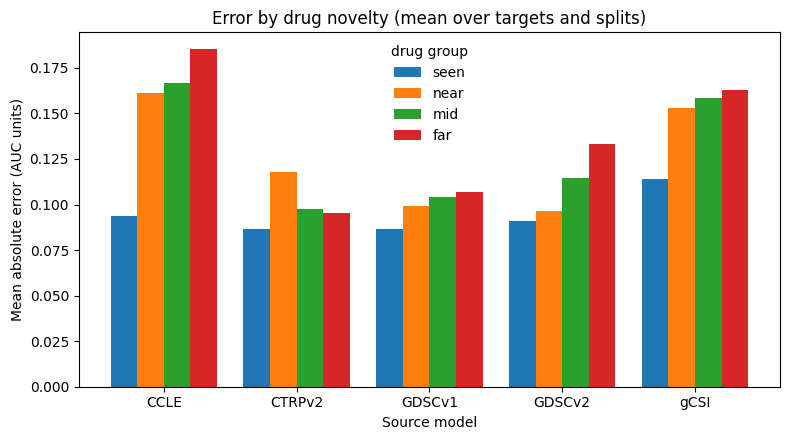

In [6]:
import os
if "resp" not in globals():
    exec(open(os.path.join(os.environ.get("DRP_WORK", "/kaggle/working"), "drp_setup.py")).read())
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

DIAG_DIR = OUT_DIR / "diagnostics"; DIAG_DIR.mkdir(exist_ok=True)
MIN_N = 100
BINS = ["seen", "near", "mid", "far"]

# ---- Tanimoto similarity between all drugs (512-bit ECFP4) ----
fp = pd.read_csv(RAW / "x_data" / "drug_ecfp4_nbits512.tsv", sep="\t", index_col=0)
F = fp.to_numpy(np.float32); bits = F.sum(1); inter = F @ F.T
union = bits[:, None] + bits[None, :] - inter
tani = np.divide(inter, union, out=np.zeros_like(inter), where=union > 0); np.fill_diagonal(tani, 1.0)
fp_pos = {d: i for i, d in enumerate(fp.index)}
chem_to_fp = np.array([fp_pos.get(d, -1) for d in chem_uni])      # drug code -> fingerprint row (-1 = none)

def auc_or_nan(flag, score_):
    return roc_auc_score(flag, score_) if 0 < flag.sum() < len(flag) and np.ptp(score_) > 0 else np.nan

pair_rows, bin_rows = [], []
for k in SPLITS:
    for s in names:
        tr = split_ids(s, k, "train")
        tr_codes = np.unique(chem_codes[tr])
        tr_fp = np.unique(chem_to_fp[tr_codes]); tr_fp = tr_fp[tr_fp >= 0]
        nn_sim = tani[:, tr_fp].max(1)                            # nearest training drug, for every drug
        P = load_pred(s, k)
        for t, d in P.groupby("target", sort=False):
            if t == s: continue
            rid = d["row_id"].to_numpy(); y = d["auc"].to_numpy(float); p = d["y_pred"].to_numpy(float)
            fpi = chem_to_fp[chem_codes[rid]]
            nov = np.where(fpi >= 0, 1 - nn_sim[np.maximum(fpi, 0)], np.nan)
            seen = np.isin(chem_codes[rid], tr_codes)
            err = np.abs(y - p); ok = ~np.isnan(nov); un = (~seen) & ok
            hi = err >= np.quantile(err[ok], 0.75)
            rec = {"source": s, "target": t, "split": k, "n": int(ok.sum()), "share_unseen": float((~seen)[ok].mean()),
                   "mean_novelty_unseen": float(nov[un].mean()) if un.any() else np.nan,
                   "warn_auc_novelty": auc_or_nan(hi[ok], nov[ok]),
                   "warn_auc_unseen_flag": auc_or_nan(hi[ok], (~seen)[ok].astype(float)),
                   "rho_novelty_error_unseen": float(spearmanr(nov[un], err[un])[0]) if un.sum() >= MIN_N and np.ptp(nov[un]) > 0 else np.nan}
            pair_rows.append(rec)
            lab = np.full(len(err), "none", dtype=object); lab[seen & ok] = "seen"
            if un.sum() >= 3:
                r = pd.Series(nov[un]).rank(method="first")
                lab[un] = pd.qcut(r, 3, labels=["near", "mid", "far"]).astype(str)
            for b in BINS:
                m = lab == b
                if m.any():
                    bin_rows.append({"source": s, "target": t, "split": k, "bin": b, "n_rows": int(m.sum()),
                                     "n_drugs": int(np.unique(chem_codes[rid][m]).size),
                                     "mean_novelty": float(nov[m].mean()), "mae": float(err[m].mean())})
        del P; gc.collect()
    print(f"split {k} done")

pm = pd.DataFrame(pair_rows); bn = pd.DataFrame(bin_rows)
pm.to_csv(DIAG_DIR / "novelty_pair_metrics_per_split.csv", index=False)
bn.to_csv(DIAG_DIR / "novelty_bins_per_split.csv", index=False)
pms = pm.groupby(["source", "target"]).mean(numeric_only=True).drop(columns="split").reset_index()
pms.to_csv(DIAG_DIR / "novelty_pair_metrics_summary.csv", index=False)

print(f"\nPer pair, mean over {len(SPLITS)} splits (warn_auc: 0.5 = no better than chance)")
display(pms.round(3))
print("\nMean absolute error by novelty group (mean over splits)")
display(bn.pivot_table(index=["source", "target"], columns="bin", values="mae").reindex(columns=BINS).round(3))
print("\nNumber of distinct drugs per group (small = unreliable)")
display(bn.pivot_table(index=["source", "target"], columns="bin", values="n_drugs").reindex(columns=BINS).round(1))
print("\nEarly-warning AUC averaged over targets and splits")
display(pm.groupby("source")[["warn_auc_novelty", "warn_auc_unseen_flag"]].mean().round(3))

mm = bn.groupby(["source", "bin"]).mae.mean().unstack().reindex(columns=BINS)
fig, ax = plt.subplots(figsize=(8, 4.5)); w = 0.2
for j, b in enumerate(BINS):
    ax.bar(np.arange(len(mm)) + (j - 1.5) * w, mm[b], w, label=b)
ax.set_xticks(range(len(mm))); ax.set_xticklabels(mm.index)
ax.set_ylabel("Mean absolute error (AUC units)"); ax.set_xlabel("Source model")
ax.set_title("Error by drug novelty (mean over targets and splits)"); ax.legend(frameon=False, title="drug group")
plt.tight_layout()
for ext in ("png", "pdf", "svg"):
    fig.savefig(FIG_DIR / f"novelty_error_bins.{ext}", dpi=300)
plt.show()

run at last 


In [7]:
make_backup()      # then download results_backup_v2.zip from the Output panel

Backup written: /kaggle/working/results_backup_v2.zip (136.8 MB). Download it from the Output panel.


## 3. Prediction uncertainty: disagreement between the models trained on different splits

**Question.** Can the disagreement between the five models that were trained on different random splits of the same source dataset flag
the target rows on which the model is wrong, without using the target's response values?

**Method.** For every source dataset and every target dataset (target ≠ source), each target row is predicted by the source's five split models.
Per row: the *ensemble prediction* is the mean of the five predictions, and the *uncertainty* is their standard deviation.
The error is |true AUC − ensemble prediction|. Target rows are identical across splits, so predictions are aligned by row.

**Measures per pair.**
- Spearman correlation between uncertainty and error.
- Early-warning ROC-AUC: how well uncertainty flags the 25% of rows with the largest error (0.5 = chance).
- Mean error in the lowest and highest uncertainty fifths of rows.
- R² of a single split model (mean over splits) and of the ensemble mean.

**Uses target labels:** only to measure the error, not to compute the uncertainty.

**Limits.** Disagreement across training splits is a weak form of uncertainty: all five models share the same training data distribution and
tend to make the same mistakes on drugs they have never seen. High agreement does not mean high correctness. The warning AUC here is computed on
the ensemble error and is not exactly comparable with the novelty warning AUC (Section 2), which uses single-split errors.

**Outputs.** `diagnostics/uncertainty_pair_metrics.csv`, `figures/uncertainty_error_quintiles.(png|pdf|svg)`.

finished source CTRPv2
finished source GDSCv1
finished source GDSCv2
finished source CCLE
finished source gCSI

Uncertainty versus error, per pair (warn_auc: 0.5 = no better than chance)


,source,target,mean_uncertainty,rho_uncertainty_error,warn_auc_uncertainty,err_q1,err_q5,err_ratio_q5_q1,r2_single_mean,r2_ensemble
0,CTRPv2,GDSCv1,0.014,0.221,0.620,0.077,0.132,1.711,0.260,0.268
1,CTRPv2,GDSCv2,0.014,0.243,0.646,0.060,0.115,1.923,0.446,0.457
2,CTRPv2,CCLE,0.012,0.177,0.611,0.064,0.108,1.676,0.570,0.577
3,CTRPv2,gCSI,0.015,0.151,0.612,0.086,0.129,1.505,0.500,0.508
4,GDSCv1,CTRPv2,0.018,0.275,0.657,0.078,0.147,1.892,-0.018,-0.001
5,GDSCv1,GDSCv2,0.017,0.262,0.649,0.065,0.125,1.912,0.355,0.369
6,GDSCv1,CCLE,0.017,0.216,0.648,0.067,0.113,1.689,0.557,0.569
7,GDSCv1,gCSI,0.021,0.078,0.525,0.092,0.112,1.217,0.526,0.542
8,GDSCv2,CTRPv2,0.016,0.325,0.707,0.078,0.174,2.238,-0.139,-0.124
9,GDSCv2,GDSCv1,0.015,0.226,0.635,0.087,0.146,1.675,0.168,0.177



Averaged over targets


,rho_uncertainty_error,warn_auc_uncertainty,err_ratio_q5_q1
source,,,
CCLE,0.129,0.568,1.292
CTRPv2,0.198,0.622,1.704
GDSCv1,0.208,0.620,1.678
GDSCv2,0.237,0.656,1.824
gCSI,0.191,0.624,1.494


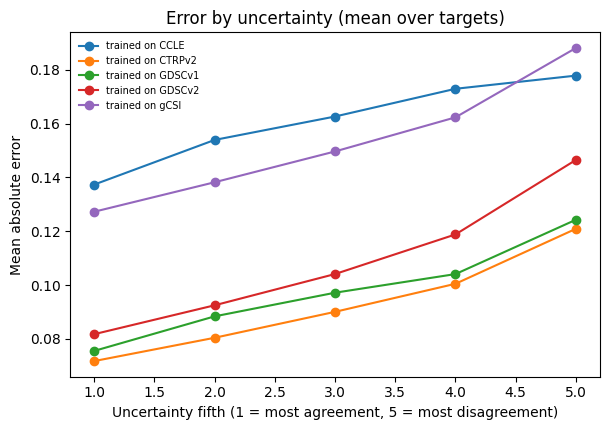

In [8]:
import os
if "resp" not in globals():
    exec(open(os.path.join(os.environ.get("DRP_WORK", "/kaggle/working"), "drp_setup.py")).read())
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

assert len(SPLITS) >= 3, "At least 3 complete splits are needed for an uncertainty estimate."
DIAG_DIR = OUT_DIR / "diagnostics"; DIAG_DIR.mkdir(exist_ok=True)

rows = []
for s in names:
    frames = []
    for k in SPLITS:
        P = load_pred(s, k); P = P[P.target != s].copy(); P["split"] = k; frames.append(P)
    D = pd.concat(frames, ignore_index=True); del frames
    for t, d in D.groupby("target", sort=False):
        piv = d.pivot(index="row_id", columns="split", values="y_pred").dropna()
        y = auc_all[piv.index.to_numpy()]
        M = piv.to_numpy(float)
        mean, sd = M.mean(1), M.std(1, ddof=1)
        err = np.abs(y - mean)
        hi = err >= np.quantile(err, 0.75)
        q = pd.qcut(pd.Series(sd).rank(method="first"), 5, labels=False).to_numpy()
        rec = {"source": s, "target": t, "n_rows": len(y), "n_splits": M.shape[1],
               "mean_uncertainty": float(sd.mean()),
               "rho_uncertainty_error": float(spearmanr(sd, err)[0]),
               "warn_auc_uncertainty": float(roc_auc_score(hi, sd)),
               "r2_single_mean": float(np.mean([score(y, M[:, i])["r2"] for i in range(M.shape[1])])),
               "r2_ensemble": score(y, mean)["r2"]}
        for j in range(5):
            rec[f"err_q{j + 1}"] = float(err[q == j].mean())
        rec["err_ratio_q5_q1"] = rec["err_q5"] / rec["err_q1"]
        rows.append(rec)
    del D; gc.collect()
    print(f"finished source {s}")

un = pd.DataFrame(rows)
un.to_csv(DIAG_DIR / "uncertainty_pair_metrics.csv", index=False)
print("\nUncertainty versus error, per pair (warn_auc: 0.5 = no better than chance)")
display(un[["source", "target", "mean_uncertainty", "rho_uncertainty_error", "warn_auc_uncertainty",
            "err_q1", "err_q5", "err_ratio_q5_q1", "r2_single_mean", "r2_ensemble"]].round(3))
print("\nAveraged over targets")
display(un.groupby("source")[["rho_uncertainty_error", "warn_auc_uncertainty", "err_ratio_q5_q1"]].mean().round(3))

qm = un.groupby("source")[[f"err_q{j}" for j in range(1, 6)]].mean()
fig, ax = plt.subplots(figsize=(6.2, 4.4))
for s, r in qm.iterrows():
    ax.plot(range(1, 6), r.to_numpy(), marker="o", label=f"trained on {s}")
ax.set_xlabel("Uncertainty fifth (1 = most agreement, 5 = most disagreement)"); ax.set_ylabel("Mean absolute error")
ax.set_title("Error by uncertainty (mean over targets)"); ax.legend(frameon=False, fontsize=7)
plt.tight_layout()
for ext in ("png", "pdf", "svg"):
    fig.savefig(FIG_DIR / f"uncertainty_error_quintiles.{ext}", dpi=300)
plt.show()

## 4. Evidence table: all 5-split measurements for each source → target pair

**Purpose.** Merge every measurement into one table with one row per cross-dataset pair. It is the only input of the rule engine and
validation (Sections 5 and 6), so explanations are built from numbers and nothing else.

**Contents.**
- *Failure:* mean R² within-dataset and cross-dataset, R² gap (mean and SD over splits).
- *Coverage and counterfactual (Section 1):* shares of target rows with unseen drugs, cell lines and pairs; R² on seen and unseen subsets;
  share of the gap closed by restricting to seen drugs (mean and SD over splits); reliability flag (≥ 500 seen-drug rows in every split).
- *Response side (Section 1):* number of shared drug-cell pairs, their Pearson correlation, `replicate_r2` (a benchmark, not an upper bound),
  mean offset, mean absolute difference, Wasserstein distance between AUC distributions.
- *Novelty (Section 2) and uncertainty (Section 3):* correlations and early-warning AUCs.
- *Source size:* mean number of distinct training drugs of the source model.

**Not included.** SHAP and domain-classifier results were produced on split 0 only and are reported separately as exploratory.

**Outputs.** `evidence/evidence_per_pair.csv` and `evidence/evidence_per_pair.json` (with a list of limitations).

In [9]:
import os, json
if "resp" not in globals():
    exec(open(os.path.join(os.environ.get("DRP_WORK", "/kaggle/working"), "drp_setup.py")).read())
import numpy as np, pandas as pd

DIAG_DIR = OUT_DIR / "diagnostics"; EV_DIR = OUT_DIR / "evidence"; EV_DIR.mkdir(exist_ok=True)
need = ["counterfactual_summary.csv", "shared_pair_concordance.csv", "response_wasserstein.csv",
        "novelty_pair_metrics_summary.csv", "uncertainty_pair_metrics.csv"]
missing = [f for f in need if not (DIAG_DIR / f).exists()]
assert not missing, f"Run the earlier sections first; missing: {missing}"

cs   = pd.read_csv(DIAG_DIR / "counterfactual_summary.csv")
conc = pd.read_csv(DIAG_DIR / "shared_pair_concordance.csv")
W_   = pd.read_csv(DIAG_DIR / "response_wasserstein.csv", index_col=0)
nov  = pd.read_csv(DIAG_DIR / "novelty_pair_metrics_summary.csv")[
        ["source", "target", "mean_novelty_unseen", "rho_novelty_error_unseen", "warn_auc_novelty", "warn_auc_unseen_flag"]]
unc  = pd.read_csv(DIAG_DIR / "uncertainty_pair_metrics.csv")[
        ["source", "target", "mean_uncertainty", "rho_uncertainty_error", "warn_auc_uncertainty", "err_ratio_q5_q1", "r2_ensemble"]]

ev = cs.merge(conc, on=["source", "target"], how="left").merge(nov, on=["source", "target"], how="left") \
       .merge(unc, on=["source", "target"], how="left")
ev["r2_within_mean"] = ev.r2_cross_mean + ev.r2_gap_mean              # exact: gap = within - cross in every split
ev["worse_than_mean"] = ev.r2_cross_mean < 0
ev["wasserstein_auc"] = [W_.loc[s, t] for s, t in zip(ev.source, ev.target)]
ntr = {s: float(np.mean([np.unique(chem_codes[split_ids(s, k, "train")]).size for k in SPLITS])) for s in names}
ev["source_n_train_drugs"] = ev.source.map(ntr)
ev["n_splits"] = len(SPLITS)
ev = ev.sort_values("r2_gap_mean", ascending=False).reset_index(drop=True)
ev.to_csv(EV_DIR / "evidence_per_pair.csv", index=False)

limitations = [
    f"Results are the mean over {len(SPLITS)} of the benchmark's 10 splits; the 10-split protocol was not run.",
    "One model family (XGBoost on GPU) with untuned placeholder hyperparameters; the CTRPv2 model reached the tree cap (2000) in every split.",
    "The 20 source-target pairs are not independent: each dataset appears as source and as target several times.",
    "Seen and unseen subsets contain different drugs, so differences between them may partly reflect drug difficulty.",
    "R2 on seen-drug subsets is not computed on the same rows as the overall R2.",
    "replicate_r2 (squared correlation of two datasets on shared drug-cell pairs) is a benchmark, not an upper bound on model performance.",
    "Uncertainty is the disagreement between models trained on different splits of the same data and is a weak warning signal.",
    "Drug novelty is a 512-bit ECFP4 chemical distance only and does not capture mechanism of action.",
    "SHAP and domain-classifier analyses were run on split 0 only and are not part of this table.",
    "Assay protocols were not examined directly, only the resulting AUC values."]
with open(EV_DIR / "evidence_per_pair.json", "w") as f:
    json.dump({"limitations": limitations, "pairs": json.loads(ev.round(4).to_json(orient="records"))}, f, indent=2)

pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
display(ev[["source", "target", "r2_within_mean", "r2_cross_mean", "r2_gap_mean", "share_unseen_drug_mean", "r2_drug_seen_mean",
            "share_gap_closed_mean", "reliable_all_splits", "replicate_r2", "warn_auc_uncertainty", "warn_auc_novelty"]].round(2))
print(f"{len(ev)} pairs saved to {EV_DIR}")

,source,target,r2_within_mean,r2_cross_mean,r2_gap_mean,share_unseen_drug_mean,r2_drug_seen_mean,share_gap_closed_mean,reliable_all_splits,replicate_r2,warn_auc_uncertainty,warn_auc_novelty
0,CCLE,CTRPv2,0.81,-1.33,2.14,0.96,0.61,0.91,True,0.68,0.57,0.61
1,gCSI,CTRPv2,0.78,-1.04,1.83,0.97,0.53,0.86,True,0.55,0.61,0.53
2,CCLE,GDSCv1,0.81,-0.57,1.38,0.95,0.47,0.75,True,0.61,0.58,0.61
3,CCLE,GDSCv2,0.81,-0.56,1.37,0.90,0.14,0.51,True,0.50,0.59,0.57
4,gCSI,GDSCv1,0.78,-0.48,1.27,0.96,0.42,0.72,True,0.47,0.61,0.53
5,gCSI,GDSCv2,0.78,-0.40,1.18,0.89,0.39,0.67,True,0.50,0.63,0.55
6,GDSCv2,CTRPv2,0.77,-0.14,0.90,0.85,0.62,0.83,True,0.63,0.71,0.64
7,gCSI,CCLE,0.78,-0.07,0.86,0.76,0.60,0.79,True,0.61,0.65,0.55
8,GDSCv1,CTRPv2,0.70,-0.02,0.72,0.75,0.51,0.73,True,0.48,0.66,0.64
9,CCLE,gCSI,0.81,0.09,0.71,0.62,0.42,0.45,True,0.61,0.53,0.62


20 pairs saved to /kaggle/working/outputs/evidence


In [10]:
make_backup()

Backup written: /kaggle/working/results_backup_v2.zip (137.0 MB). Download it from the Output panel.


## 5. Rule engine: evidence-linked explanation for each source → target pair

**Purpose.** Turn the evidence table into a structured, checkable diagnosis for each of the 20 cross-dataset pairs. A deterministic rule
engine reads only `evidence_per_pair.csv`, applies fixed, documented thresholds, and writes (i) claims with a status, (ii) the evidence fields
each claim rests on, and (iii) a plain-language narrative in which every number is inserted from the evidence table. No language model is
involved, so the output is reproducible and cannot contain invented numbers.

**Claims per pair.**
1. *Drug coverage:* share of the R² gap closed by restricting the target to drugs seen in training (strong ≥ 0.60, partial ≥ 0.30). Not assessed
   when the gap is below 0.25 (the ratio is unstable) or when fewer than 500 seen-drug rows exist.
2. *Cell-line coverage:* supported if at least 20% of target rows have unseen cell lines and seen-minus-unseen R² is at least 0.30.
3. *Lab agreement:* whether R² on seen drugs is within 0.10 of the replicate benchmark (squared correlation between the two datasets on shared
   pairs; a benchmark, not an upper bound), and whether a systematic offset of at least 0.05 AUC exists.
4. *Source size:* flagged as a possible (untested) contributor when the source has fewer than 50 training drugs and seen-drug R² falls clearly below the benchmark.
5. *Early warning:* whether disagreement between split models flags the largest-error quarter of rows (ROC-AUC ≥ 0.65 moderate, ≥ 0.55 weak).

**Thresholds are the authors' choices**, listed in `RULES`; their influence is tested in Section 6 (sensitivity analysis).

**Outputs.** `agent/diagnosis_claims.json`, `agent/diagnosis_report.md`, `agent/diagnosis_status_table.csv`.

**Limits.** The rules encode which explanations were *measured*; they do not establish causation. SHAP and domain-classifier results are not used.

In [13]:
import os, json, re
from pathlib import Path
import numpy as np, pandas as pd
WORK_DIR = Path(os.environ.get("DRP_WORK", "/kaggle/working")); OUT_DIR = WORK_DIR / "outputs"
EV_DIR = OUT_DIR / "evidence"; AG_DIR = OUT_DIR / "agent"; AG_DIR.mkdir(parents=True, exist_ok=True)
try:
    display
except NameError:
    def display(x): print(x)

RULES = {"closed_strong": 0.60, "closed_moderate": 0.30, "min_gap_for_ratio": 0.25,
         "seen_unseen_diff": 0.30, "min_unseen_cell_share": 0.20,
         "replicate_tolerance": 0.10, "offset_flag": 0.05,
         "small_source_drugs": 50, "warn_moderate": 0.65, "warn_weak": 0.55}

ev = pd.read_csv(EV_DIR / "evidence_per_pair.csv")
need = ["source", "target", "r2_within_mean", "r2_cross_mean", "r2_gap_mean", "r2_gap_sd", "share_unseen_drug_mean",
        "r2_drug_seen_mean", "r2_drug_unseen_mean", "share_gap_closed_mean", "share_gap_closed_sd", "reliable_all_splits",
        "share_unseen_cell_mean", "r2_cell_seen_mean", "r2_cell_unseen_mean", "n_shared_pairs", "replicate_r2",
        "mean_diff_t_minus_s", "source_n_train_drugs", "warn_auc_uncertainty", "warn_auc_novelty", "err_ratio_q5_q1", "n_splits"]
assert not [c for c in need if c not in ev.columns], f"Missing columns: {[c for c in need if c not in ev.columns]}"

class Fmt:
    """Formats numbers from one evidence row and records every number shown, so each one can be traced to its field."""
    def __init__(self, row): self.row, self.used = row, []
    def v(self, field, kind="f2"):
        x = getattr(self.row, field)
        if pd.isna(x): s = "n/a"
        elif kind == "f2": s = f"{x:.2f}"
        elif kind == "f1": s = f"{x:.1f}"
        elif kind == "pct": s = f"{100 * x:.0f}%"
        elif kind == "int": s = f"{int(round(x)):,}"
        else: raise ValueError(kind)
        self.used.append({"field": field, "kind": kind, "shown": s})
        return s

def claim_drug(r, F):
    if not bool(r.reliable_all_splits): st = "insufficient data"
    elif r.r2_gap_mean < RULES["min_gap_for_ratio"]: st = "not assessed (gap too small)"
    elif r.share_gap_closed_mean >= RULES["closed_strong"]: st = "supported (strong)"
    elif r.share_gap_closed_mean >= RULES["closed_moderate"]: st = "supported (partial)"
    else: st = "not supported"
    if st.startswith("supported"):
        t = (f"{F.v('share_unseen_drug_mean','pct')} of {r.target} rows have drugs that {r.source} never saw in training. On rows with seen drugs R² is "
             f"{F.v('r2_drug_seen_mean')}, against {F.v('r2_drug_unseen_mean')} on unseen drugs; restricting the target to seen drugs closes "
             f"{F.v('share_gap_closed_mean','pct')} of the R² gap (SD {F.v('share_gap_closed_sd')} across {F.v('n_splits','int')} splits).")
    elif st == "not supported":
        t = (f"Only {F.v('share_unseen_drug_mean','pct')} of {r.target} rows have unseen drugs, and restricting to seen drugs closes "
             f"{F.v('share_gap_closed_mean','pct')} of the R² gap.")
    elif st.startswith("not assessed"):
        t = (f"The R² gap ({F.v('r2_gap_mean')}) is too small for the share closed by restricting to seen drugs to be meaningful "
             f"(R² on seen drugs {F.v('r2_drug_seen_mean')}).")
    else:
        t = "Too few seen-drug rows in at least one split to evaluate this explanation."
    return "drug_coverage", "Drug coverage", st, t

def claim_cell(r, F):
    seen, unseen = r.r2_cell_seen_mean, r.r2_cell_unseen_mean
    if pd.isna(seen) or pd.isna(unseen): st = "insufficient data"
    elif r.share_unseen_cell_mean >= RULES["min_unseen_cell_share"] and (seen - unseen) >= RULES["seen_unseen_diff"]: st = "supported"
    else: st = "not supported"
    t = (f"{F.v('share_unseen_cell_mean','pct')} of {r.target} rows have cell lines unseen by {r.source}; R² is {F.v('r2_cell_seen_mean')} on seen "
         f"and {F.v('r2_cell_unseen_mean')} on unseen cell lines. Cell-line coverage is entangled with the size of the source dataset.")
    return "cell_coverage", "Cell-line coverage", st, t

def claim_lab(r, F):
    short = r.replicate_r2 - r.r2_drug_seen_mean
    if pd.isna(short): st = "insufficient data"
    elif short <= RULES["replicate_tolerance"]: st = "comparable to replicate benchmark"
    else: st = "below replicate benchmark"
    off = "a systematic offset between the two datasets was detected" if abs(r.mean_diff_t_minus_s) >= RULES["offset_flag"] \
          else "no systematic offset between the two datasets was detected"
    t = (f"On seen drugs {r.source} reaches R² {F.v('r2_drug_seen_mean')} on {r.target}, within its own data {F.v('r2_within_mean')}. "
         f"Two labs' measurements of the same drug-cell pairs agree with a squared correlation of {F.v('replicate_r2')} over "
         f"{F.v('n_shared_pairs','int')} shared pairs (a benchmark, not an upper bound); {off} (mean difference {F.v('mean_diff_t_minus_s')}).")
    return "lab_agreement", "Lab-to-lab agreement", st, t

def claim_source(r, F):
    small = r.source_n_train_drugs < RULES["small_source_drugs"]
    short = r.replicate_r2 - r.r2_drug_seen_mean
    if not small: st = "not applicable"
    elif pd.notna(short) and short > RULES["replicate_tolerance"]: st = "possible contributor (untested)"
    else: st = "small source, no shortfall seen"
    t = (f"{r.source} was trained on about {F.v('source_n_train_drugs','int')} distinct drugs." +
         (f" Its seen-drug R² on {r.target} ({F.v('r2_drug_seen_mean')}) is below the replicate benchmark ({F.v('replicate_r2')}); "
          "whether training-set size contributes was not tested." if st.startswith("possible") else ""))
    return "source_size", "Source dataset size", st, t

def claim_warning(r, F):
    a = r.warn_auc_uncertainty
    st = "moderately informative" if a >= RULES["warn_moderate"] else "weakly informative" if a >= RULES["warn_weak"] else "not informative"
    t = (f"Disagreement between the {F.v('n_splits','int')} split models flags the largest-error quarter of target rows with ROC-AUC "
         f"{F.v('warn_auc_uncertainty')} (chance level is one half); drug novelty gives {F.v('warn_auc_novelty')}. Error in the most uncertain fifth "
         f"of rows is {F.v('err_ratio_q5_q1','f1')} times that in the least uncertain fifth.")
    return "early_warning", "Early warning", st, t

CLAIMS = [claim_drug, claim_cell, claim_lab, claim_source, claim_warning]
LIMITS = ["Assay protocols were not examined directly, only the resulting AUC values.",
          "Seen and unseen subsets contain different drugs, so part of the difference may reflect drug difficulty.",
          "The measurements are associations on benchmark data and do not establish causation."]

def diagnose(r):
    claims, shown = [], []
    for fn in CLAIMS:
        F = Fmt(r); cid, label, st, text = fn(r, F)
        claims.append({"id": cid, "label": label, "status": st, "text": text, "numbers_used": F.used}); shown += F.used
    drug = next(c for c in claims if c["id"] == "drug_coverage")["status"]
    primary = ("drug_coverage_strong" if drug == "supported (strong)" else "drug_coverage_partial" if drug == "supported (partial)"
               else "small_gap" if r.r2_gap_mean < RULES["min_gap_for_ratio"] else "unexplained")
    F = Fmt(r)
    cls = ("fails (worse than predicting the target mean)" if r.r2_cross_mean < 0
           else "large loss" if r.r2_gap_mean >= 0.5 else "moderate loss" if r.r2_gap_mean >= 0.25 else "small loss")
    head = (f"{r.source} → {r.target}: R² {F.v('r2_cross_mean')} on {r.target}, against {F.v('r2_within_mean')} within {r.source}'s own data "
            f"(gap {F.v('r2_gap_mean')}); {cls}.")
    summ = {"drug_coverage_strong": "Unseen target drugs are the best-supported explanation.",
            "drug_coverage_partial": "Unseen target drugs account for part of the loss; the rest is not explained by the measured factors.",
            "small_gap": "The loss is small and no dominant cause was identified.",
            "unexplained": "None of the measured factors explains this loss."}[primary]
    shown = F.used + shown
    narrative = head + " " + summ + "\n\n" + "\n".join(f"- {c['label']} [{c['status']}]: {c['text']}" for c in claims) \
                + "\n\nNot examined or limited: " + " ".join(LIMITS)
    return {"pair": f"{r.source} -> {r.target}", "source": r.source, "target": r.target, "classification": cls,
            "primary_explanation": primary, "claims": claims, "headline_numbers": F.used, "narrative": narrative}

results = [diagnose(r) for r in ev.itertuples(index=False)]
with open(AG_DIR / "diagnosis_claims.json", "w") as f:
    json.dump({"rules": RULES, "limitations": LIMITS, "pairs": results}, f, indent=2)
with open(AG_DIR / "diagnosis_report.md", "w") as f:
    f.write("# Diagnosis of cross-dataset performance loss\n\nGenerated by a deterministic rule engine from `evidence_per_pair.csv`.\n\n")
    f.write("Rules: " + json.dumps(RULES) + "\n\n")
    for d in results:
        f.write(f"## {d['pair']}\n\n{d['narrative']}\n\n")
tab = pd.DataFrame([{"pair": d["pair"], "classification": d["classification"], "primary": d["primary_explanation"],
                     **{c["id"]: c["status"] for c in d["claims"]}} for d in results])
tab.to_csv(AG_DIR / "diagnosis_status_table.csv", index=False)

display(tab)
print("\nPrimary explanation counts:"); display(tab.primary.value_counts())
print("\nExample narratives (the worst pair and a small-gap pair):\n")
print(results[0]["narrative"]); print("\n" + "-" * 80 + "\n"); print(next(d for d in results if d["primary_explanation"] == "small_gap")["narrative"])

,pair,classification,primary,drug_coverage,cell_coverage,lab_agreement,source_size,early_warning
0,CCLE -> CTRPv2,fails (worse than predicting the target mean),drug_coverage_strong,supported (strong),not supported,comparable to replicate benchmark,"small source, no shortfall seen",weakly informative
1,gCSI -> CTRPv2,fails (worse than predicting the target mean),drug_coverage_strong,supported (strong),not supported,comparable to replicate benchmark,"small source, no shortfall seen",weakly informative
2,CCLE -> GDSCv1,fails (worse than predicting the target mean),drug_coverage_strong,supported (strong),not supported,below replicate benchmark,possible contributor (untested),weakly informative
3,CCLE -> GDSCv2,fails (worse than predicting the target mean),drug_coverage_partial,supported (partial),not supported,below replicate benchmark,possible contributor (untested),weakly informative
4,gCSI -> GDSCv1,fails (worse than predicting the target mean),drug_coverage_strong,supported (strong),not supported,comparable to replicate benchmark,"small source, no shortfall seen",weakly informative
5,gCSI -> GDSCv2,fails (worse than predicting the target mean),drug_coverage_strong,supported (strong),not supported,below replicate benchmark,possible contributor (untested),weakly informative
6,GDSCv2 -> CTRPv2,fails (worse than predicting the target mean),drug_coverage_strong,supported (strong),not supported,comparable to replicate benchmark,not applicable,moderately informative
7,gCSI -> CCLE,fails (worse than predicting the target mean),drug_coverage_strong,supported (strong),not supported,comparable to replicate benchmark,"small source, no shortfall seen",weakly informative
8,GDSCv1 -> CTRPv2,fails (worse than predicting the target mean),drug_coverage_strong,supported (strong),not supported,comparable to replicate benchmark,not applicable,moderately informative
9,CCLE -> gCSI,large loss,drug_coverage_partial,supported (partial),not supported,below replicate benchmark,possible contributor (untested),not informative



Primary explanation counts:


primary
drug_coverage_strong     8
drug_coverage_partial    7
small_gap                4
unexplained              1
Name: count, dtype: int64


Example narratives (the worst pair and a small-gap pair):

CCLE → CTRPv2: R² -1.33 on CTRPv2, against 0.81 within CCLE's own data (gap 2.14); fails (worse than predicting the target mean). Unseen target drugs are the best-supported explanation.

- Drug coverage [supported (strong)]: 96% of CTRPv2 rows have drugs that CCLE never saw in training. On rows with seen drugs R² is 0.61, against -1.47 on unseen drugs; restricting the target to seen drugs closes 91% of the R² gap (SD 0.01 across 5 splits).
- Cell-line coverage [not supported]: 46% of CTRPv2 rows have cell lines unseen by CCLE; R² is -1.46 on seen and -1.20 on unseen cell lines. Cell-line coverage is entangled with the size of the source dataset.
- Lab-to-lab agreement [comparable to replicate benchmark]: On seen drugs CCLE reaches R² 0.61 on CTRPv2, within its own data 0.81. Two labs' measurements of the same drug-cell pairs agree with a squared correlation of 0.68 over 5,943 shared pairs (a benchmark, not an upper bound); no 

## 6. Validation of the diagnosis

**Purpose.** Check that the rule engine's explanations are correct, traceable and not an artefact of the chosen thresholds.

**Checks.**
1. **Number traceability.** Every number shown in a narrative is recomputed from `evidence_per_pair.csv` and must match; and no number may appear in
   a narrative that was not inserted from an evidence field (dataset names such as "GDSCv1" are excluded when scanning).
2. **Independent re-implementation.** The status of the drug-coverage, lab-agreement and early-warning claims is recomputed with a separately written
   vectorised implementation of the same rules and must match the engine for all 20 pairs.
3. **Reproducibility across splits.** For each pair and each split, the drug-coverage class is derived from the mean of the *other* splits and compared
   with the class from the held-out split (the splits share one dataset, so this shows stability, not independent confirmation).
4. **Threshold sensitivity.** All thresholds are changed by ±20%; the share of pairs whose primary explanation changes is reported.
5. **Label-free early warning (leave-one-source-out).** Can the share of unseen drugs, which needs no target labels, predict whether a pair fails
   (R² < 0)? For each source, a threshold is chosen on the other sources' pairs and applied to the held-out source's pairs. Reported: accuracy,
   accuracy of always predicting the majority class, and the ROC-AUC of the raw share.

**Interpretation.** The first two checks test the software, the third and fourth test the stability of the rules, the fifth tests whether the main
explanation has predictive value. Only 20 non-independent pairs from 5 source datasets are available, so check 5 is indicative only.

**Outputs.** `agent/validation_summary.json`, `agent/validation_checks.csv`.

In [14]:
import os, json, re
from pathlib import Path
import numpy as np, pandas as pd
from sklearn.metrics import roc_auc_score
WORK_DIR = Path(os.environ.get("DRP_WORK", "/kaggle/working")); OUT_DIR = WORK_DIR / "outputs"
EV_DIR = OUT_DIR / "evidence"; AG_DIR = OUT_DIR / "agent"; DIAG_DIR = OUT_DIR / "diagnostics"
try:
    display
except NameError:
    def display(x): print(x)

ev = pd.read_csv(EV_DIR / "evidence_per_pair.csv")
J = json.load(open(AG_DIR / "diagnosis_claims.json")); R = J["rules"]; pairs = J["pairs"]
key = lambda s, t: (s, t)
evi = ev.set_index(["source", "target"])
checks = []

# ---- 1. Number traceability ----
fmt = {"f2": lambda x: f"{x:.2f}", "f1": lambda x: f"{x:.1f}", "pct": lambda x: f"{100 * x:.0f}%", "int": lambda x: f"{int(round(x)):,}"}
mismatch, missing_in_text, stray = 0, 0, 0
names_re = re.compile(r"(CTRPv2|GDSCv1|GDSCv2|CCLE|gCSI)")
for d in pairs:
    row = evi.loc[key(d["source"], d["target"])]
    nums = d["headline_numbers"] + [n for c in d["claims"] for n in c["numbers_used"]]
    for n in nums:
        x = row[n["field"]]
        want = "n/a" if pd.isna(x) else fmt[n["kind"]](x)
        mismatch += want != n["shown"]
        missing_in_text += n["shown"] not in d["narrative"]
    text = names_re.sub(" ", d["narrative"])
    text = re.sub(r"[A-Z]+\w*²|R²", " ", text)
    tokens = re.findall(r"-?\d[\d,]*\.?\d*%?", text)
    shown = [n["shown"] for n in nums]
    for tk in tokens:
        stray += tk not in shown
checks += [{"check": "numbers recomputed from the evidence table match", "failures": int(mismatch), "of": sum(len(d["headline_numbers"]) + sum(len(c["numbers_used"]) for c in d["claims"]) for d in pairs)},
           {"check": "numbers inserted but missing from the narrative", "failures": int(missing_in_text), "of": len(pairs)},
           {"check": "numbers in narratives not traceable to an evidence field", "failures": int(stray), "of": len(pairs)}]

# ---- 2. Independent vectorised re-implementation ----
e = ev.copy()
drug = np.select([~e.reliable_all_splits.astype(bool), e.r2_gap_mean < R["min_gap_for_ratio"], e.share_gap_closed_mean >= R["closed_strong"],
                  e.share_gap_closed_mean >= R["closed_moderate"]],
                 ["insufficient data", "not assessed (gap too small)", "supported (strong)", "supported (partial)"], "not supported")
short = e.replicate_r2 - e.r2_drug_seen_mean
lab = np.where(short.isna(), "insufficient data", np.where(short <= R["replicate_tolerance"], "comparable to replicate benchmark", "below replicate benchmark"))
warn = np.select([e.warn_auc_uncertainty >= R["warn_moderate"], e.warn_auc_uncertainty >= R["warn_weak"]], ["moderately informative", "weakly informative"], "not informative")
got = {(d["source"], d["target"]): {c["id"]: c["status"] for c in d["claims"]} for d in pairs}
bad = 0
for i, r in e.iterrows():
    g = got[key(r.source, r.target)]
    bad += (g["drug_coverage"] != drug[i]) + (g["lab_agreement"] != lab[i]) + (g["early_warning"] != warn[i])
checks.append({"check": "claim statuses match an independent re-implementation", "failures": int(bad), "of": 3 * len(e)})

# ---- 3. Reproducibility across splits (leave-one-split-out) ----
def drug_class(closed, gap, reliable, Rr):
    if not reliable: return "insufficient data"
    if gap < Rr["min_gap_for_ratio"]: return "not assessed"
    return "strong" if closed >= Rr["closed_strong"] else "partial" if closed >= Rr["closed_moderate"] else "none"
pf = DIAG_DIR / "counterfactual_per_split.csv"
if pf.exists():
    cf = pd.read_csv(pf); agree = tot = 0
    for (s, t), g in cf.groupby(["source", "target"]):
        for k in g.split.unique():
            o, h = g[g.split != k], g[g.split == k].iloc[0]
            c_o = drug_class(o.share_gap_closed.mean(), o.r2_gap.mean(), bool((o.n_drug_seen >= 500).all()), R)
            c_h = drug_class(h.share_gap_closed, h.r2_gap, bool(h.n_drug_seen >= 500), R)
            agree += c_o == c_h; tot += 1
    checks.append({"check": "drug-coverage class: other splits vs held-out split (agreement)", "failures": int(tot - agree), "of": int(tot)})
else:
    checks.append({"check": "drug-coverage class across splits", "failures": None, "of": None})

# ---- 4. Threshold sensitivity ----
def primary(row, Rr):
    c = drug_class(row.share_gap_closed_mean, row.r2_gap_mean, bool(row.reliable_all_splits), Rr)
    return {"strong": "strong", "partial": "partial"}.get(c, "small_gap" if row.r2_gap_mean < Rr["min_gap_for_ratio"] else "unexplained")
base = [primary(r, R) for r in e.itertuples()]
changed = []
for fac in (0.8, 1.2):
    R2 = {**R, **{k: R[k] * fac for k in ("closed_strong", "closed_moderate", "min_gap_for_ratio")}}
    changed.append(sum(primary(r, R2) != b for r, b in zip(e.itertuples(), base)))
checks.append({"check": "pairs whose primary explanation changes with thresholds -20% / +20%", "failures": f"{changed[0]} / {changed[1]}", "of": len(e)})

# ---- 5. Label-free early warning: leave-one-source-out ----
e["fails"] = e.r2_cross_mean < 0
x, y, srcs = e.share_unseen_drug_mean.to_numpy(), e.fails.to_numpy(), e.source.to_numpy()
def best_thr(xs, ys):
    cands = np.unique(xs); best, bt = -1, None
    for c in cands:
        a = ((xs >= c) == ys).mean()
        if a > best or (a == best and bt is not None and abs(c - np.median(xs)) < abs(bt - np.median(xs))): best, bt = a, c
    return bt
pred = np.zeros(len(e), bool)
for s in np.unique(srcs):
    tr, te = srcs != s, srcs == s
    thr = best_thr(x[tr], y[tr]); pred[te] = x[te] >= thr
acc = float((pred == y).mean()); maj = float(max(y.mean(), 1 - y.mean()))
auc = float(roc_auc_score(y, x)) if 0 < y.sum() < len(y) else float("nan")
checks.append({"check": "label-free flag (unseen-drug share) predicts R² < 0: LOSO accuracy", "failures": f"accuracy {acc:.2f} (majority baseline {maj:.2f}; ROC-AUC of the share {auc:.2f})", "of": len(e)})

vc = pd.DataFrame(checks); display(vc)
vc.to_csv(AG_DIR / "validation_checks.csv", index=False)
json.dump({"checks": checks}, open(AG_DIR / "validation_summary.json", "w"), indent=2, default=str)
print("\nPairs predicted to fail (R² < 0) by the label-free rule, per source (held out):")
display(pd.DataFrame({"pair": e.source + " -> " + e.target, "share_unseen_drug": x.round(2), "R² < 0": y, "predicted": pred}))

,check,failures,of
0,numbers recomputed from the evidence table match,0,428
1,numbers inserted but missing from the narrative,0,20
2,numbers in narratives not traceable to an evid...,0,20
3,claim statuses match an independent re-impleme...,0,60
4,drug-coverage class: other splits vs held-out ...,2,100
5,pairs whose primary explanation changes with t...,5 / 2,20
6,label-free flag (unseen-drug share) predicts R...,accuracy 0.95 (majority baseline 0.55; ROC-AUC...,20



Pairs predicted to fail (R² < 0) by the label-free rule, per source (held out):


,pair,share_unseen_drug,R² < 0,predicted
0,CCLE -> CTRPv2,0.96,True,True
1,gCSI -> CTRPv2,0.97,True,True
2,CCLE -> GDSCv1,0.95,True,True
3,CCLE -> GDSCv2,0.90,True,True
4,gCSI -> GDSCv1,0.96,True,True
5,gCSI -> GDSCv2,0.89,True,True
6,GDSCv2 -> CTRPv2,0.85,True,True
7,gCSI -> CCLE,0.76,True,True
8,GDSCv1 -> CTRPv2,0.75,True,False
9,CCLE -> gCSI,0.62,False,False


## 35. Figures and tables for the paper

**Purpose.** Build the three paper figures and two tables from the saved evidence, rule-engine and validation files.

**Figures.** (A) 5 × 5 matrix of R² (within-dataset outlined; ± SD shown if `all_scores_long.csv` exists);
(B) share of target rows with unseen drugs against cross-dataset R², with the failing pairs numbered;
(C) share of the R² gap recovered when only seen-drug rows are scored, with small-gap pairs greyed out.

**Tables.** Pair summary and validation checks, saved as CSV and LaTeX.

**Inputs.** `evidence/evidence_per_pair.csv`, `agent/diagnosis_status_table.csv`, `agent/diagnosis_claims.json`, `agent/validation_checks.csv`.
**Outputs.** `figures/fig_*.{png,pdf,svg}`, `tables/table_*.{csv,tex}` inside `/kaggle/working/outputs`.

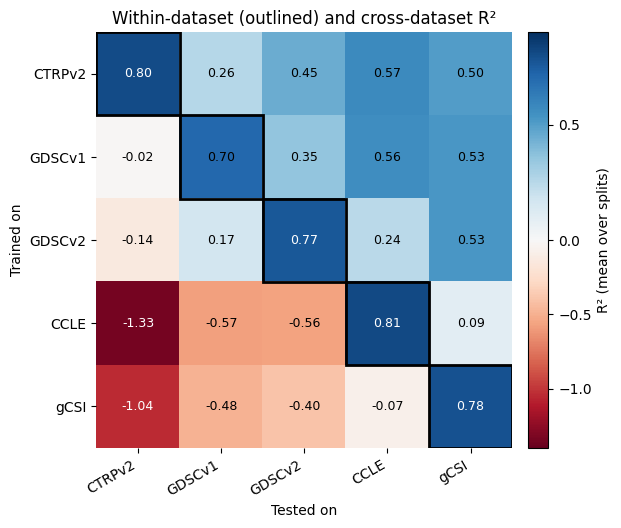

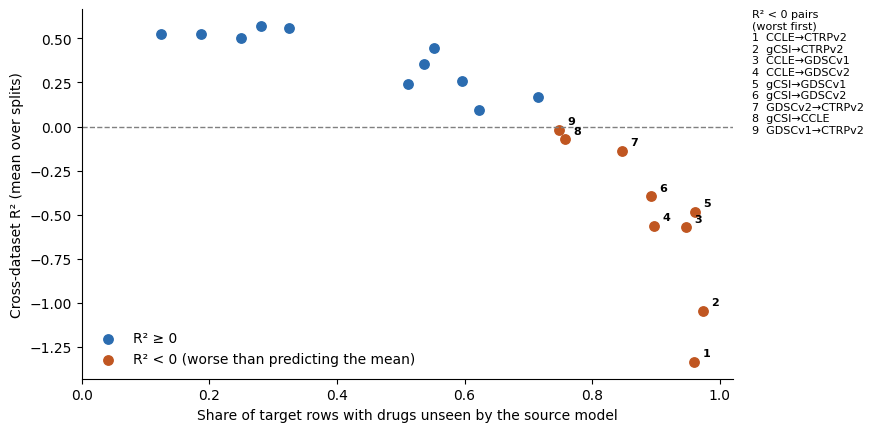

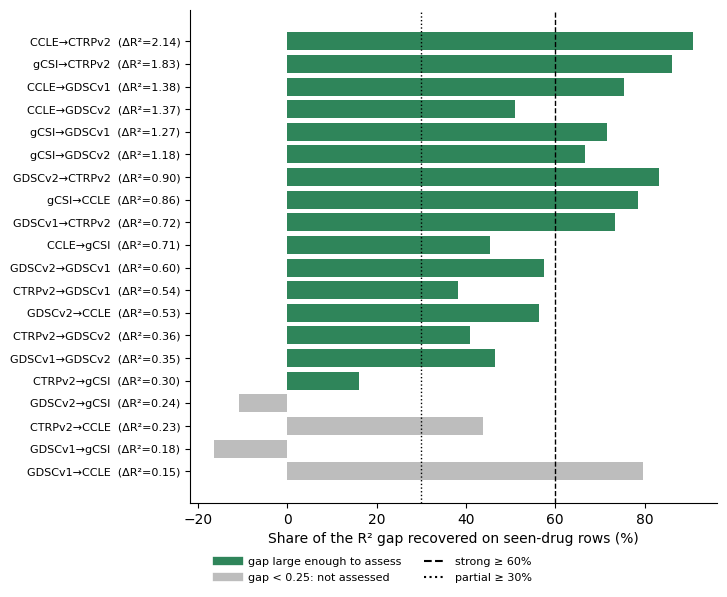

Saved figures: ['fig_gap_recovered.pdf', 'fig_r2_matrix.pdf', 'fig_unseen_vs_r2.pdf']
Saved tables : ['table_pairs.csv', 'table_pairs.tex', 'table_validation.csv', 'table_validation.tex']


In [15]:
import os, json, re
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib; import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D

WORK_DIR = Path(os.environ.get("DRP_WORK", "/kaggle/working")); OUT_DIR = WORK_DIR / "outputs"
EV_DIR, AG_DIR, FIG_DIR, TAB_DIR = OUT_DIR / "evidence", OUT_DIR / "agent", OUT_DIR / "figures", OUT_DIR / "tables"
FIG_DIR.mkdir(exist_ok=True); TAB_DIR.mkdir(exist_ok=True)
names = ["CTRPv2", "GDSCv1", "GDSCv2", "CCLE", "gCSI"]

ev = pd.read_csv(EV_DIR / "evidence_per_pair.csv")
st = pd.read_csv(AG_DIR / "diagnosis_status_table.csv")
J = json.load(open(AG_DIR / "diagnosis_claims.json")); R = J["rules"]
st[["source", "target"]] = st["pair"].str.split(r"\s*->\s*", expand=True)
ev = ev.merge(st[["source", "target", "primary", "classification"]], on=["source", "target"], how="left")

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, stem):
    for ext in ("png", "pdf", "svg"):
        fig.savefig(FIG_DIR / f"{stem}.{ext}", dpi=300, bbox_inches="tight")
    plt.show()

# ---------- Figure A: 5x5 mean R2 matrix (rows = trained on, columns = tested on) ----------
M = pd.DataFrame(np.nan, index=names, columns=names)
for r in ev.itertuples(): M.loc[r.source, r.target] = r.r2_cross_mean
for s, g in ev.groupby("source"): M.loc[s, s] = g.r2_within_mean.iloc[0]
SD = None
f = OUT_DIR / "all_scores_long.csv"
if f.exists():
    S = pd.read_csv(f); SD = S.groupby(["source", "target"])["r2"].std().unstack().reindex(index=names, columns=names)
fig, ax = plt.subplots(figsize=(6.6, 5.4))
im = ax.imshow(M.values.astype(float), cmap="RdBu", norm=TwoSlopeNorm(vmin=-1.4, vcenter=0, vmax=0.9))
ax.set_xticks(range(5)); ax.set_xticklabels(names, rotation=30, ha="right"); ax.set_yticks(range(5)); ax.set_yticklabels(names)
ax.set_xlabel("Tested on"); ax.set_ylabel("Trained on")
for i in range(5):
    for j in range(5):
        v = M.values[i, j]; txt = f"{v:.2f}" + (f"\n±{SD.values[i, j]:.2f}" if SD is not None and not np.isnan(SD.values[i, j]) else "")
        ax.text(j, i, txt, ha="center", va="center", fontsize=9, color="white" if abs(v) > 0.75 else "black")
    ax.add_patch(plt.Rectangle((i - .5, i - .5), 1, 1, fill=False, ec="black", lw=2))
ax.spines[:].set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03); cb.set_label("R² (mean over splits)")
ax.set_title("Within-dataset (outlined) and cross-dataset R²")
save(fig, "fig_r2_matrix")

# ---------- Figure B: share of unseen drugs vs cross-dataset R2 ----------
fail = ev.r2_cross_mean < 0
fig, ax = plt.subplots(figsize=(8.4, 4.8))
ax.axhline(0, color="grey", lw=1, ls="--")
ax.scatter(ev.share_unseen_drug_mean[~fail], ev.r2_cross_mean[~fail], s=46, color="#2B6CB0", label="R² ≥ 0")
ax.scatter(ev.share_unseen_drug_mean[fail], ev.r2_cross_mean[fail], s=46, color="#C05621", label="R² < 0 (worse than predicting the mean)")
key_lines = []
for i, r in enumerate(ev[fail].sort_values("r2_cross_mean").itertuples(), 1):
    ax.annotate(str(i), (r.share_unseen_drug_mean, r.r2_cross_mean), xytext=(6, 4), textcoords="offset points", fontsize=8, fontweight="bold")
    key_lines.append(f"{i}  {r.source}→{r.target}")
ax.text(1.03, 1.0, "R² < 0 pairs\n(worst first)\n" + "\n".join(key_lines), transform=ax.transAxes, va="top", fontsize=8)
ax.set_xlabel("Share of target rows with drugs unseen by the source model"); ax.set_ylabel("Cross-dataset R² (mean over splits)")
ax.legend(frameon=False, loc="lower left"); ax.set_xlim(0, 1.02)
save(fig, "fig_unseen_vs_r2")

# ---------- Figure C: share of the gap recovered when only seen drugs are scored ----------
d = ev.sort_values("r2_gap_mean", ascending=True).reset_index(drop=True)
assessed = d.r2_gap_mean >= R["min_gap_for_ratio"]
fig, ax = plt.subplots(figsize=(6.8, 6.4))
ax.barh(range(len(d)), 100 * d.share_gap_closed_mean, color=np.where(assessed, "#2F855A", "#BDBDBD"))
ax.axvline(100 * R["closed_strong"], color="black", ls="--", lw=1); ax.axvline(100 * R["closed_moderate"], color="black", ls=":", lw=1)
ax.set_yticks(range(len(d))); ax.set_yticklabels([f"{a}→{b}  (ΔR²={g:.2f})" for a, b, g in zip(d.source, d.target, d.r2_gap_mean)], fontsize=8)
ax.set_xlabel("Share of the R² gap recovered on seen-drug rows (%)")
ax.legend(handles=[Line2D([], [], color="#2F855A", lw=6, label="gap large enough to assess"),
                   Line2D([], [], color="#BDBDBD", lw=6, label=f"gap < {R['min_gap_for_ratio']:.2f}: not assessed"),
                   Line2D([], [], color="black", ls="--", label=f"strong ≥ {100*R['closed_strong']:.0f}%"),
                   Line2D([], [], color="black", ls=":", label=f"partial ≥ {100*R['closed_moderate']:.0f}%")], frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.35, -0.09), ncol=2)
save(fig, "fig_gap_recovered")

# ---------- Tables (CSV + LaTeX) ----------
t1 = ev.sort_values("r2_gap_mean", ascending=False)[["source", "target", "r2_within_mean", "r2_cross_mean", "r2_gap_mean",
        "share_unseen_drug_mean", "r2_drug_seen_mean", "share_gap_closed_mean", "primary"]].copy()
t1.columns = ["Source", "Target", "R² within", "R² cross", "ΔR²", "Unseen drugs", "R² seen drugs", "Gap recovered", "Primary explanation"]
t1["Primary explanation"] = t1["Primary explanation"].astype(str).str.replace("_", " ")
for c in ("Unseen drugs", "Gap recovered"): t1[c] = (100 * t1[c]).round(0).astype(int).astype(str) + "%"
t1.to_csv(TAB_DIR / "table_pairs.csv", index=False)
open(TAB_DIR / "table_pairs.tex", "w").write(t1.to_latex(index=False, float_format="%.2f", escape=True,
    caption="Cross-dataset performance, drug coverage and primary explanation for the 20 source-target pairs (mean over 5 splits).", label="tab:pairs"))
vc = pd.read_csv(AG_DIR / "validation_checks.csv")
vc.to_csv(TAB_DIR / "table_validation.csv", index=False)
open(TAB_DIR / "table_validation.tex", "w").write(vc.to_latex(index=False, escape=True, caption="Validation checks of the rule engine.", label="tab:validation"))
print("Saved figures:", sorted(p.name for p in FIG_DIR.glob("fig_*.pdf")))
print("Saved tables :", sorted(p.name for p in TAB_DIR.iterdir()))

## 36. Numbers and draft text for the paper

**Purpose.** Compute every headline number from the saved files and write a draft Results and Limitations text in which
all numbers are filled in automatically, so the paper cannot disagree with the data. Edit the wording, not the numbers.

**Inputs.** `evidence/evidence_per_pair.csv`, `agent/diagnosis_status_table.csv`, `agent/validation_checks.csv`, `agent/diagnosis_claims.json`.
**Outputs.** `agent/paper_numbers.json`, `agent/paper_text_draft.md` (also printed below).


In [16]:
import os, json, re
from pathlib import Path
import numpy as np, pandas as pd
WORK_DIR = Path(os.environ.get("DRP_WORK", "/kaggle/working")); OUT_DIR = WORK_DIR / "outputs"
EV_DIR, AG_DIR = OUT_DIR / "evidence", OUT_DIR / "agent"

ev = pd.read_csv(EV_DIR / "evidence_per_pair.csv")
st = pd.read_csv(AG_DIR / "diagnosis_status_table.csv")
vc = pd.read_csv(AG_DIR / "validation_checks.csv")
R = json.load(open(AG_DIR / "diagnosis_claims.json"))["rules"]

fail = ev[ev.r2_cross_mean < 0]; n = len(ev)
prim = st.primary.value_counts().to_dict()
val = {i: vc.iloc[i] for i in range(len(vc))}
m = re.search(r"accuracy ([\d.]+) \(majority baseline ([\d.]+); ROC-AUC of the share ([\d.]+)\)", str(val[6].failures))
assert m, f"Could not parse the early-warning row of validation_checks.csv: {val[6].failures!r}"
acc, maj, auc = (float(x) for x in m.groups())
chg = str(val[5].failures).split("/"); chg_lo, chg_hi = int(chg[0]), int(chg[1])

N = {"n_pairs": n, "n_fail": len(fail), "n_splits": int(ev.n_splits.iloc[0]),
     "within_r2_min": ev.r2_within_mean.min(), "within_r2_max": ev.r2_within_mean.max(),
     "fail_r2_min": fail.r2_cross_mean.min(), "fail_r2_max": fail.r2_cross_mean.max(),
     "fail_unseen_min": fail.share_unseen_drug_mean.min(), "fail_unseen_max": fail.share_unseen_drug_mean.max(),
     "fail_closed_min": fail.share_gap_closed_mean.min(), "fail_closed_max": fail.share_gap_closed_mean.max(),
     "n_strong": prim.get("drug_coverage_strong", 0), "n_partial": prim.get("drug_coverage_partial", 0),
     "n_small_gap": prim.get("small_gap", 0), "n_unexplained": prim.get("unexplained", 0),
     "warn_acc": acc, "warn_majority": maj, "warn_auc": auc,
     "split_disagree": int(val[4].failures), "split_total": int(val[4]["of"]),
     "thr_changed_low": chg_lo, "thr_changed_high": chg_hi,
     "traceability_failures": int(val[0].failures) + int(val[1].failures) + int(val[2].failures) + int(val[3].failures)}
json.dump({k: (float(v) if isinstance(v, (np.floating, float)) else int(v)) for k, v in N.items()}, open(AG_DIR / "paper_numbers.json", "w"), indent=2)

nonfail = ev[ev.r2_cross_mean >= 0]
if len(nonfail) and N["fail_unseen_min"] > nonfail.share_unseen_drug_mean.max():
    UNSEEN_SENT = (f"Those {N['n_fail']} pairs also had the largest shares of target rows with drugs absent from the source training data "
                   f"({100*N['fail_unseen_min']:.0f}% to {100*N['fail_unseen_max']:.0f}%, against at most {100*nonfail.share_unseen_drug_mean.max():.0f}% for the other pairs).")
else:
    UNSEEN_SENT = (f"The share of target rows with drugs absent from the source training data was {100*N['fail_unseen_min']:.0f}% to {100*N['fail_unseen_max']:.0f}% for these pairs "
                   f"(other pairs up to {100*nonfail.share_unseen_drug_mean.max():.0f}%).")
PASS_SENT = ("All {n} narratives passed the traceability checks and the status of every claim matched an independent re-implementation."
             if N["traceability_failures"] == 0 else
             "The validation found {k} traceability or re-implementation failures (see validation_checks.csv); fix these before submitting.")
PASS_SENT = PASS_SENT.format(n=N["n_pairs"], k=N["traceability_failures"])
text = f"""# Draft results and limitations text (numbers are generated from the saved files; edit the wording, not the numbers)

## Results: generalisation gap
Models reached within-dataset R² between {N['within_r2_min']:.2f} and {N['within_r2_max']:.2f} (mean over {N['n_splits']} splits). Across the {N['n_pairs']} source-target pairs,
{N['n_fail']} had a cross-dataset R² below zero, that is, worse than predicting the target dataset's mean response (R² from {N['fail_r2_min']:.2f} to {N['fail_r2_max']:.2f}).
{UNSEEN_SENT}

## Results: counterfactual
When evaluation was restricted to target rows with drugs seen in training, {100*N['fail_closed_min']:.0f}% to {100*N['fail_closed_max']:.0f}% of the R² gap was recovered for the {N['n_fail']} failing pairs.
Under the rule engine, drug coverage was the primary explanation, with a strong effect in {N['n_strong']} pairs and a partial effect in {N['n_partial']} pairs;
{N['n_small_gap']} pairs had a gap too small to assess, and {N['n_unexplained']} pair was not explained by the measured diagnostics. This is a statement about what the measured diagnostics account for, not a causal proof.

## Results: validation
{PASS_SENT}
Across splits, the drug-coverage class derived from the other splits disagreed with the held-out split in {N['split_disagree']} of {N['split_total']} cases (the splits share one dataset, so this shows stability, not independent confirmation).
Changing all thresholds by -20% / +20% altered the primary explanation of {N['thr_changed_low']} / {N['thr_changed_high']} of {N['n_pairs']} pairs.
A label-free flag based on the share of unseen drugs predicted whether a pair would fail with leave-one-source-out accuracy {N['warn_acc']:.2f} (always predicting the majority class: {N['warn_majority']:.2f}; ROC-AUC of the share: {N['warn_auc']:.2f}).

## Limitations
- Results are means over {N['n_splits']} of the benchmark's 10 splits; the 10-split protocol was not run, and the spread reflects training-split variation only.
- One model family (XGBoost) with untuned hyperparameters; the CTRPv2 model reached the tree cap in every split.
- The {N['n_pairs']} pairs are not independent (each dataset appears several times as source and target), so the early-warning and threshold results are indicative only and any statistics across pairs are descriptive.
- Seen and unseen subsets contain different drugs, so part of the difference may reflect drug difficulty; seen-drug R² is computed on a restricted subset.
- The rule-engine thresholds are choices; the primary explanation of {N['thr_changed_low']} pairs changes when they are lowered by 20% and of {N['thr_changed_high']} pairs when raised by 20%.
- SHAP and domain-classifier analyses were run on split 0 only. Assay protocols were not examined directly, only the resulting AUC values.
"""
(AG_DIR / "paper_text_draft.md").write_text(text)
print(text)

# Draft results and limitations text (numbers are generated from the saved files; edit the wording, not the numbers)

## Results: generalisation gap
Models reached within-dataset R² between 0.70 and 0.81 (mean over 5 splits). Across the 20 source-target pairs,
9 had a cross-dataset R² below zero, that is, worse than predicting the target dataset's mean response (R² from -1.33 to -0.02).
Those 9 pairs also had the largest shares of target rows with drugs absent from the source training data (75% to 97%, against at most 72% for the other pairs).

## Results: counterfactual
When evaluation was restricted to target rows with drugs seen in training, 51% to 91% of the R² gap was recovered for the 9 failing pairs.
Under the rule engine, drug coverage was the primary explanation, with a strong effect in 8 pairs and a partial effect in 7 pairs;
4 pairs had a gap too small to assess, and 1 pair was not explained by the measured diagnostics. This is a statement about what the measured diagnostics

## 37. Repository export and final download

**Purpose.** Collect code, results, figures and tables into one `repo/` folder with a README and `requirements.txt`
(package versions as installed), and zip it as `final_submission.zip`. Models and predictions are excluded because of their size.

**Before publishing.** Fill the `<PLACEHOLDERS>` in `README.md` (title, authors, DOI, notebook file name, licence).
**Output.** `/kaggle/working/final_submission.zip`, with a download link.

In [17]:
import os, json, shutil, zipfile, platform
from pathlib import Path
from importlib import metadata

WORK_DIR = Path(os.environ.get("DRP_WORK", "/kaggle/working")); OUT_DIR = WORK_DIR / "outputs"
AG_DIR, EV_DIR, FIG_DIR, TAB_DIR = OUT_DIR / "agent", OUT_DIR / "evidence", OUT_DIR / "figures", OUT_DIR / "tables"
REPO = WORK_DIR / "repo"
if REPO.exists(): shutil.rmtree(REPO)
for sub in ("code", "results/evidence", "results/agent", "results/diagnostics", "results/tables", "figures"): (REPO / sub).mkdir(parents=True)

# ---- code and results (small files only; models and predictions are excluded) ----
f = WORK_DIR / "drp_setup.py"
if f.exists(): shutil.copy(f, REPO / "code" / f.name)
for src, dst in ((EV_DIR, "results/evidence"), (AG_DIR, "results/agent"), (OUT_DIR / "diagnostics", "results/diagnostics"), (TAB_DIR, "results/tables")):
    if src.exists():
        for p in src.glob("*"):
            if p.is_file() and p.stat().st_size < 50e6: shutil.copy(p, REPO / dst / p.name)
for p in FIG_DIR.glob("fig_*"): shutil.copy(p, REPO / "figures" / p.name)
for p in OUT_DIR.glob("*_5split.csv"): shutil.copy(p, REPO / "results" / p.name)
if (OUT_DIR / "all_scores_long.csv").exists(): shutil.copy(OUT_DIR / "all_scores_long.csv", REPO / "results" / "all_scores_long.csv")

# ---- narratives for the supplement ----
try:
    J = json.load(open(AG_DIR / "diagnosis_claims.json"))
    md = ["# Evidence-linked diagnosis for each source -> target pair\n"]
    for d in J["pairs"]: md.append(f"## {d['source']} -> {d['target']}\n\n{d['narrative']}\n")
    (REPO / "results" / "narratives.md").write_text("\n".join(md))
except Exception as e:
    print("Narratives not written:", repr(e))

# ---- requirements with the versions actually used ----
pk = ["numpy", "pandas", "scipy", "scikit-learn", "xgboost", "matplotlib", "shap", "pyarrow", "rdkit", "psutil"]
req = []
for p in pk:
    try: req.append(f"{p}=={metadata.version(p)}")
    except metadata.PackageNotFoundError: pass
(REPO / "requirements.txt").write_text("\n".join(req) + "\n")

# ---- README (edit the placeholders before publishing) ----
readme = f"""# Why do drug-response models fail across datasets? Diagnosing cross-dataset generalisation

Code and results for the paper "<TITLE>" (<AUTHORS>). <DOI / ARXIV LINK>

## What this repository contains
- `code/drp_setup.py`: shared setup (downloads and verifies the benchmark data, restores saved results, defines the feature builder and scorer).
- `results/`: per-pair evidence table (`evidence/`), rule-engine output and validation (`agent/`), diagnostic CSVs (`diagnostics/`), table sources (`tables/`), 5-split score matrices.
- `figures/`: figures used in the paper (PNG, PDF, SVG).
- The analysis notebook (`<NOTEBOOK FILE NAME>.ipynb`) is the full record of how every file was produced.

## Data
Benchmark data: Partin et al., Zenodo record 15258451 (`csa_data.zip`, MD5 984eabec912914e62d56d8e0073475f8). It is downloaded and verified automatically by `drp_setup.py`; it is not redistributed here.

## Method in one paragraph
One XGBoost model is trained per source dataset (CTRPv2, GDSCv1, GDSCv2, CCLE, gCSI) on the 1,000 most variable gene-expression features and Mordred drug descriptors, for splits 0 to 4 of the benchmark's predefined splits. Each model is evaluated on all five datasets. The loss of
performance from within-dataset to cross-dataset testing (delta R2) is related to drug coverage (seen/unseen-drug counterfactual), response agreement on shared drug-cell pairs, drug novelty and ensemble disagreement. A deterministic rule engine (no language model) turns these measurements into evidence-linked explanations, which are
validated for traceability, independence of implementation, stability across splits and thresholds, and label-free early-warning value.

## Reproducing
1. Run the notebook top to bottom on a machine with a GPU (the results were produced on Kaggle GPUs), or run `drp_setup.py` and the notebook sections in order.
2. All random seeds are fixed (`SEED = 42`). Small differences in GPU-computed values between runs are possible.
3. Software versions are in `requirements.txt` (Python {platform.python_version()}).

## Limitations
See `results/agent/paper_text_draft.md` and `results/evidence/evidence_per_pair.json` ("limitations"). In brief: 5 of 10 splits; one model family; the 20 pairs are not independent; the drug-coverage analysis describes
what the measured diagnostics account for and is not a causal proof.

## Licence and citation
<LICENCE: choose one, e.g. MIT for code and CC BY 4.0 for results>. Please cite the paper and the benchmark data.
"""
(REPO / "README.md").write_text(readme)

# ---- one zip to download ----
zp = WORK_DIR / "final_submission.zip"
with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
    for p in REPO.rglob("*"):
        if p.is_file(): z.write(p, p.relative_to(REPO.parent))
n = sum(1 for p in REPO.rglob("*") if p.is_file())
print(f"{n} files in {REPO}; zip: {zp} ({zp.stat().st_size/1e6:.1f} MB)")
try:
    from IPython.display import FileLink, display; display(FileLink(str(zp)))
except Exception: pass

40 files in /kaggle/working/repo; zip: /kaggle/working/final_submission.zip (0.7 MB)


/kaggle/working/final_submission.zip